In [ ]:
from datetime import datetime
from getpass import getpass

rdm_url = 'https://bh.rdm.yzwlab.com/' # 'https://staging.rdm.example.com'
idp_name_1 = None # 'GakuNin RDM IdP'
idp_username_1 = None
idp_password_1 = None
rdm_project_name = 'TEST-METADATA-{}'.format(datetime.now().strftime('%Y%m%d-%H%M%S'))
default_result_path = None
close_on_fail = False
transition_timeout = 10000
delete_project = True


In [3]:
if idp_username_1 is None:
    idp_username_1 = input(prompt=f'Username for {idp_name_1}')
if idp_password_1 is None:
    idp_password_1 = getpass(prompt=f'Password for {idp_username_1}@{idp_name_1}')
(len(idp_username_1), len(idp_password_1))

(7, 16)

In [4]:
import tempfile

work_dir = tempfile.mkdtemp()
if default_result_path is None:
    default_result_path = work_dir
work_dir

'/tmp/tmpysqin790'

# e-Rad情報を用いた自動補完

- サブシステム名: アドオン
- ページ/アドオン: Metadata
- 機能分類: メタデータ入力
- シナリオ名: e-Rad情報の設定
- 用意するテストデータ: URL一覧、アカウント(既存ユーザー1: GRDM)
- 事前条件: 「プロジェクトに対するMetadataアドオンの登録」を実施済みであり、e-Radダミーデータが登録済みであること

## ウェブブラウザの新規プライベートウィンドウでGRDMトップページを表示する

GRDMトップページが表示されること

In [5]:
import importlib
import pandas as pd

import scripts.playwright
importlib.reload(scripts.playwright)
import scripts.metadata_v2025
importlib.reload(scripts.metadata_v2025)

from scripts.playwright import *
from scripts import grdm
from scripts.metadata_v2025 import ProjectMetadataForm, FileMetadataForm

await init_pw_context(close_on_fail=close_on_fail, last_path=default_result_path)

('20260323-074855', '/tmp/tmpqm5ltgix')

Start epoch: 1774252135.8071673 seconds


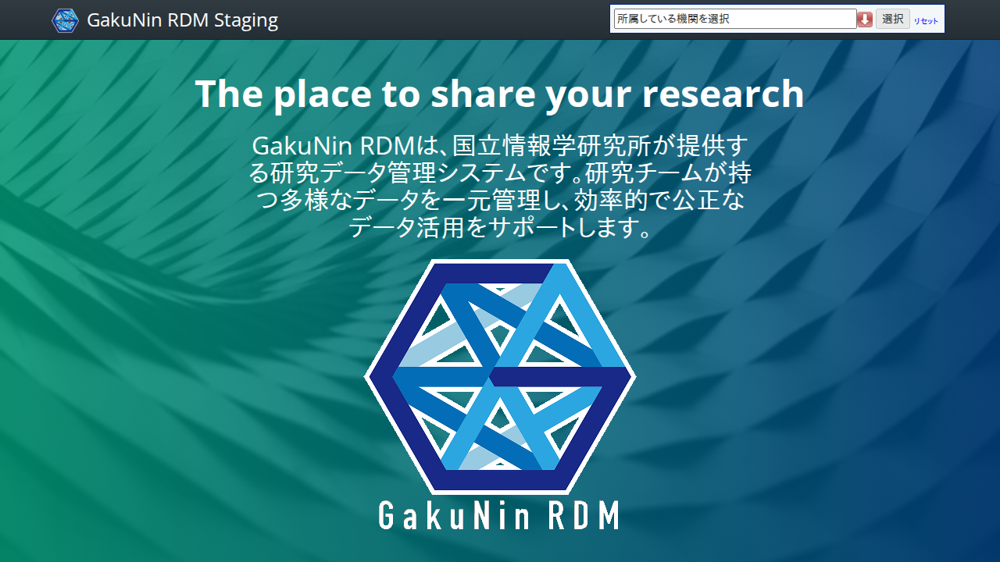

In [6]:
import time

async def _step(page):
    await page.goto(rdm_url)

    # 同意する をクリック
    await page.locator('//button[text() = "同意する"]').click()

    # 同意する が表示されなくなったことを確認
    await expect(page.locator('//button[text() = "同意する"]')).to_have_count(0, timeout=500)

await run_pw(_step)

## ログイン情報を用いてGakuNin RDMにログインする

(IdPに関するログイン情報が与えられた場合、)
GakuNin Embeded DSのプルダウンを展開し、IdPリストから指定されたIdPを選択する。その後、アカウントのID/Passwordを入力して「Login」ボタンを押下する。

(IdPが指定されていない場合、)
CASのログイン操作を実施する。

Start epoch: 1774252139.3991945 seconds


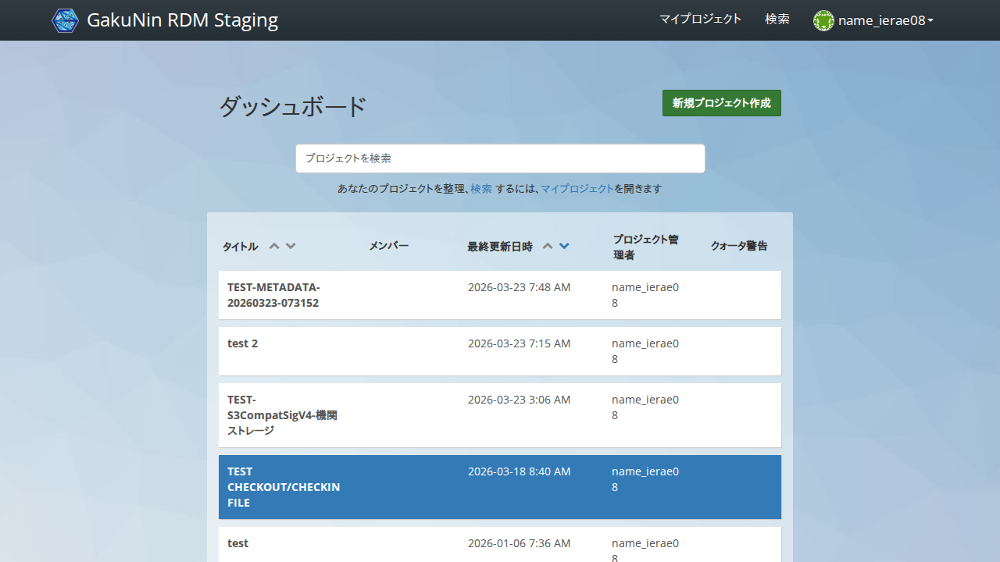

In [7]:
import scripts.grdm
importlib.reload(scripts.grdm)

async def _step(page):
    await scripts.grdm.login(
        page, idp_name_1, idp_username_1, idp_password_1, transition_timeout=transition_timeout
    )

    # GRDMのボタンが表示されることを確認
    await expect(page.locator('//*[text() = "プロジェクト管理者"]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## ログインユーザー表示をクリックする

ドロップダウンに「設定」が現れること

Start epoch: 1774252148.622139 seconds


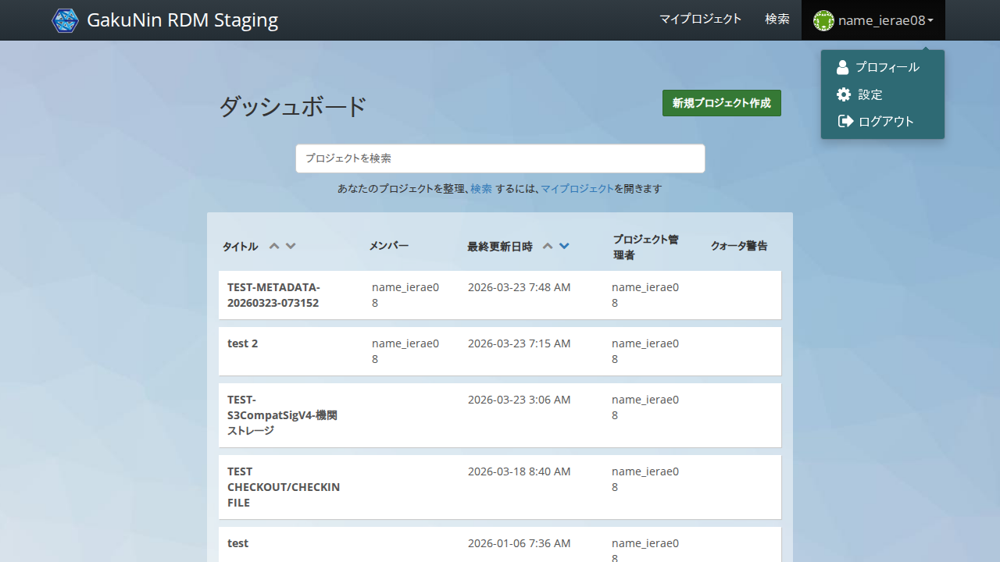

In [8]:
async def _step(page):
    await page.locator(f'//a[@data-test-auth-dropdown-toggle]').click()
    await expect(page.locator(f'//a[@data-test-ad-settings]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「設定」をクリックする

「プロフィール」画面が現れること

Start epoch: 1774252149.7828288 seconds


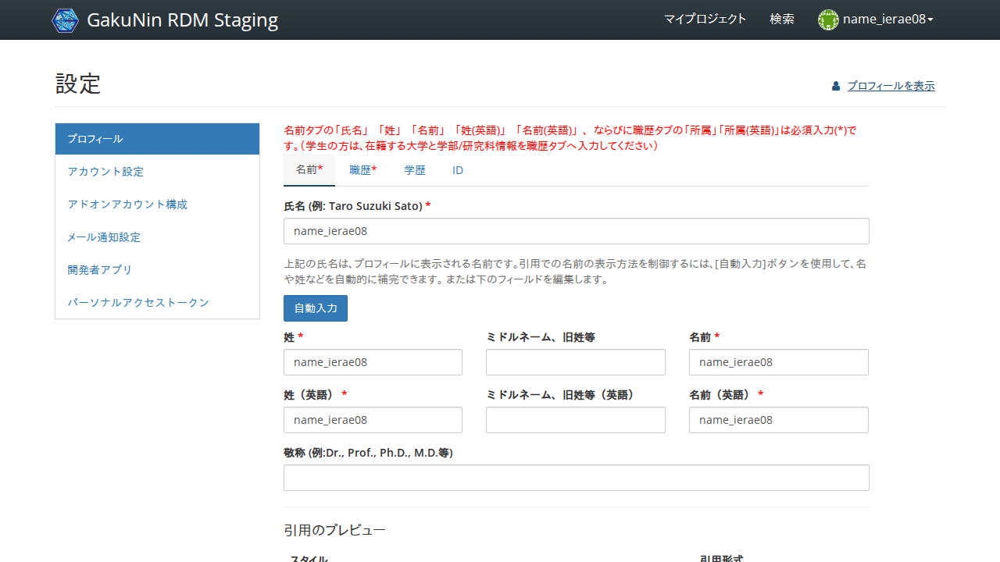

In [9]:
async def _step(page):
    await page.locator(f'//a[@data-test-ad-settings]').click()
    await expect(page.locator(f'//a[text() = "ID"]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「ID」をクリックする

「e-Rad研究者番号」画面が現れること

Start epoch: 1774252151.6403706 seconds


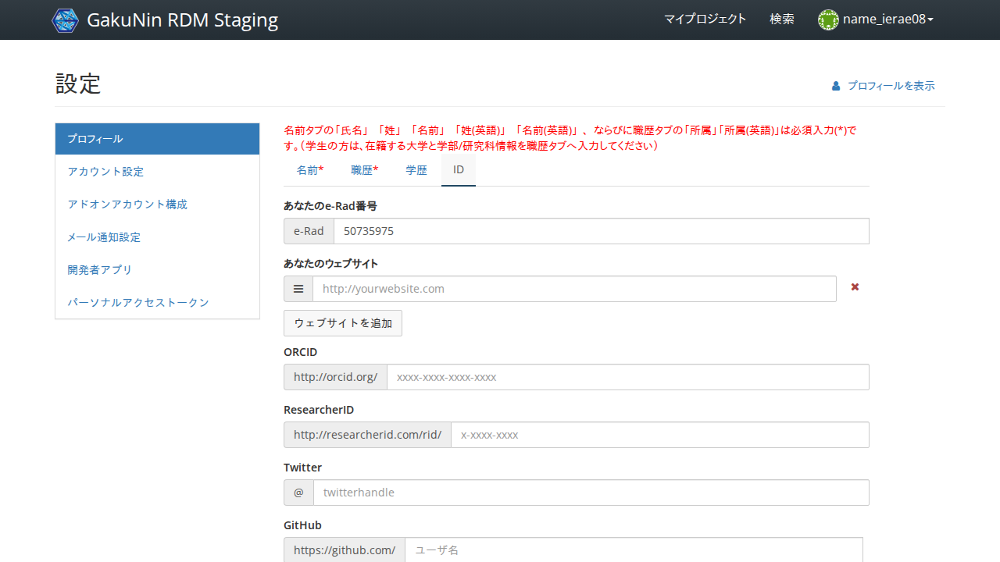

In [10]:
async def _step(page):
    await page.locator(f'//a[text() = "ID"]').click()
    await expect(page.locator(f'//input[@data-bind = "value: erad"]')).to_be_editable(timeout=transition_timeout)

await run_pw(_step)

## 「あなたのe-Rad番号」に「」(空文字列)を入力する

「e-Rad」の項目が空になること

Start epoch: 1774252152.8041449 seconds


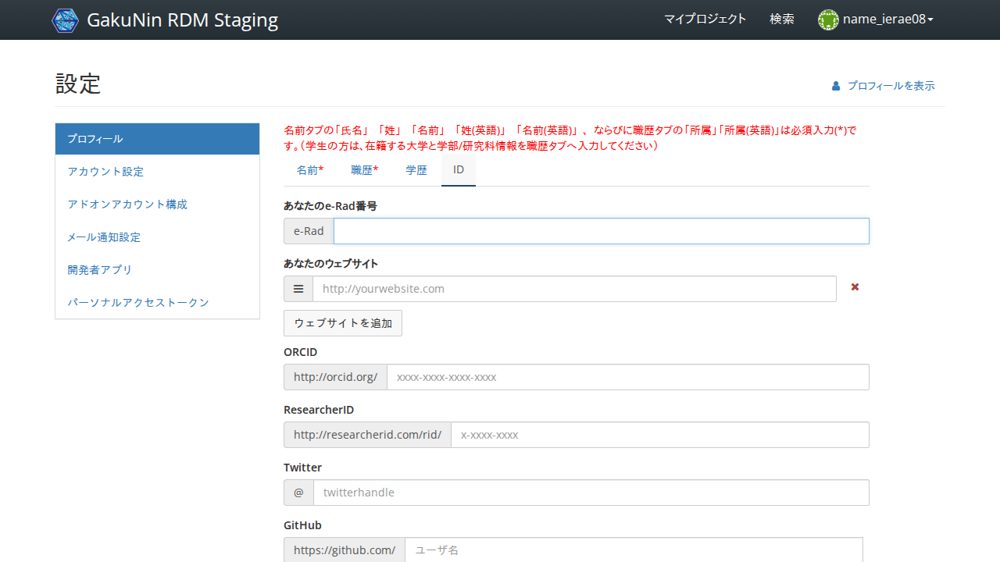

In [11]:
async def _step(page):
    await page.locator(f'//input[@data-bind = "value: erad"]').fill('')
    await expect(page.locator(f'//button[text() = "保存" and ancestor::div[contains(@class,"active")]]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「保存」をクリックする

「設定が更新されました」と緑色で表示されること

Start epoch: 1774252153.9490638 seconds


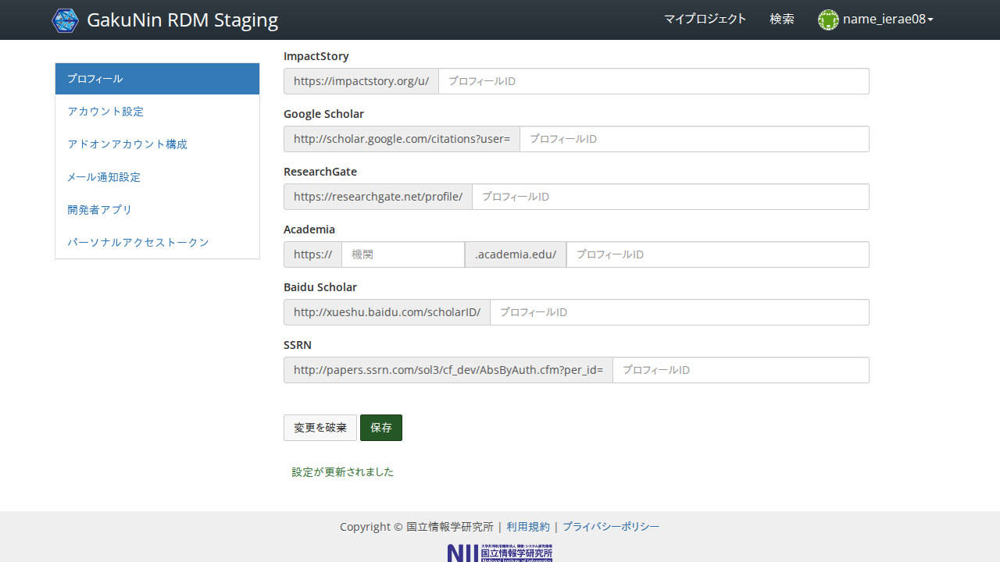

In [12]:
async def _step(page):
    await page.locator(f'//button[text() = "保存" and ancestor::div[contains(@class,"active")]]').click()
    await expect(page.locator(f'//p[contains(@class, "text-success") and contains(text(), "設定が更新されました")]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## ダッシュボードのURLを開く

GRDMダッシュボードが表示されること

Start epoch: 1774252155.232986 seconds


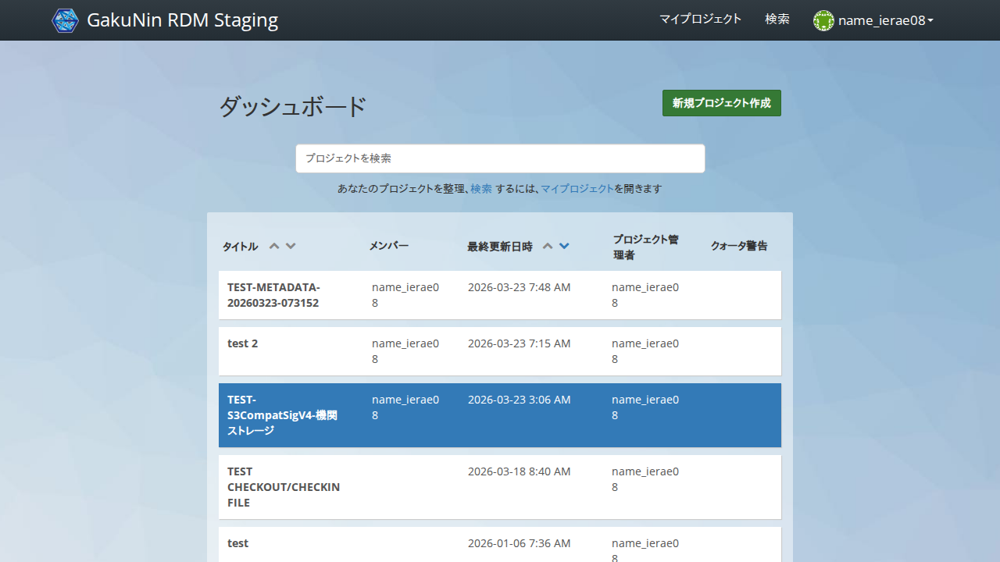

In [13]:
from urllib.parse import urljoin

async def _step(page):
    await page.goto(urljoin(rdm_url, 'dashboard'))
    await scripts.grdm.ensure_project_exists(page, rdm_project_name, transition_timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## ダッシュボードのプロジェクト一覧から作成したプロジェクトをクリックする

作成したプロジェクトのプロジェクトダッシュボードが表示されること

Start epoch: 1774252158.6466942 seconds


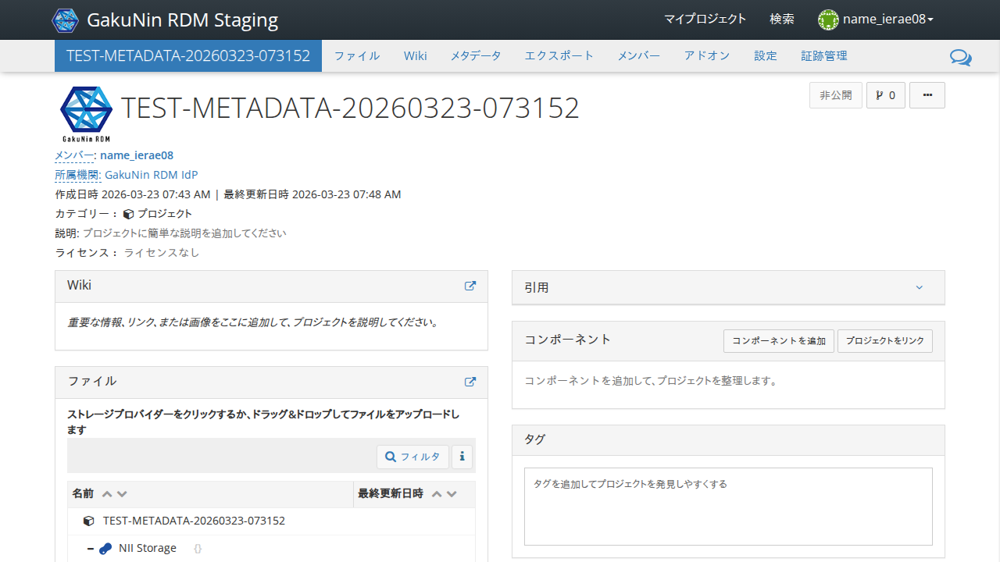

In [14]:
async def _step(page):
    await page.locator(f'//*[@data-test-dashboard-item-title and text() = "{rdm_project_name}"]').click()
    
    await expect(page.locator('//a[text() = "アドオン"]')).to_be_visible(timeout=transition_timeout)
    await expect(page.locator('//*[contains(@class, "title-text")]//*[text() = "NII Storage"]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## プロジェクトダッシュボードの上部メニューから「メタデータ」をクリックする

メタデータの一覧ページが表示されること

Start epoch: 1774252162.1260722 seconds


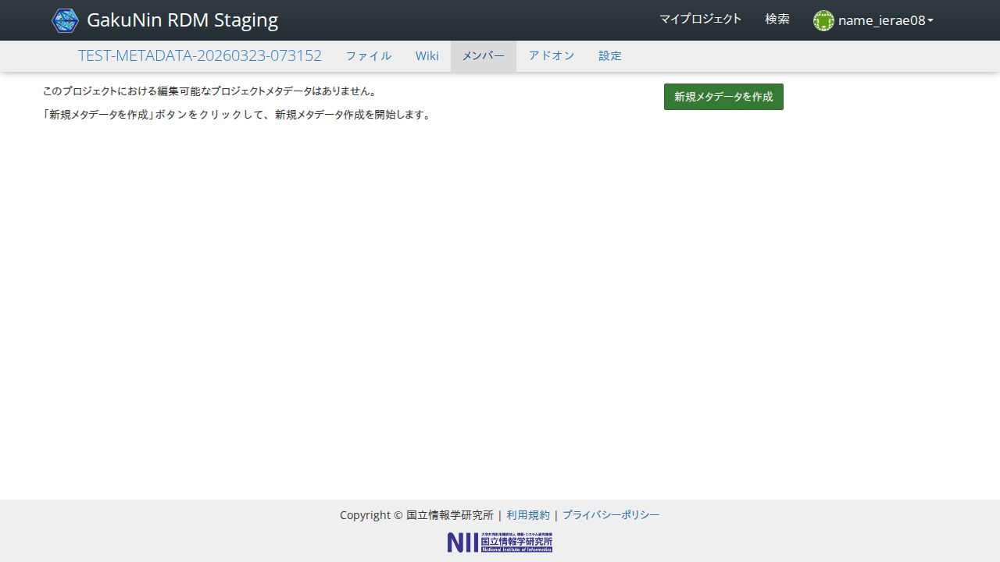

In [15]:
async def _step(page):
    await page.locator('//nav//a[contains(text(), "メタデータ")]').click()
    await expect(page.locator('//*[@data-test-new-metadata-button]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「新規メタデータ」をクリックする

スキーマ選択ダイアログが表示されること

Start epoch: 1774252164.6997538 seconds


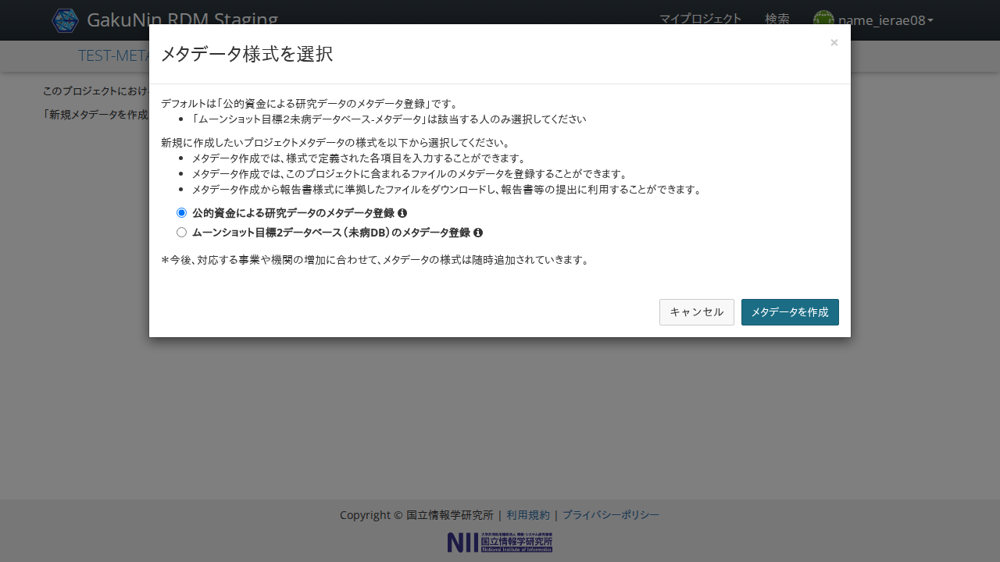

In [16]:
async def _step(page):
    await page.locator('//*[@data-test-new-metadata-button]').click()

    await expect(page.locator('//*[@data-test-new-report-modal-schema="公的資金による研究データのメタデータ登録"]')).to_be_visible(timeout=transition_timeout)
    await expect(page.locator('//*[@data-test-new-report-modal-create-report-button]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「メタデータを作成」をクリックする

メタデータ編集ウィンドウが表示されること

Start epoch: 1774252166.965144 seconds


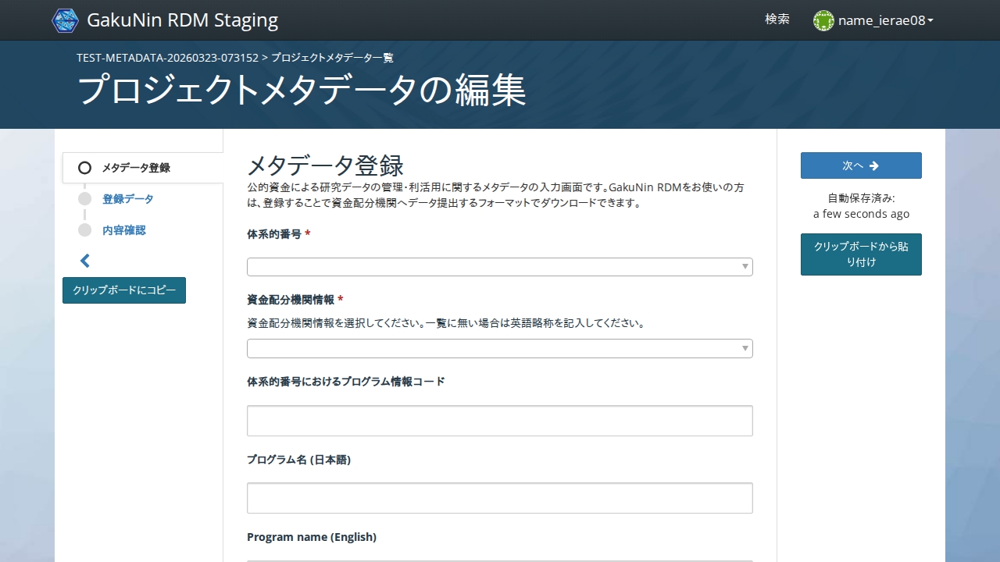

In [17]:
async def _step(page):
    await page.locator('//*[@data-test-new-report-modal-create-report-button]').click()
    
    form = ProjectMetadataForm(page)
    await expect(form.get_locator('資金配分機関情報').locator('.ember-power-select-status-icon')).to_be_attached(timeout=transition_timeout)
    await expect(form.get_locator('体系的番号におけるプログラム情報コード')).to_be_editable(timeout=1000)
    await expect(form.get_locator('プログラム名 (日本語)')).to_be_editable(timeout=1000)
    await expect(form.get_locator('Program name (English)')).to_be_editable(timeout=1000)
    await expect(form.get_locator('体系的番号')).to_be_editable(timeout=1000)
    await expect(form.get_locator('プロジェクト名 (日本語)')).to_be_editable(timeout=1000)
    await expect(form.get_locator('Project name (English)')).to_be_editable(timeout=1000)
    await expect(form.get_locator('プロジェクトの分野').locator('.ember-power-select-status-icon')).to_be_attached(timeout=1000)

await run_pw(_step)

## 「体系的番号」をクリックする

ドロップダウンには補完候補は表示されないこと

Start epoch: 1774252170.1523058 seconds


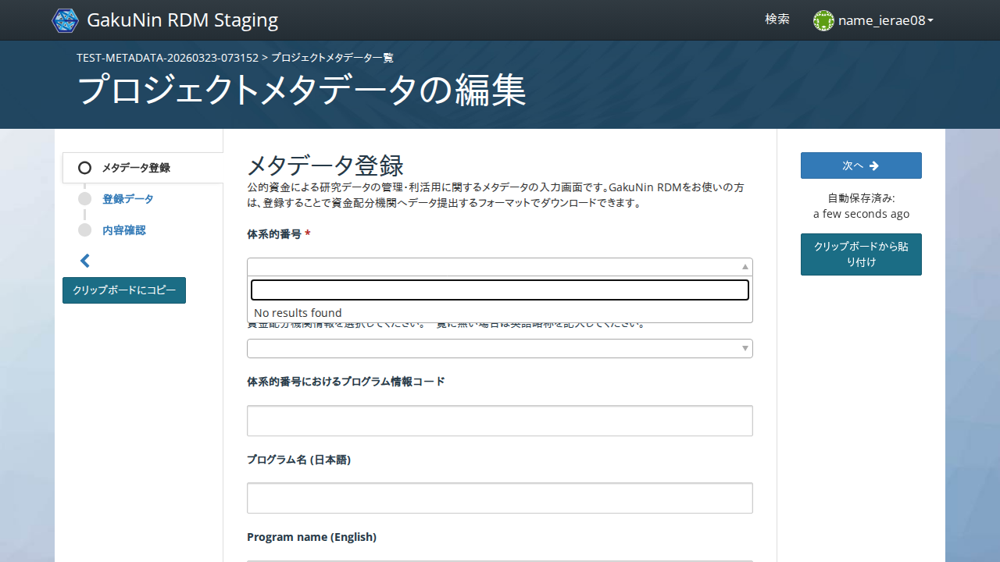

In [18]:
async def _step(page):
    form = ProjectMetadataForm(page)
    locator = form.get_locator('体系的番号')
    await locator.fill('9999')
    await expect(locator).to_have_value('9999', timeout=transition_timeout)
    # 補完候補リストが表示されないことを確認
    time.sleep(1)
    await expect(locator.locator('xpath=..').locator('ul li')).to_have_count(0, timeout=1000)
    await locator.clear()

await run_pw(_step)

## GRDMトップページを表示する

ダッシュボードのプロジェクト一覧に先に作成したプロジェクトが表示されること

Start epoch: 1774252171.4700325 seconds


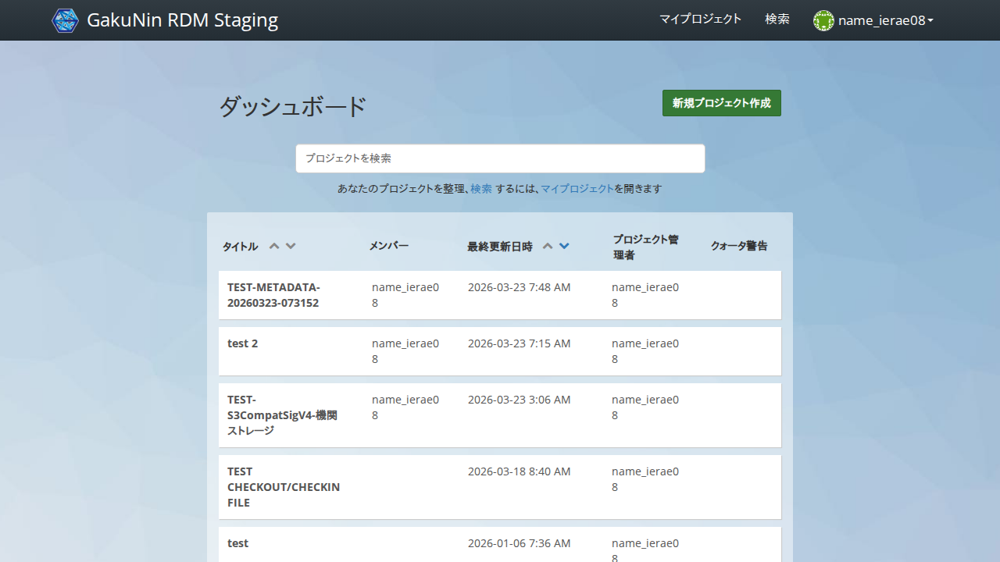

In [19]:
async def _step(page):
    await page.goto(urljoin(rdm_url, 'dashboard'))
    await expect(page.locator(f'//*[@data-test-dashboard-item-title and text() = "{rdm_project_name}"]')).to_be_visible(timeout=30000)
    time.sleep(1)

await run_pw(_step)

## ログインユーザー表示をクリックする

ドロップダウンに「設定」が現れること

Start epoch: 1774252175.2354996 seconds


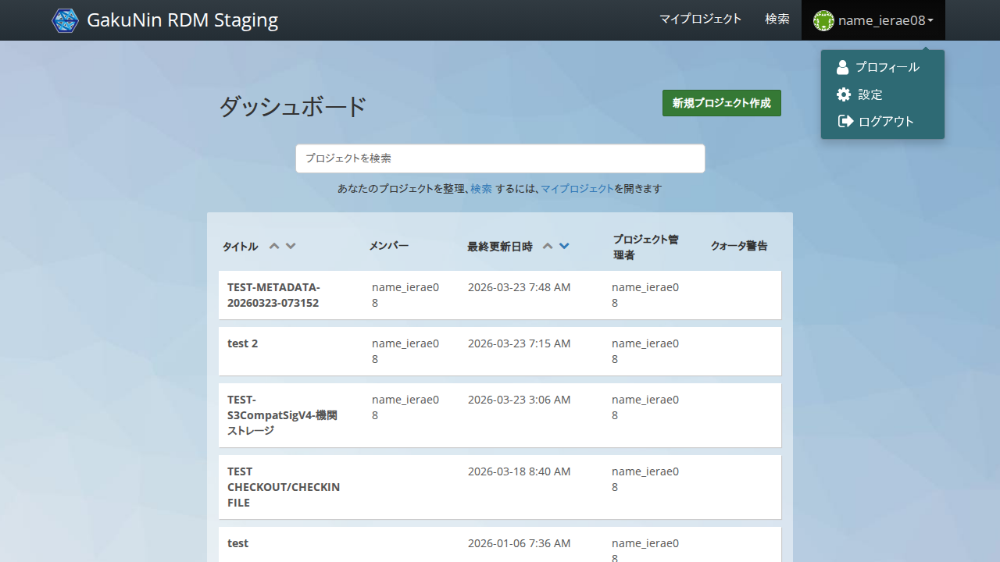

In [20]:
async def _step(page):
    await page.locator(f'//a[@data-test-auth-dropdown-toggle]').click()
    await expect(page.locator(f'//a[@data-test-ad-settings]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「設定」をクリックする

「プロフィール」画面が現れること

Start epoch: 1774252176.4676895 seconds


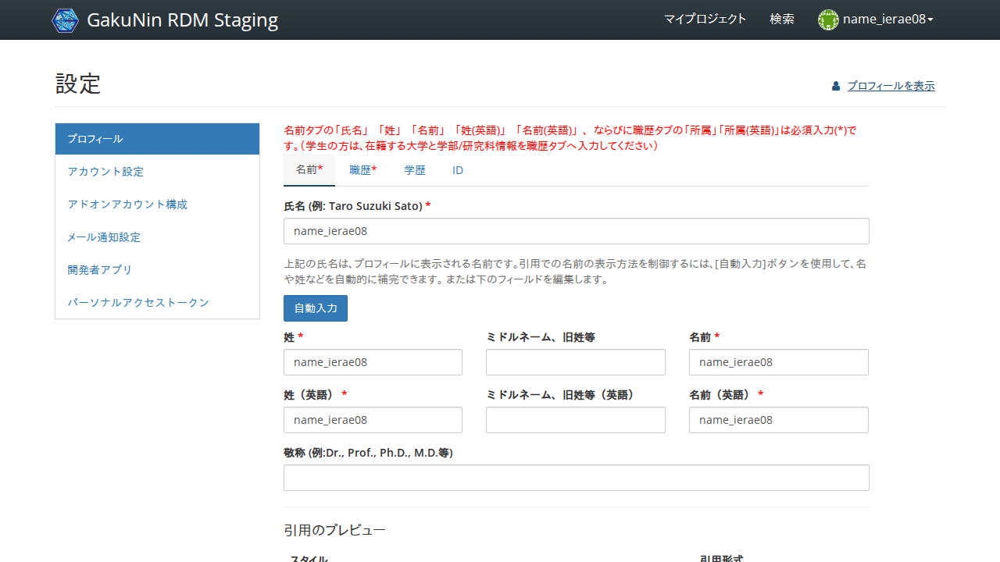

In [21]:
async def _step(page):
    await page.locator(f'//a[@data-test-ad-settings]').click()
    await expect(page.locator(f'//a[text() = "ID"]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「ID」をクリックする

「e-Rad研究者番号」画面が現れること

Start epoch: 1774252178.0025947 seconds


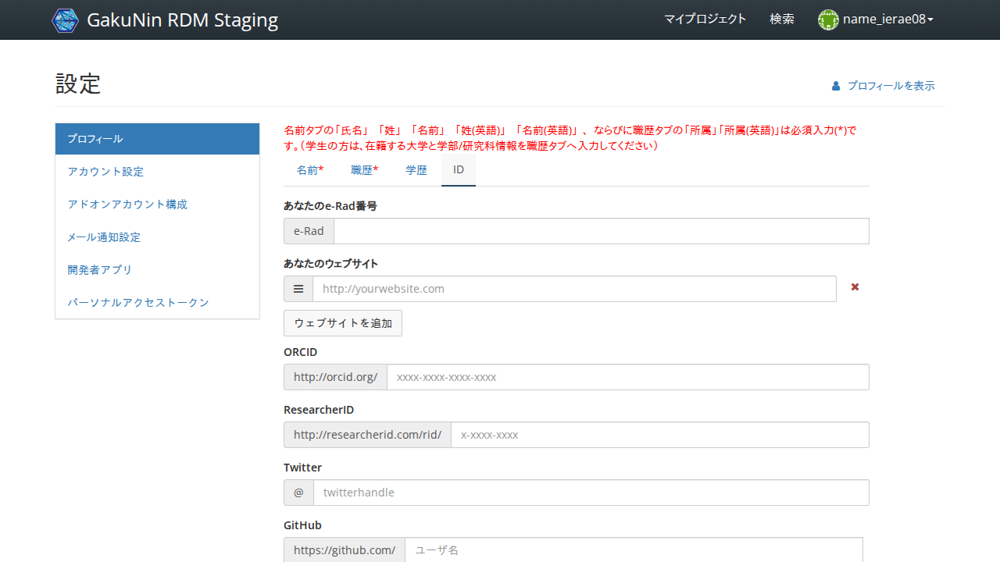

In [22]:
async def _step(page):
    await page.locator(f'//a[text() = "ID"]').click()
    await expect(page.locator(f'//input[@data-bind = "value: erad"]')).to_be_editable(timeout=transition_timeout)

await run_pw(_step)

## 「あなたのe-Rad番号」に「39654540」を入力する

「e-Rad」の項目に「39654540」が表示されること

Start epoch: 1774252179.245827 seconds


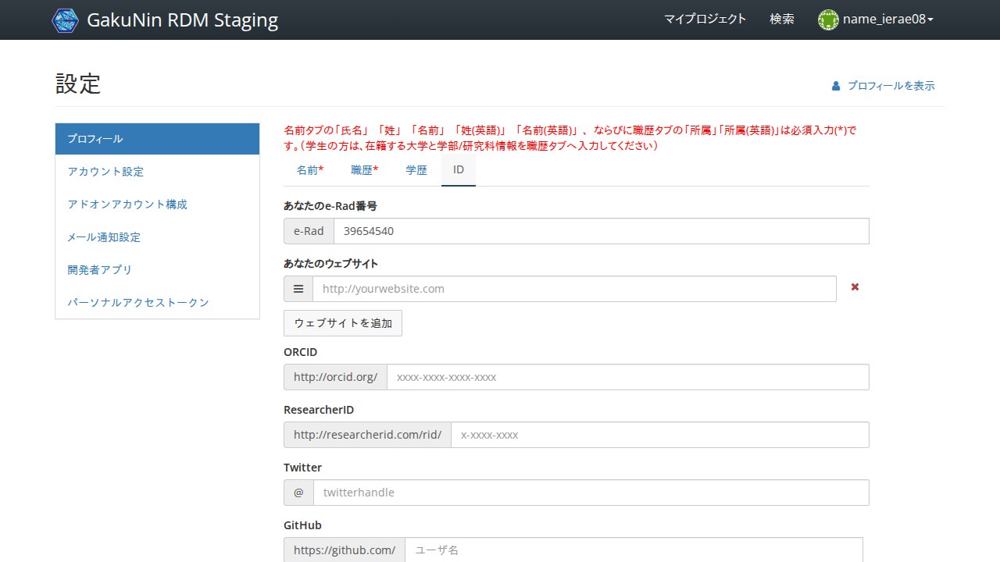

In [23]:
async def _step(page):
    await page.locator(f'//input[@data-bind = "value: erad"]').fill('39654540')
    await expect(page.locator(f'//button[text() = "保存" and ancestor::div[contains(@class,"active")]]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「保存」をクリックする

「設定が更新されました」と緑色で表示されること

Start epoch: 1774252180.4661725 seconds


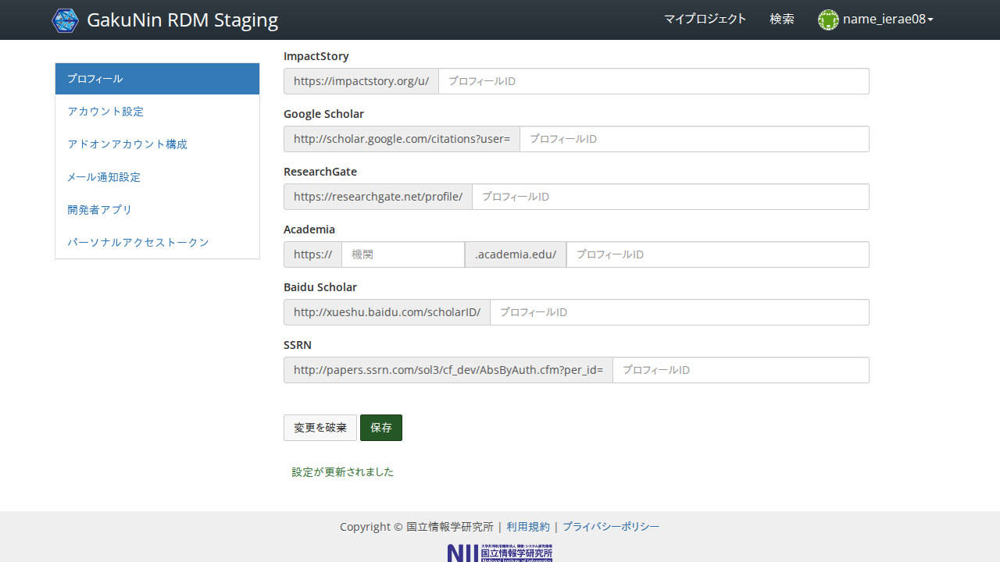

In [24]:
async def _step(page):
    await page.locator(f'//button[text() = "保存" and ancestor::div[contains(@class,"active")]]').click()
    await expect(page.locator(f'//p[contains(@class, "text-success") and contains(text(), "設定が更新されました")]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## ダッシュボードのURLを開く

GRDMダッシュボードが表示されること

Start epoch: 1774252181.8080611 seconds


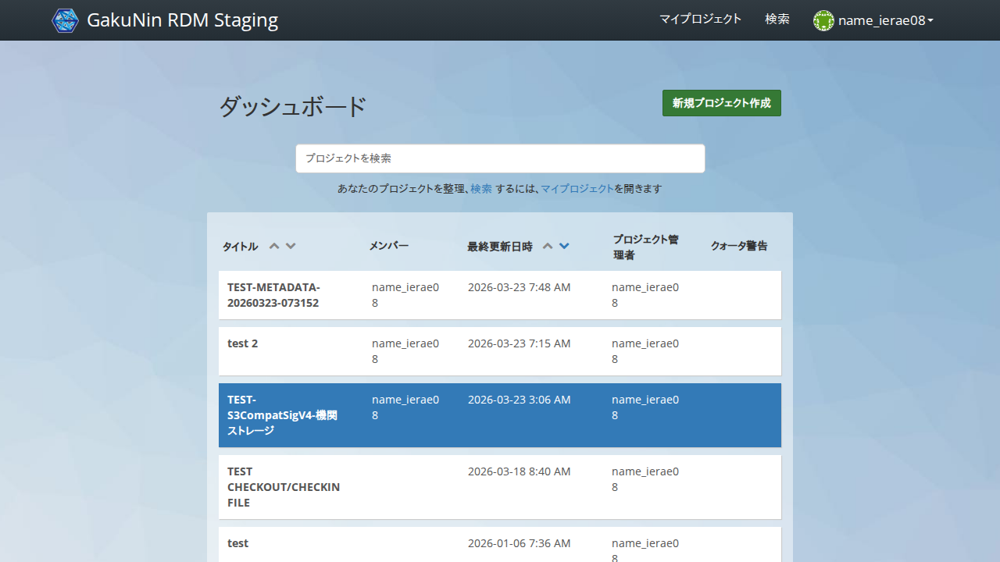

In [25]:
async def _step(page):
    await page.goto(urljoin(rdm_url, 'dashboard'))
    await expect(page.locator(f'//*[@data-test-dashboard-item-title and text() = "{rdm_project_name}"]')).to_be_visible(timeout=30000)
    time.sleep(1)

await run_pw(_step)

## ダッシュボードのプロジェクト一覧から作成したプロジェクトをクリックする

作成したプロジェクトのプロジェクトダッシュボードが表示されること

Start epoch: 1774252185.7881923 seconds


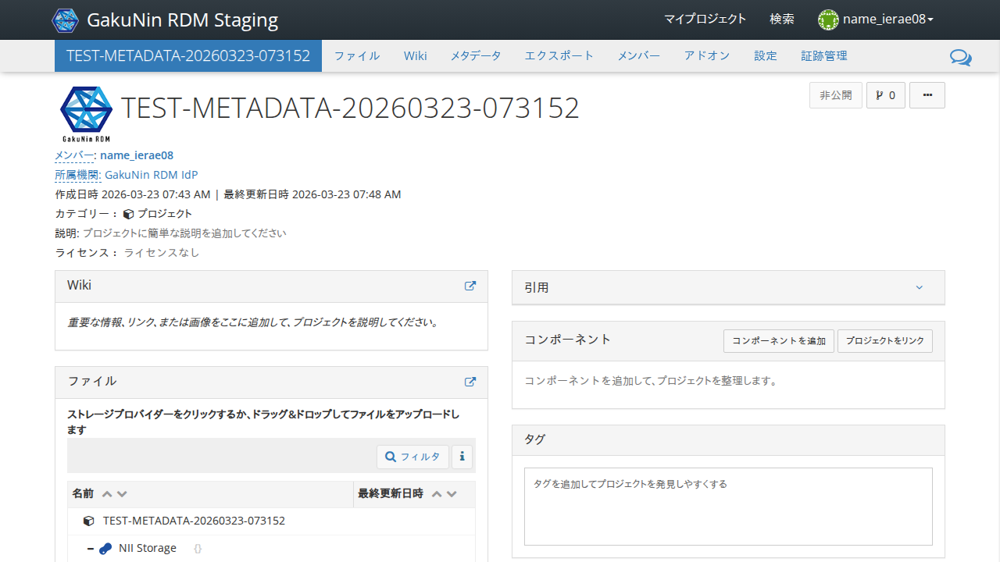

In [26]:
async def _step(page):
    await page.locator(f'//*[@data-test-dashboard-item-title and text() = "{rdm_project_name}"]').click()
    
    await expect(page.locator('//a[text() = "アドオン"]')).to_be_visible(timeout=transition_timeout)
    await expect(page.locator('//*[contains(@class, "title-text")]//*[text() = "NII Storage"]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「NII Storage」をクリックする

「メタデータ編集」ボタンが表示されること (表示まで数秒かかる可能性がある)

Start epoch: 1774252189.2635963 seconds


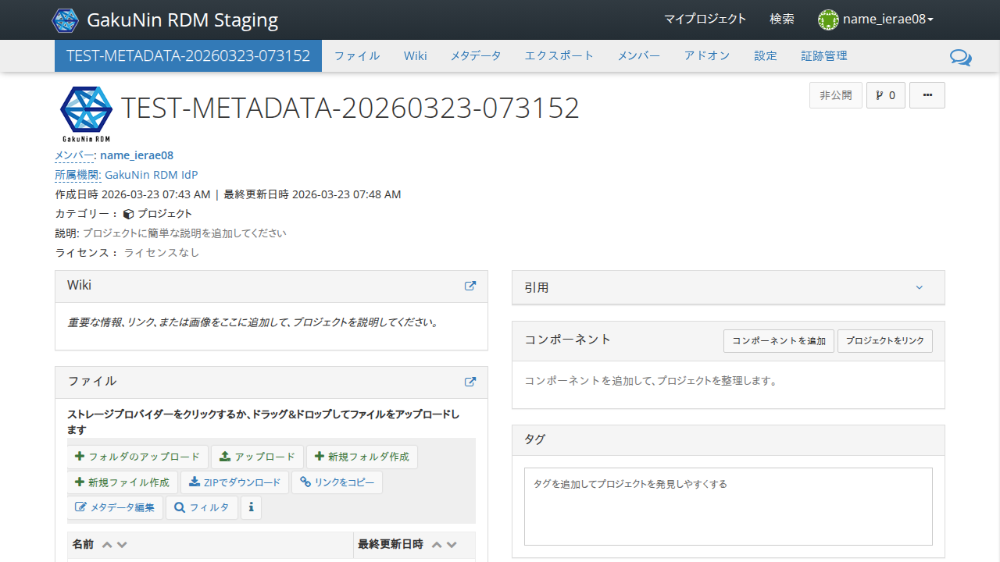

In [27]:
async def _step(page):
    target_storage_name = 'NII Storage'
    await grdm.get_select_expanded_storage_title_locator(page, target_storage_name).click()
    
    await expect(page.locator('//*[text() = "メタデータ編集"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「新規フォルダ作成」をクリックする

フォルダ名入力テキストフィールドが表示されること

Start epoch: 1774252190.5555537 seconds


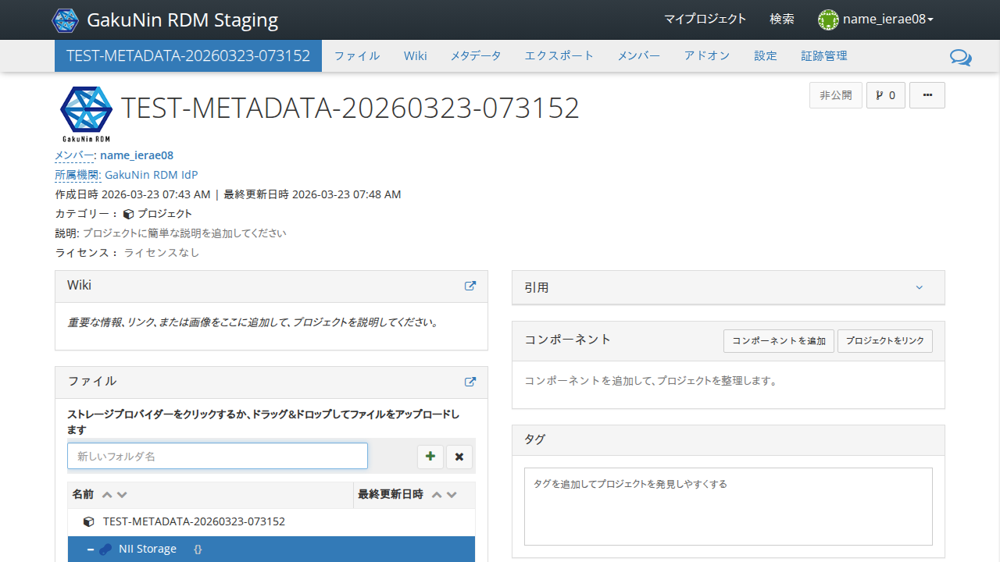

In [28]:
async def _step(page):
    await page.locator('//*[text() = "新規フォルダ作成"]').click()
    
    await expect(page.locator('//input[@id = "createFolderInput"]')).to_be_editable(timeout=transition_timeout)

await run_pw(_step)

## 「TESTMETADATA(ENTER)」を入力する

TESTMETADATAフォルダが作成されること

Start epoch: 1774252191.9145694 seconds


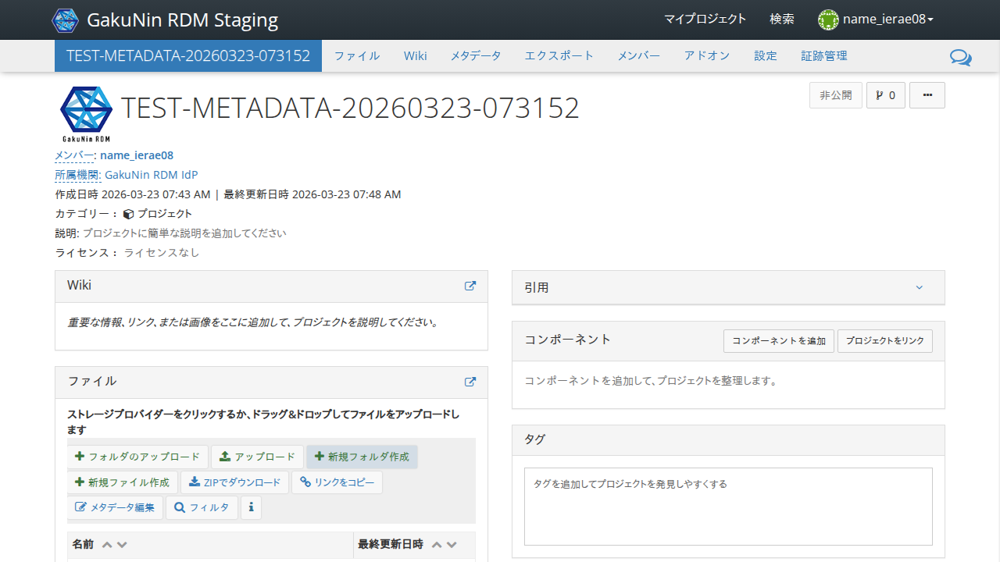

In [29]:
async def _step(page):
    await page.locator('//input[@id = "createFolderInput"]').fill('TESTMETADATA')
    await page.keyboard.press('Enter')

    await expect(page.locator('//*[text() = "TESTMETADATA"]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「TESTMETADATA」をクリックする

「メタデータ編集」ボタンが表示されること (表示まで数秒かかる可能性がある)

Start epoch: 1774252195.1578095 seconds


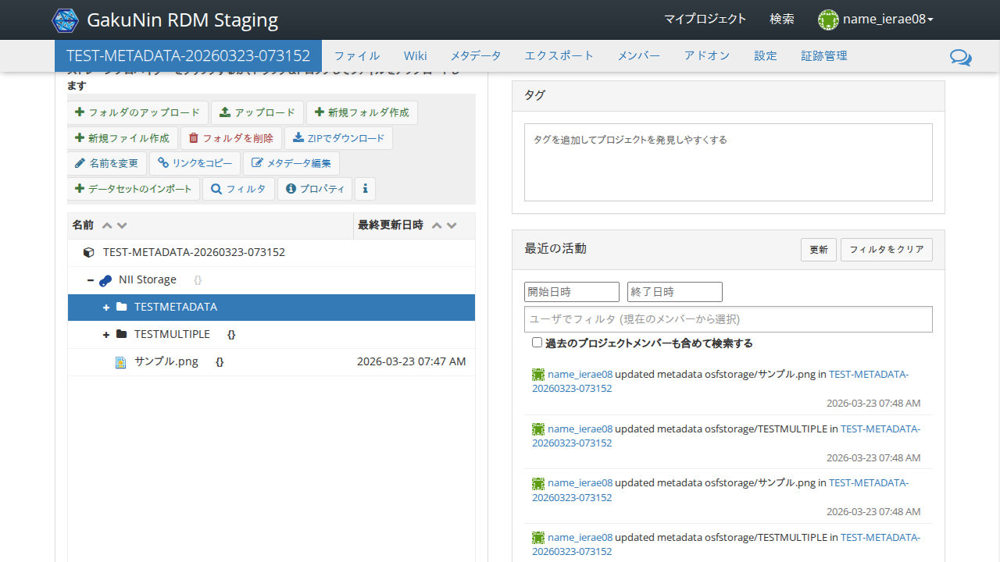

In [30]:
async def _step(page):
    await page.locator('//*[text() = "TESTMETADATA"]').click()

    await expect(page.locator('//*[text() = "メタデータ編集"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

##  「メタデータ編集」をクリックする

「メタデータ編集」ダイアログが表示されること

Start epoch: 1774252196.496285 seconds


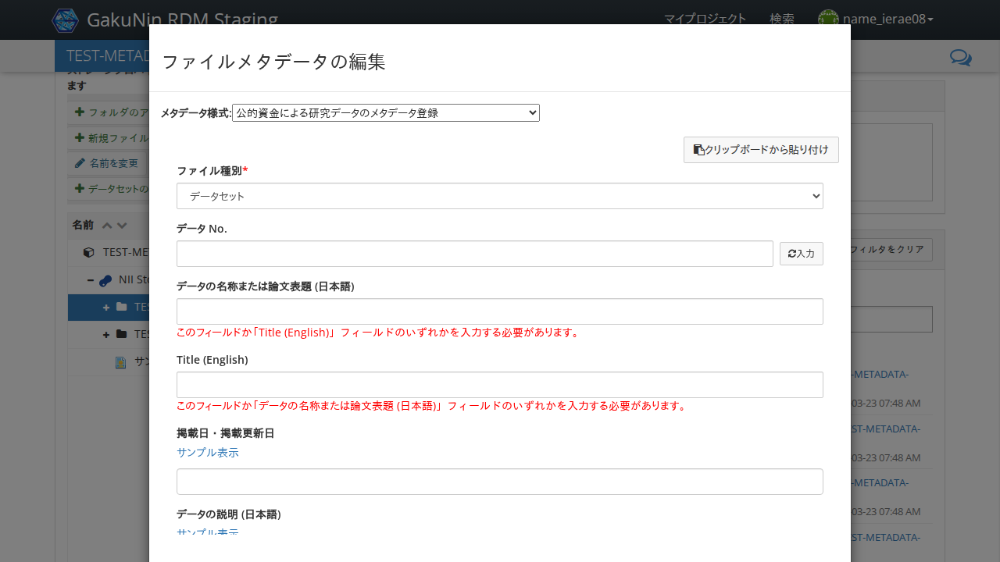

In [31]:
async def _step(page):
    await page.locator('//*[text() = "メタデータ編集"]').click()

    await expect(page.locator('//label[contains(text(), "メタデータ様式")]/following-sibling::select')).to_be_editable(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

##  「メタデータ様式」に「研究成果（公的資金対応）のメタデータ登録」を入力する

「データNo.」フィールドが表示されること

Start epoch: 1774252198.9057374 seconds


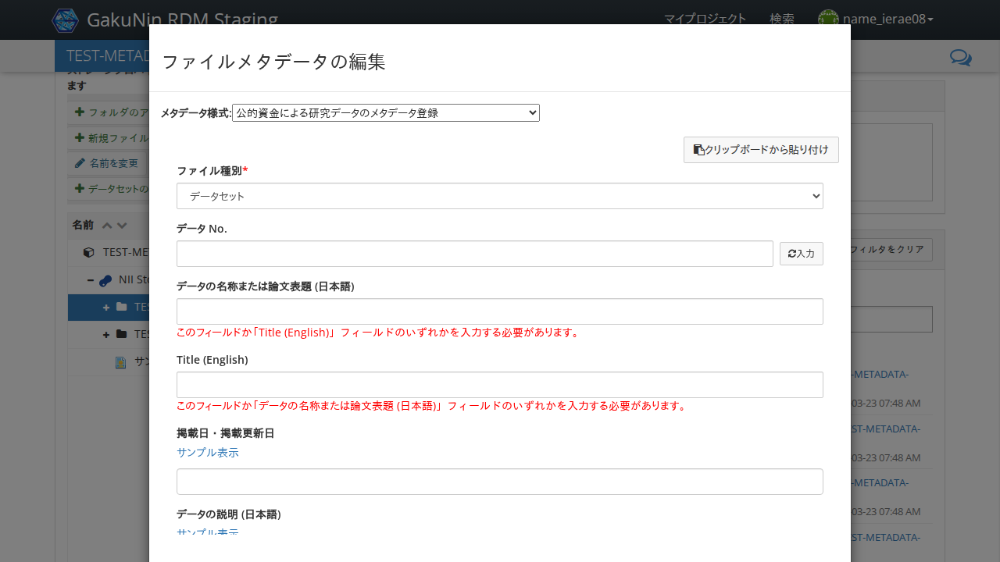

In [32]:
async def _step(page):
    await page.locator('//label[contains(text(), "メタデータ様式")]/following-sibling::select').select_option('研究成果（公的資金対応）のメタデータ登録')
    form = FileMetadataForm(page)

    await expect(form.get_locator('データ No.')).to_be_editable(timeout=transition_timeout)

await run_pw(_step)

##  「データ No.」の「入力」をクリックする

データNo.にファイルパスが表示されること

Start epoch: 1774252200.239578 seconds


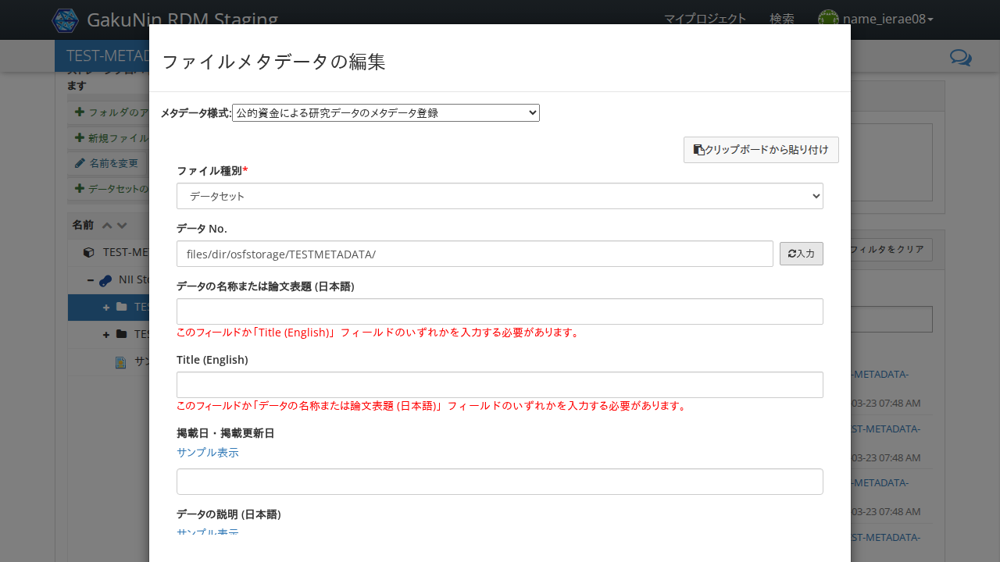

In [33]:
async def _step(page):
    target_storage_id = 'osfstorage'
    form = FileMetadataForm(page)
    await form.fill('データ No.', f'files/dir/{target_storage_id}/TESTMETADATA/')

    await expect(form.get_locator('データ No.')).to_have_value(f'files/dir/{target_storage_id}/TESTMETADATA/', timeout=transition_timeout)

await run_pw(_step)

##  「データの名称(日本語)」に「テストデータ」を入力する

「このフィールドか「Title(English)」フィールドのいずれかを入力する必要があります。」が表示されなくなること

Start epoch: 1774252201.6675947 seconds


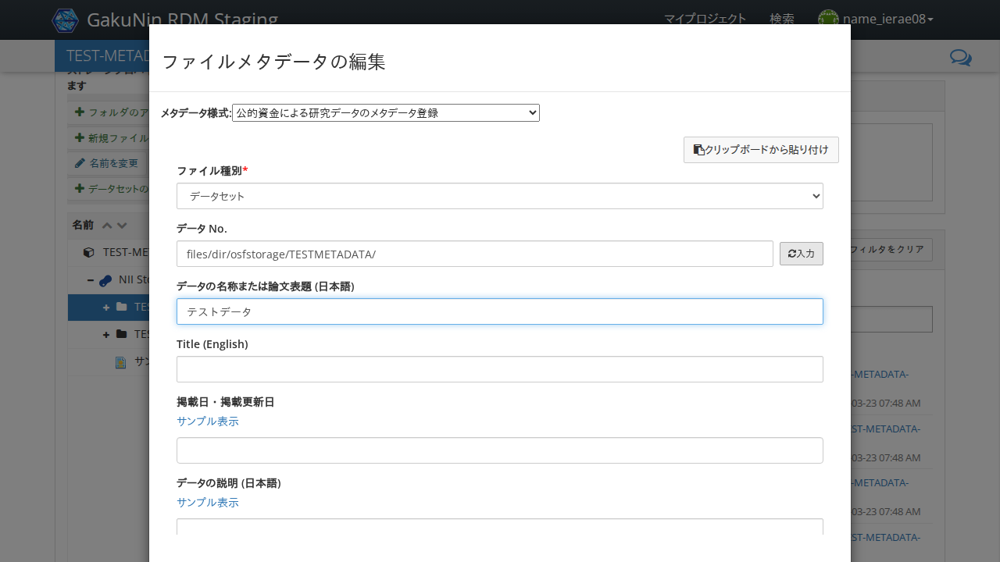

In [34]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データの名称 (日本語)', 'テストデータ')
    await page.keyboard.press('Enter')

    await expect(form.get_locator('データの名称 (日本語)')).to_have_value('テストデータ', timeout=transition_timeout)

await run_pw(_step)

##  「Title (English)」に「Test Data」を入力する

入力した値が表示されること

Start epoch: 1774252203.0760696 seconds


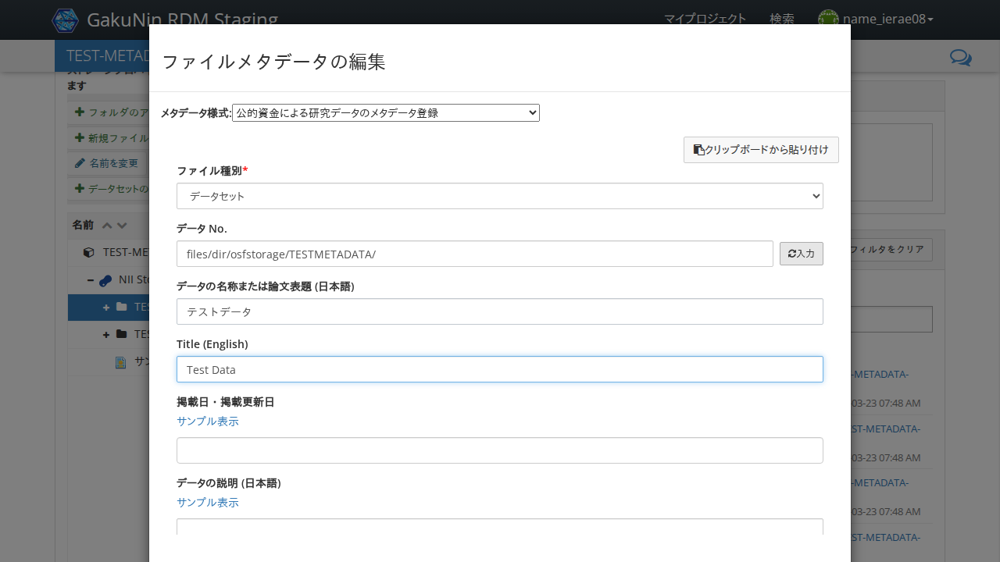

In [35]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('Data title (English)', 'Test Data')
    await page.keyboard.press('Enter')

    await expect(form.get_locator('Data title (English)')).to_have_value('Test Data', timeout=transition_timeout)

await run_pw(_step)

##  「掲載日・掲載更新日」に「2022-05-25」を入力する

入力した値が表示されること

Start epoch: 1774252204.4640238 seconds


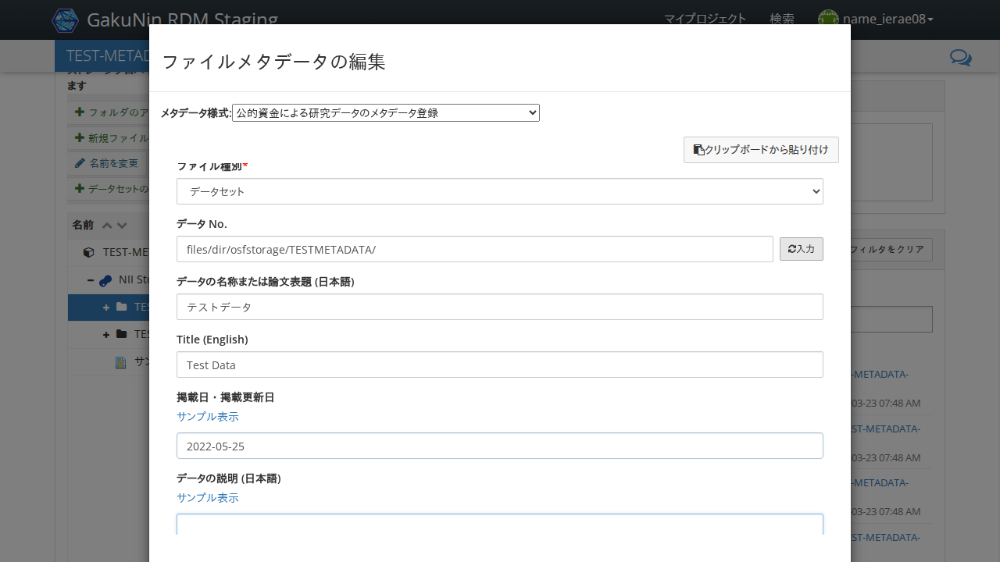

In [36]:
async def _step(page):
    form = FileMetadataForm(page)
    locator = form.get_locator('掲載日・掲載更新日')
    await locator.focus()
    await page.keyboard.type('2022-05-25')
    await page.keyboard.press('Tab')

    await expect(locator).to_have_value('2022-05-25', timeout=transition_timeout)

await run_pw(_step)

##  「データの説明 (日本語)」に「自動テストによって作成されたメタデータです。」を入力する

「このフィールドか「Description(English)」フィールドのいずれかを入力する必要があります。」が表示されなくなること

Start epoch: 1774252206.0100567 seconds


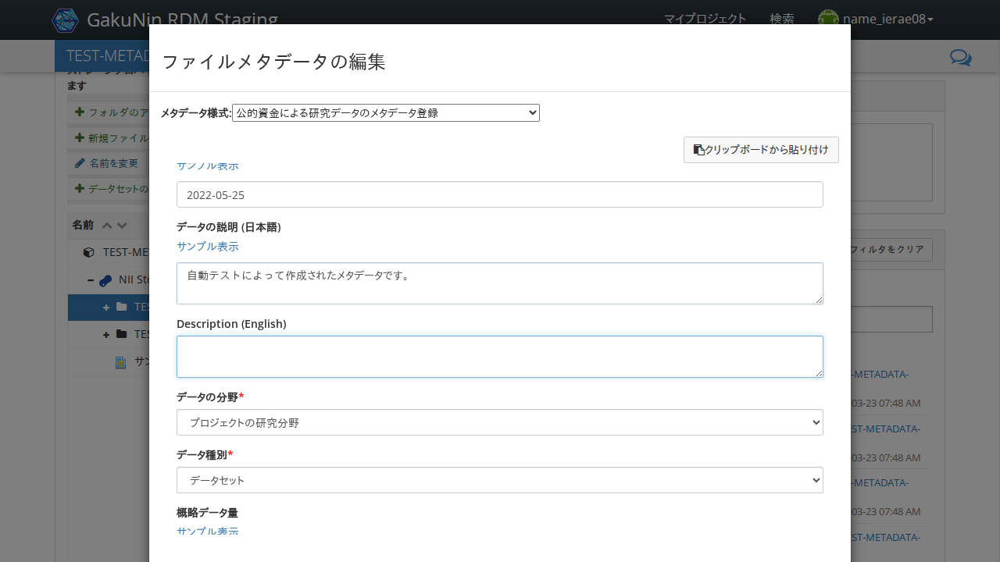

In [37]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データの説明 (日本語)', '自動テストによって作成されたメタデータです。')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データの説明 (日本語)')).to_have_value('自動テストによって作成されたメタデータです。', timeout=transition_timeout)

await run_pw(_step)

##  「Description (English)」に「Metadata created by automated testing.」を入力する

入力した値が表示されること

Start epoch: 1774252207.4466314 seconds


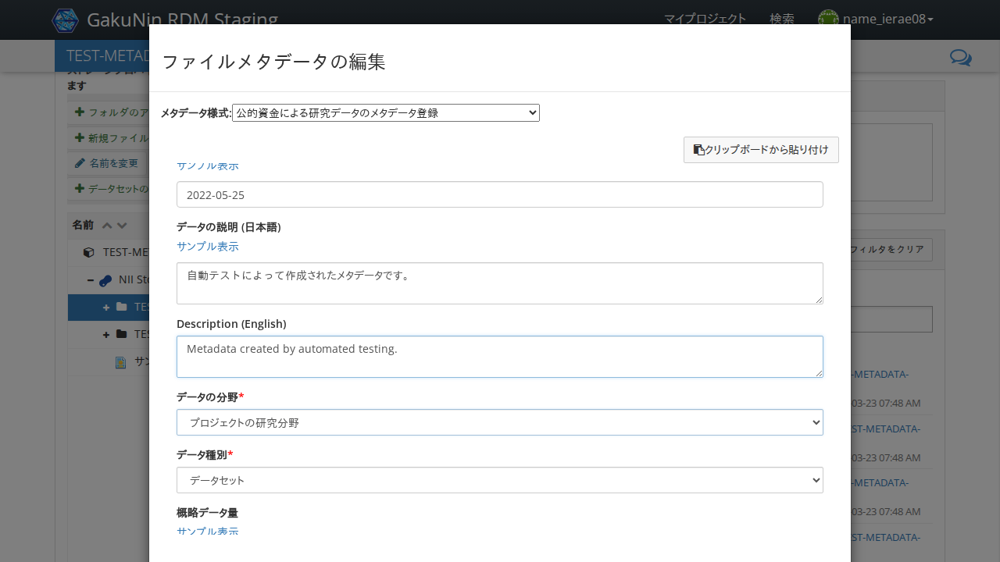

In [38]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('Description (English)', 'Metadata created by automated testing.')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Description (English)')).to_have_value('Metadata created by automated testing.', timeout=transition_timeout)

await run_pw(_step)

##  「概略データ量」の「計算」をクリックする

「0B」と入力されること

Start epoch: 1774252208.8234804 seconds


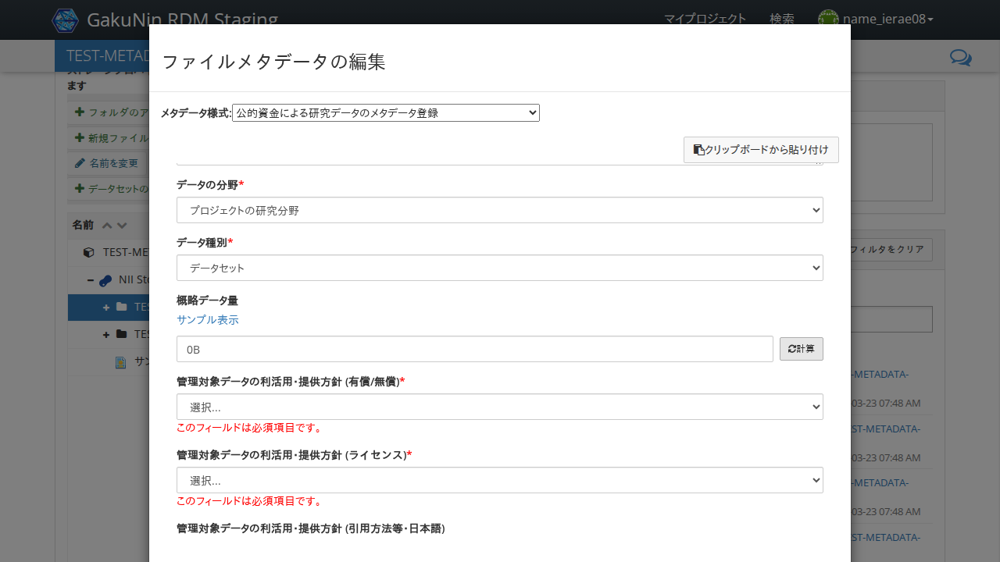

In [39]:
async def _step(page):
    await page.locator('//label[contains(text(), "概略データ量")]/../following-sibling::div[1]//*[text() = "計算"]').click()
    form = FileMetadataForm(page)

    await expect(form.get_locator('概略データ量')).to_have_value('0B', timeout=transition_timeout)

await run_pw(_step)

##  「管理対象データの利活用・提供方針 (有償/無償)」に「無償」を入力する

「このフィールドは必須項目です。」が表示されなくなること

Start epoch: 1774252212.0480642 seconds


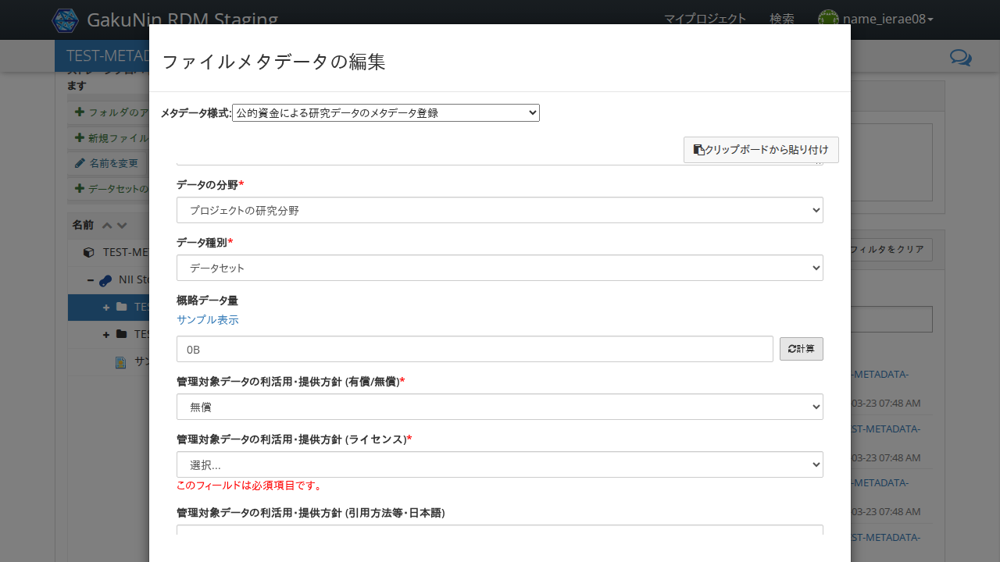

In [40]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('管理対象データの利活用・提供方針 (有償/無償)', '無償')

    await expect(form.get_locator('管理対象データの利活用・提供方針 (有償/無償)').locator('input[type="radio"]:checked + span, label:has(input[type="radio"]:checked)')).to_contain_text('無償', timeout=transition_timeout)

await run_pw(_step)

##  「管理対象データの利活用・提供方針 (ライセンス)」に「CC BY 4.0 表示 国際」を入力する

「このフィールドは必須項目です。」が表示されなくなること

Start epoch: 1774252213.506069 seconds


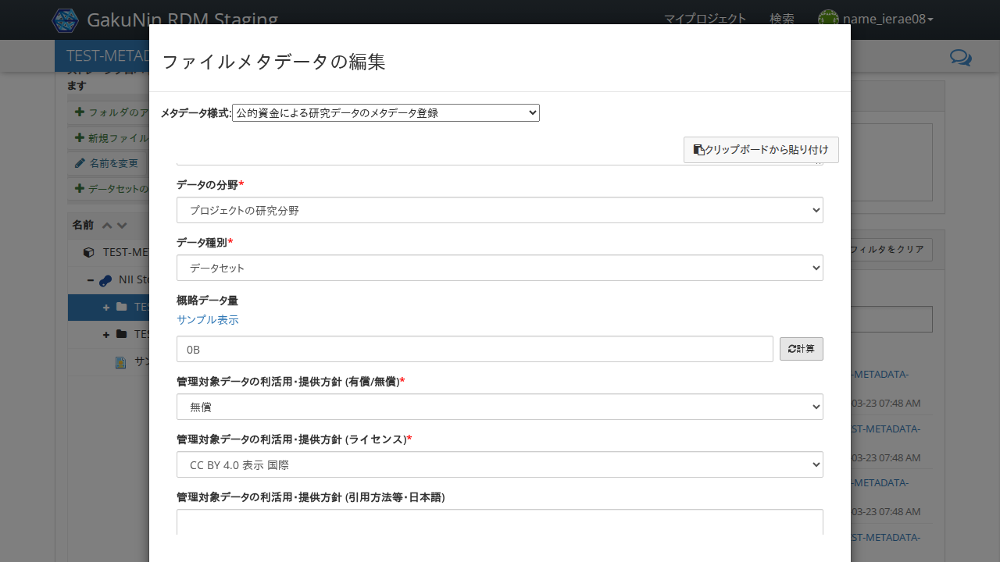

In [41]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('管理対象データの利活用・提供方針 (ライセンス)', 'CC BY 4.0 表示 国際')

    await expect(form.get_locator('管理対象データの利活用・提供方針 (ライセンス)').locator('option:checked')).to_have_text('CC BY 4.0 表示 国際', timeout=transition_timeout)

await run_pw(_step)

##  「管理対象データの利活用・提供方針 (引用方法等・日本語)」に「利用方針をここに記載します。」を入力する

「このフィールドか「Data utilization and provision policy (citation information, English)」フィールドのいずれかを入力する必要があります。」が表示されなくなること

Start epoch: 1774252214.8714364 seconds


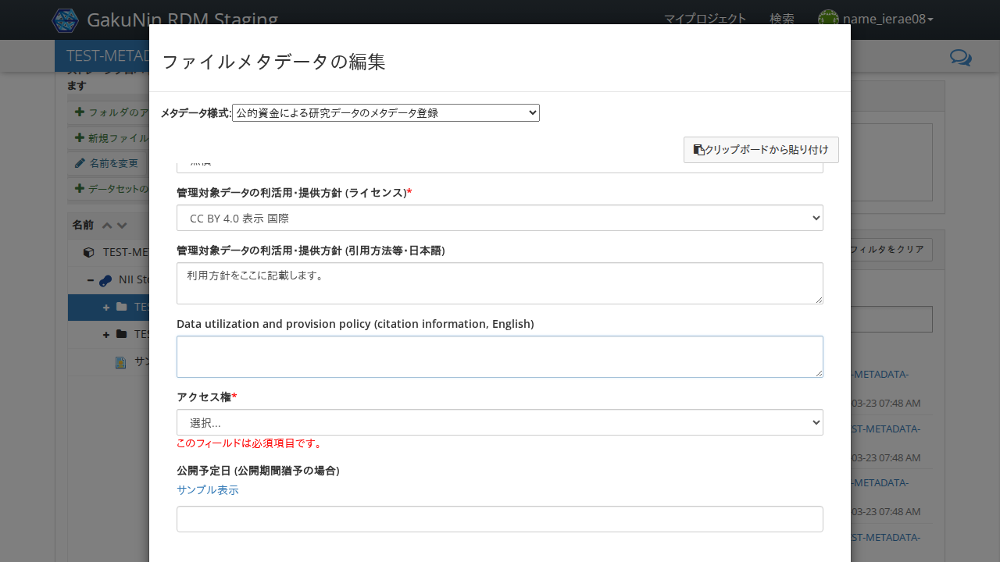

In [42]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('管理対象データの利活用・提供方針 (引用方法等・日本語)', '利用方針をここに記載します。')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('管理対象データの利活用・提供方針 (引用方法等・日本語)')).to_have_value('利用方針をここに記載します。', timeout=transition_timeout)

await run_pw(_step)

##  「Data utilization and provision policy (citation information, English)」に「The policy for use is described here.」を入力する

入力した値が表示されること

Start epoch: 1774252216.3004615 seconds


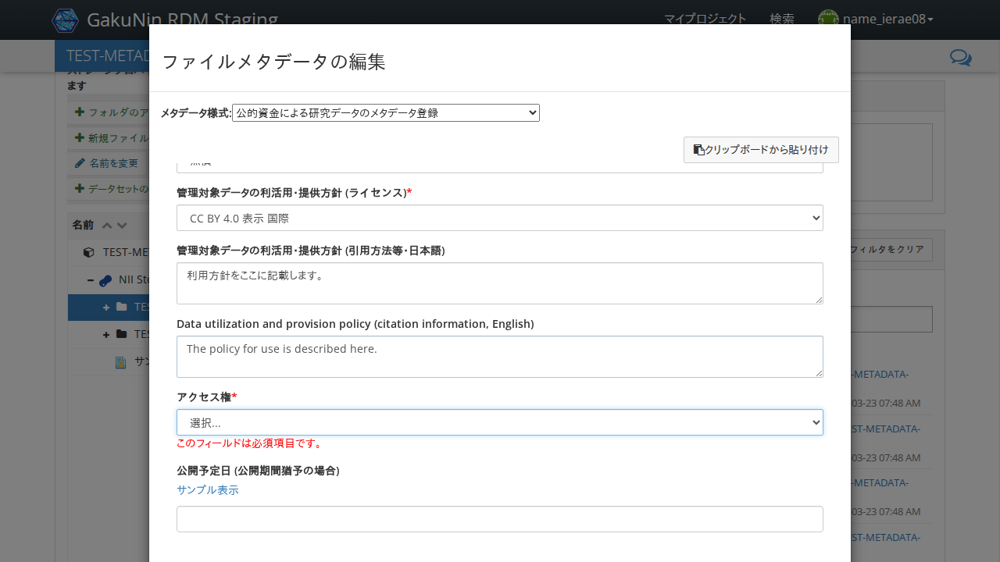

In [43]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('Data utilization and provision policy (citation information, English)', 'The policy for use is described here.')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Data utilization and provision policy (citation information, English)')).to_have_value('The policy for use is described here.', timeout=transition_timeout)

await run_pw(_step)

##  「アクセス権」に「公開」を入力する

「このフィールドは必須項目です。」が表示されなくなること

Start epoch: 1774252217.720108 seconds


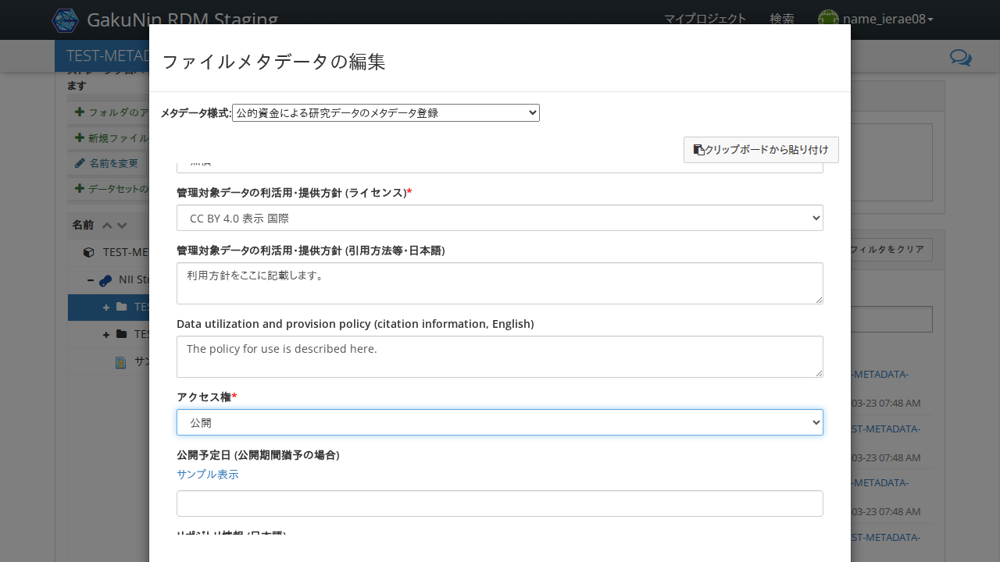

In [44]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('アクセス権', '公開')

    await expect(form.get_locator('アクセス権').locator('option:checked')).to_have_text('公開', timeout=transition_timeout)

await run_pw(_step)

##  「リポジトリ情報 (日本語)」に「テストリポジトリ」を入力する

入力した値が表示されること

Start epoch: 1774252219.1424174 seconds


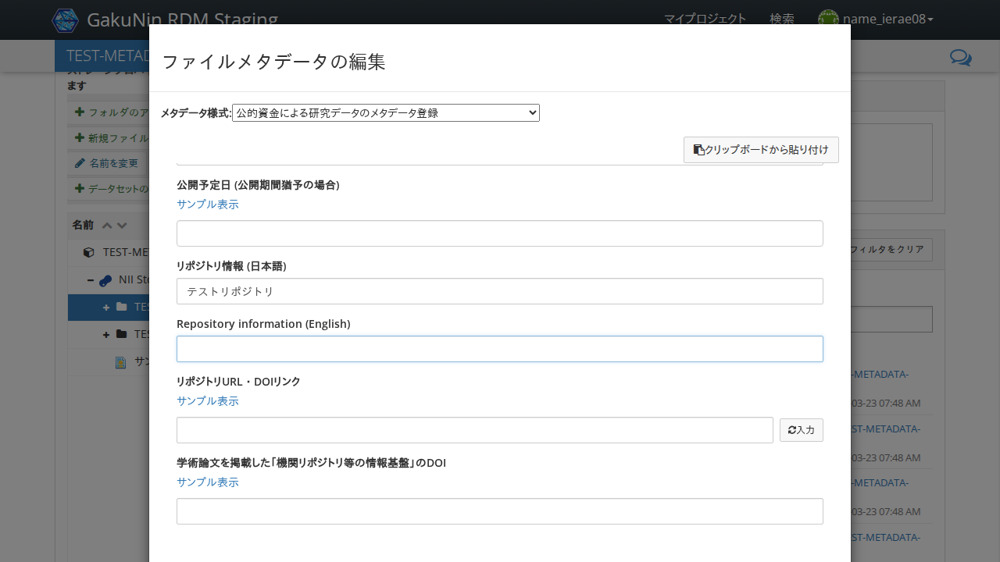

In [45]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'テストリポジトリ'
    await form.fill('リポジトリ情報 (日本語)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('リポジトリ情報 (日本語)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「Repository information (English)」に「Test Repository」を入力する

入力した値が表示されること

Start epoch: 1774252220.5706127 seconds


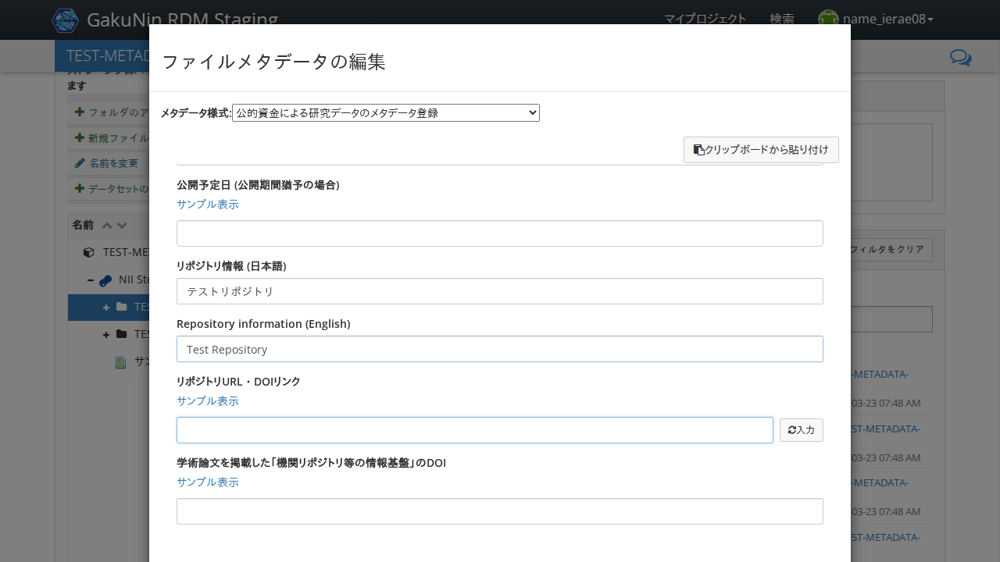

In [46]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'Test Repository'
    await form.fill('Repository information (English)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Repository information (English)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「リポジトリURL・DOIリンク」の「入力」をクリックする

フォルダのURLが表示されること

Start epoch: 1774252222.0391238 seconds


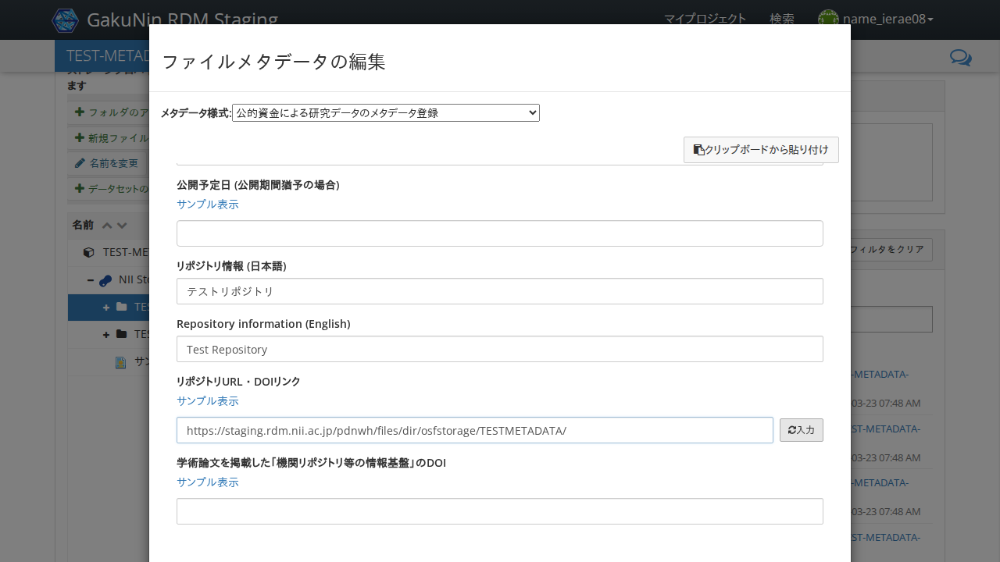

In [47]:
from urllib.parse import urljoin

# URL置き換えフラグ
url_replaced = False

async def _step(page):
    global url_replaced
    target_storage_id = 'osfstorage'
    form = FileMetadataForm(page)
    input_locator = form.get_locator('リポジトリURL・DOIリンク')
    await page.locator('//label[contains(text(), "リポジトリURL・DOIリンク")]/../following-sibling::div[1]//*[text() = "GakuNin RDM URL入力"]').click()
    value = urljoin(page.url, f'files/dir/{target_storage_id}/TESTMETADATA/')

    await expect(input_locator).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「データ作成者」の「追加」をクリックする

作成者入力フィールドが表示されること

Start epoch: 1774252223.463576 seconds


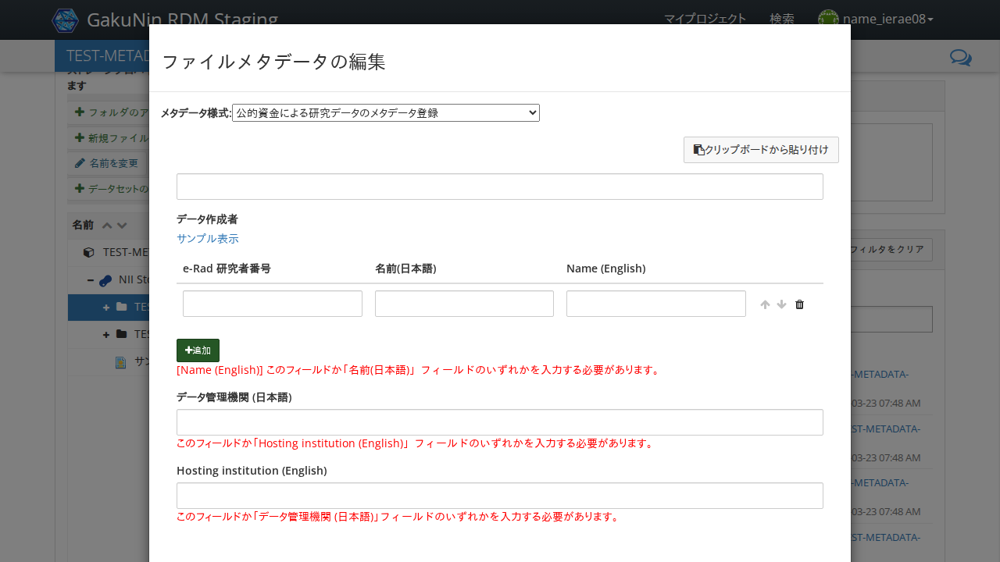

In [48]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill_author({
        'number': '0123456789',
        'name_ja': {'last': '情報', 'middle': '', 'first': '太郎'},
        'name_en': {'last': 'Joho', 'middle': '', 'first': 'Taro'},
        'affiliation_ja': '',
        'affiliation_en': '',
    }, table_label='データ作成者', add_row=False)

    panel = form.get_locator('データ作成者').locator('.metadata-display-mode >> visible=true')
    await expect(panel).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

##  「e-Rad研究者番号」に「0123456789」を入力する

フィールドに値が表示されること

Start epoch: 1774252224.9231033 seconds


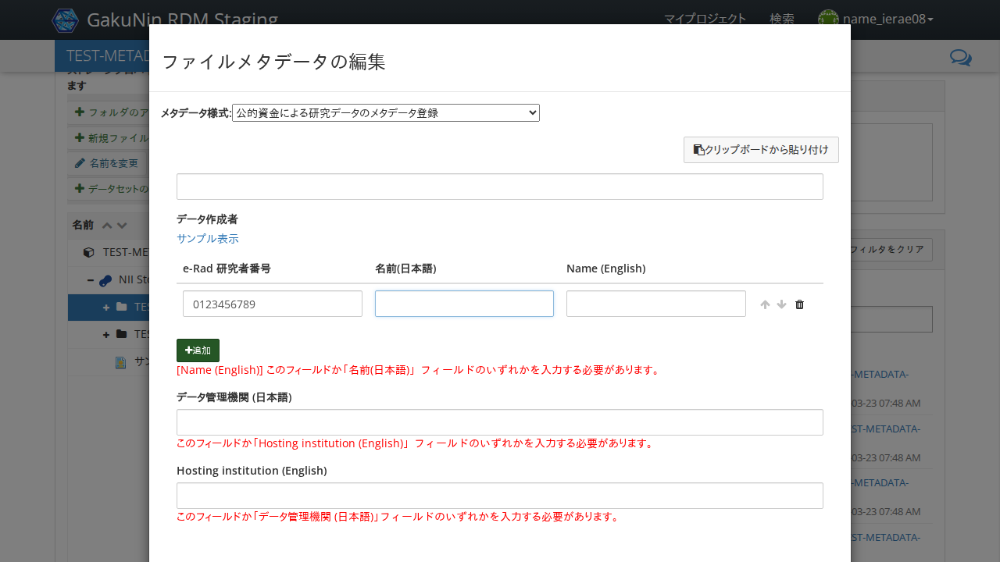

In [49]:
async def _step(page):
    form = FileMetadataForm(page)
    author = await form.get_author(table_label='データ作成者', row_index=0)
    assert author['number'] == '0123456789', f"Expected '0123456789', got {author['number']}"

await run_pw(_step)

##  「名前　(日本語)」に「情報太郎」を入力する

フィールドに値が表示されること

Start epoch: 1774252226.3860176 seconds


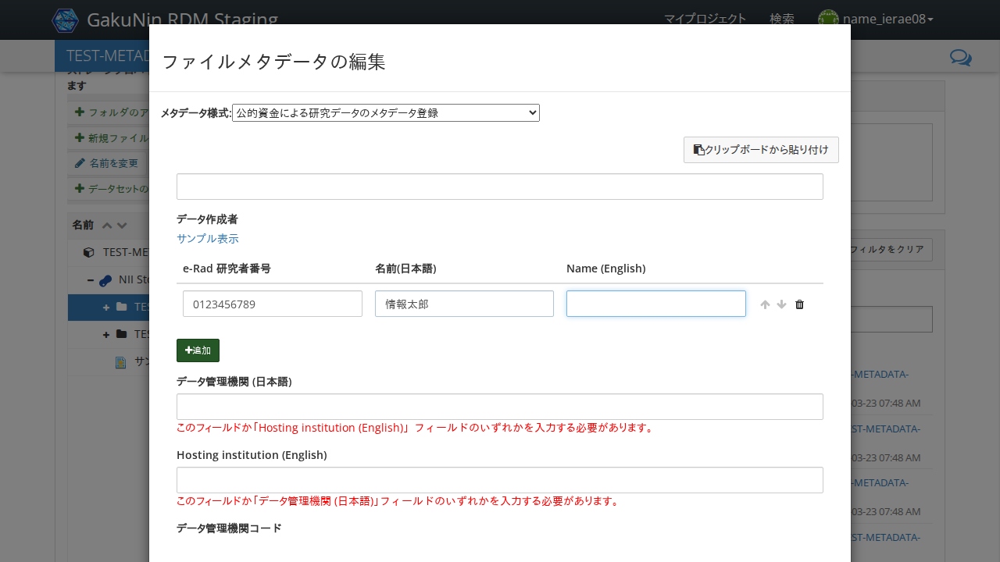

In [50]:
async def _step(page):
    form = FileMetadataForm(page)
    author = await form.get_author(table_label='データ作成者', row_index=0)
    expected = {'last': '情報', 'middle': '', 'first': '太郎'}
    assert author['name_ja'] == expected, f"Expected {expected}, got {author['name_ja']}"

await run_pw(_step)

##  「Name(English)」に「Taro Joho」を入力する

フィールドに値が表示されること

Start epoch: 1774252227.8827105 seconds


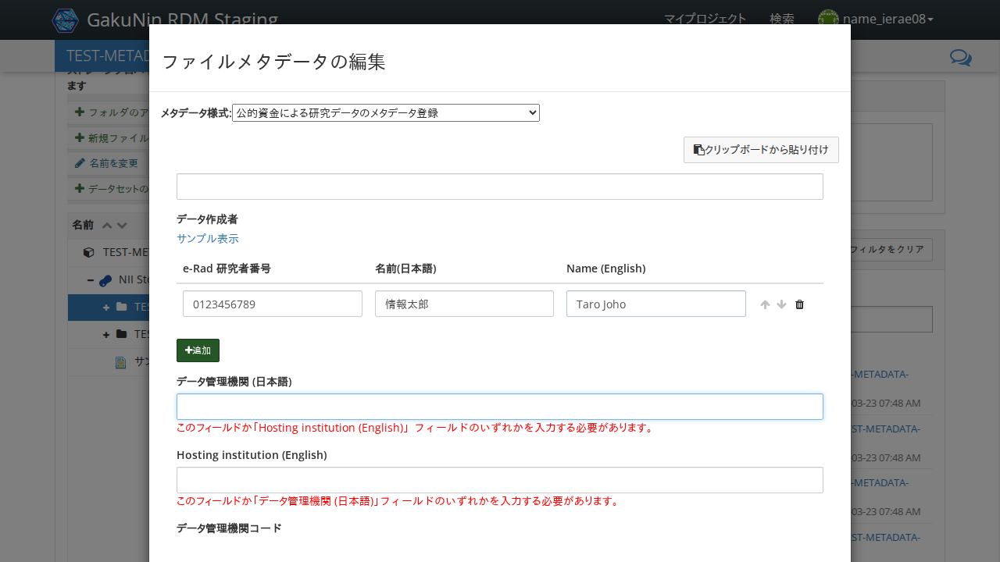

In [51]:
async def _step(page):
    form = FileMetadataForm(page)
    author = await form.get_author(table_label='データ作成者', row_index=0)
    expected = {'last': 'Joho', 'middle': '', 'first': 'Taro'}
    assert author['name_en'] == expected, f"Expected {expected}, got {author['name_en']}"

await run_pw(_step)

##  「データ管理機関 (日本語)」に「国立情報学研究所」を入力する

「このフィールドか「Hosting institution (English)」フィールドのいずれかを入力する必要があります。」が表示されなくなること

Start epoch: 1774252229.3593342 seconds


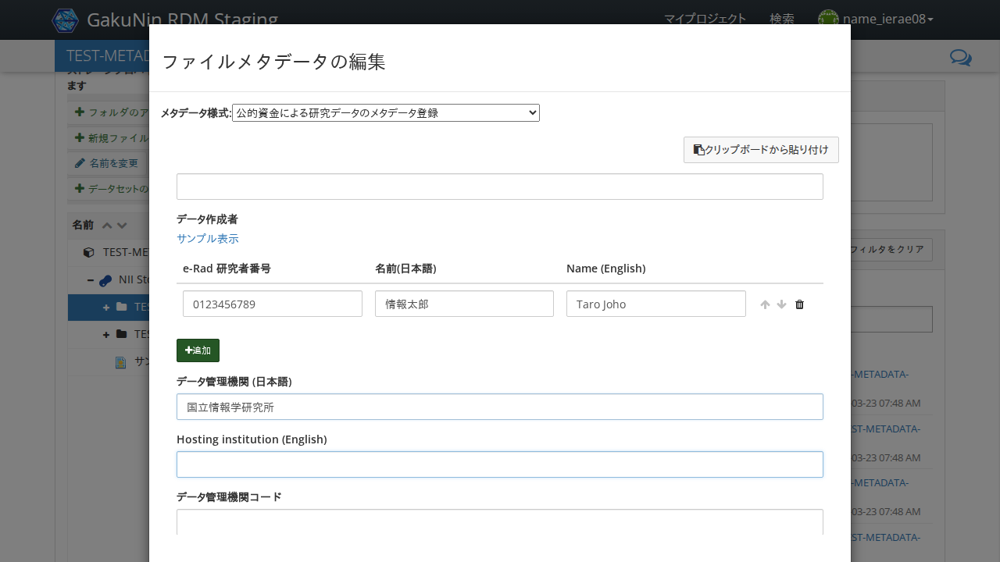

In [52]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データ管理機関 (日本語)', '国立情報学研究所')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理機関 (日本語)')).to_have_value('国立情報学研究所', timeout=transition_timeout)

await run_pw(_step)

##  「Hosting institution (English)」に「National Institute of Informatics」を入力する

入力した値が表示されること

Start epoch: 1774252230.9180803 seconds


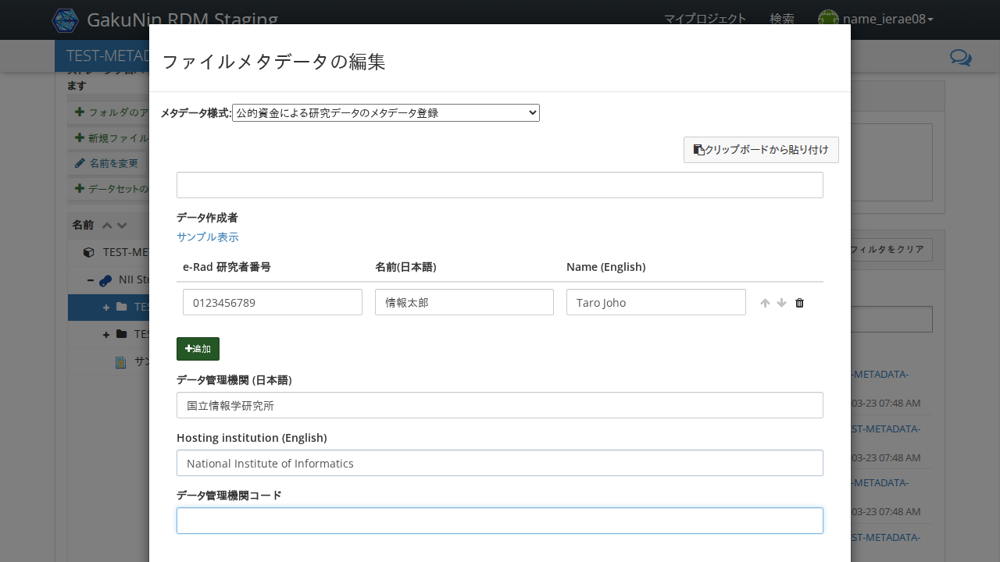

In [53]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('Hosting institution (English)', 'National Institute of Informatics')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Hosting institution (English)')).to_have_value('National Institute of Informatics', timeout=transition_timeout)

await run_pw(_step)

## 「データ管理機関コード」に「 https://ror.org/DUMMY 」を入力する

値が表示されること

Start epoch: 1774252232.4152231 seconds


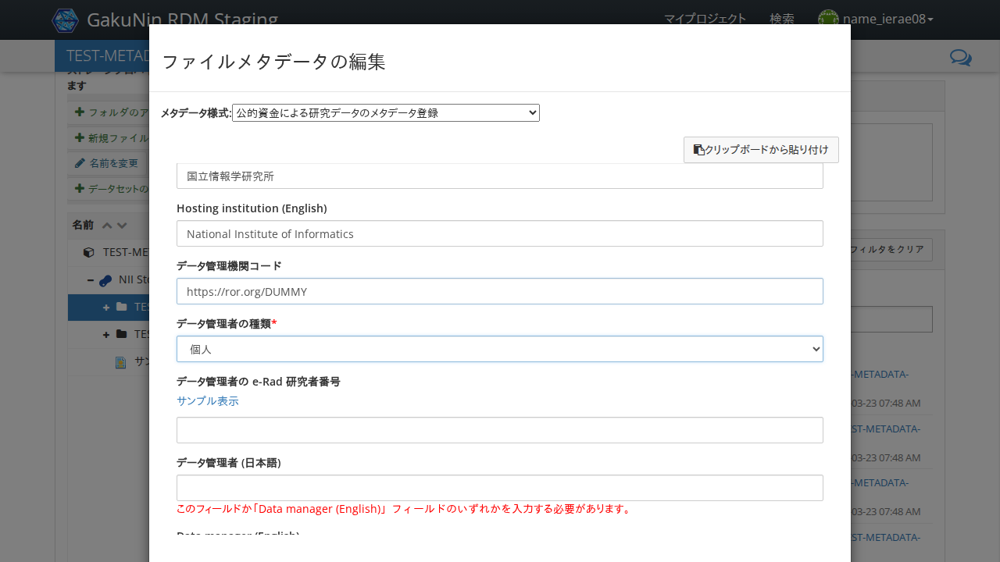

In [54]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データ管理機関コード', 'https://ror.org/DUMMY')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理機関コード')).to_have_value('https://ror.org/DUMMY', timeout=transition_timeout)

await run_pw(_step)

## 「データ管理者の種類」にて「個人」を選択する

すでに値が表示されている場合は選択不要。「個人」が表示されること

Start epoch: 1774252233.8867855 seconds


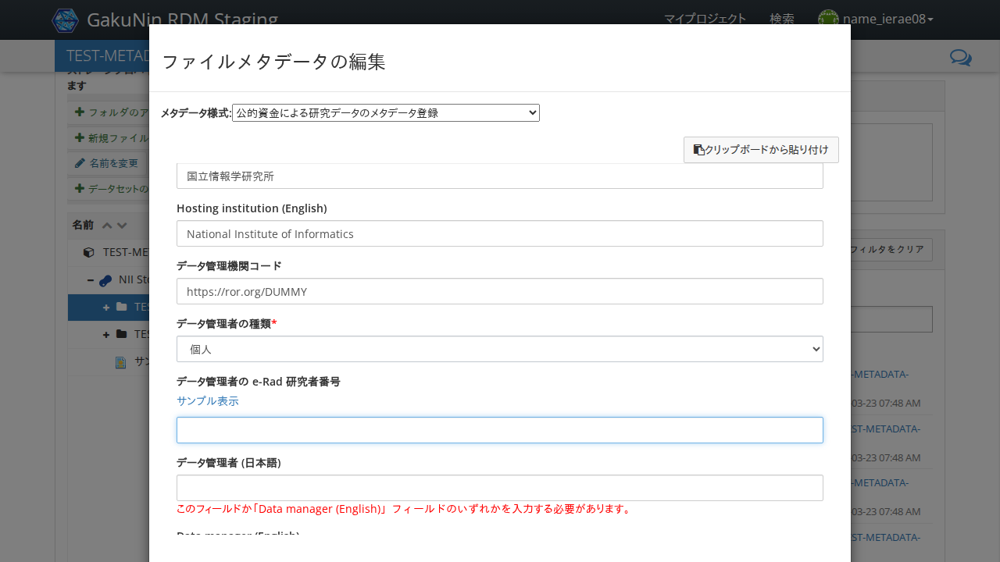

In [55]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データ管理者の種類', '個人')

    await expect(form.get_locator('データ管理者の種類').locator('input[type="radio"]:checked')).to_have_value('individual', timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者の e-Rad 研究者番号」に「0123456789」を入力する

値が表示されること

Start epoch: 1774252235.3683329 seconds


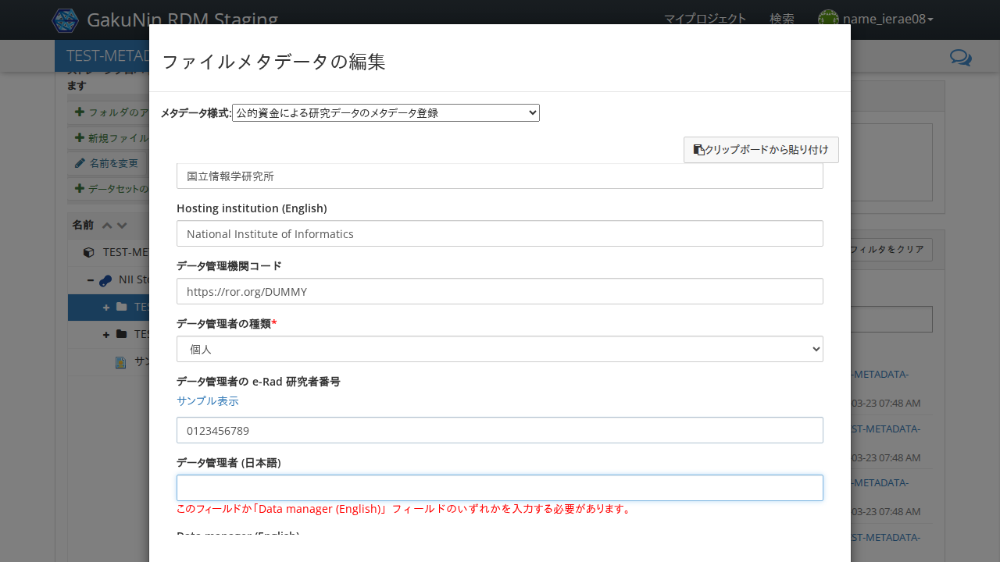

In [56]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データ管理者の e-Rad 研究者番号', '0123456789')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理者の e-Rad 研究者番号')).to_have_value('0123456789', timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者 (日本語)」に「情報花子」を入力する

「このフィールドか「Data manager (English)」フィールドのいずれかを入力する必要があります。」が表示されなくなること

Start epoch: 1774252236.8809915 seconds


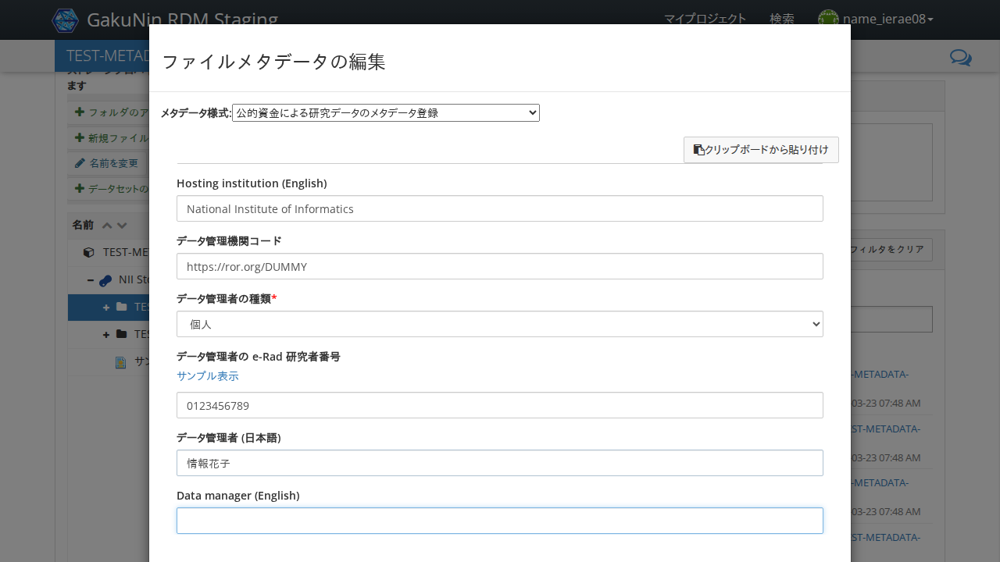

In [57]:
async def _step(page):
    form = FileMetadataForm(page)
    name = {'last': '情報', 'middle': '', 'first': '花子'}
    await form.fill_name('データ管理者 (日本語)', name)

    result = await form.get_name('データ管理者 (日本語)')
    assert result == name, f'Expected {name}, got {result}'

await run_pw(_step)

##  「Data manager (English)」に「Hanako Joho」を入力する

値が表示されること

Start epoch: 1774252238.435952 seconds


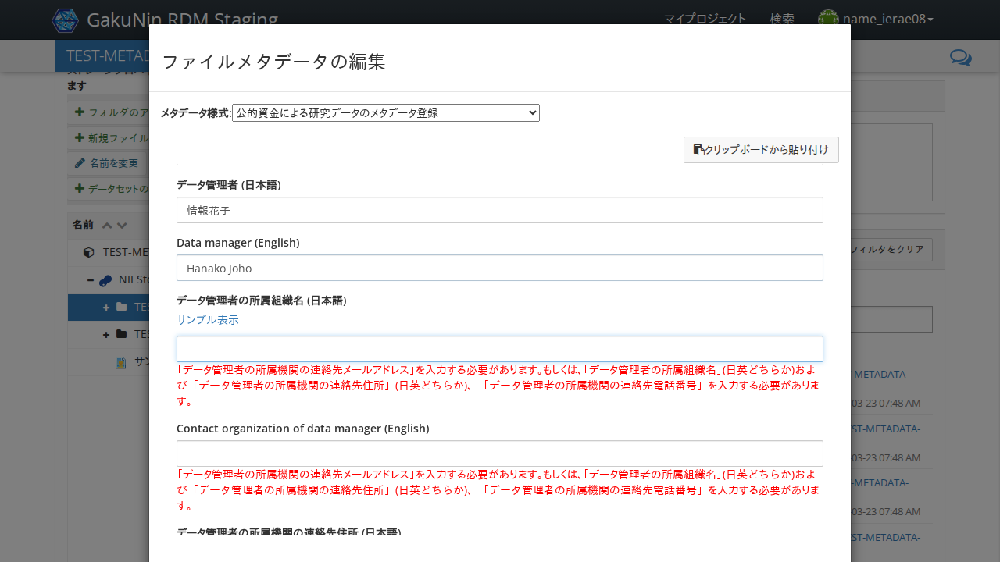

In [58]:
async def _step(page):
    form = FileMetadataForm(page)
    name = {'last': 'Joho', 'middle': '', 'first': 'Hanako'}
    await form.fill_name('Data manager (English)', name)

    result = await form.get_name('Data manager (English)')
    assert result == name, f'Expected {name}, got {result}'

await run_pw(_step)

##  「データ管理者の所属組織名(日本語)」に「テストセンター」を入力する

値が表示されること

Start epoch: 1774252240.0111008 seconds


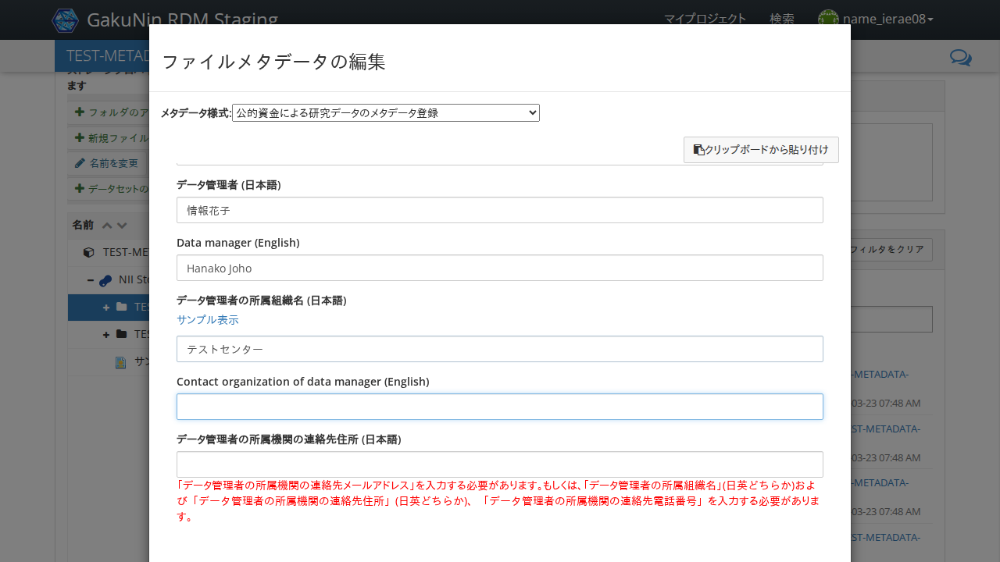

In [59]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'テストセンター'
    await form.fill('データ管理者の所属組織名 (日本語)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理者の所属組織名 (日本語)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「Contact organization of data manager (English)」に「Test Center」を入力する

値が表示されること

Start epoch: 1774252241.6003358 seconds


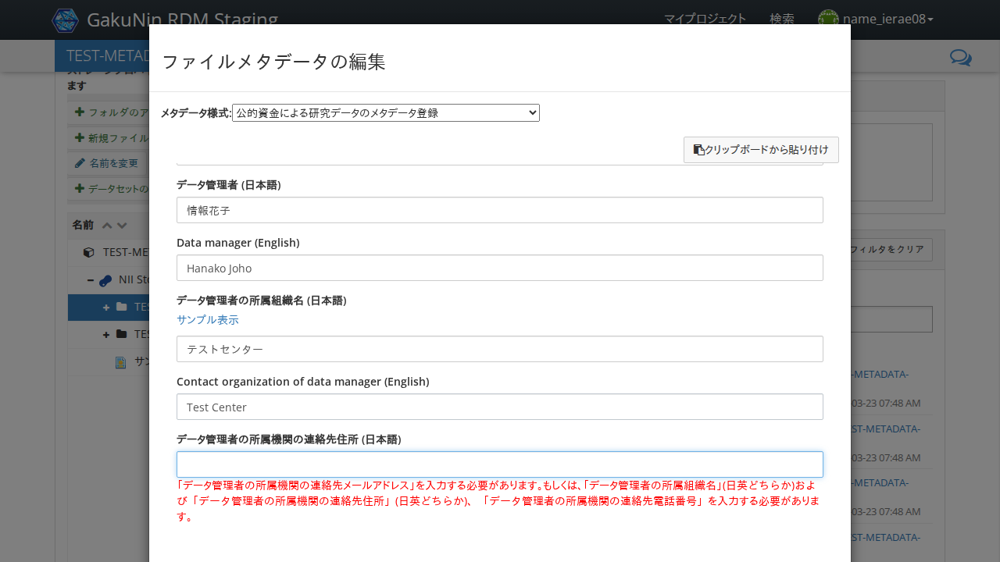

In [60]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'Test Center'
    await form.fill('Contact organization of data manager (English)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Contact organization of data manager (English)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者の所属機関の連絡先住所 (日本語)」に「テスト住所」を入力する

値が表示されること

Start epoch: 1774252243.189454 seconds


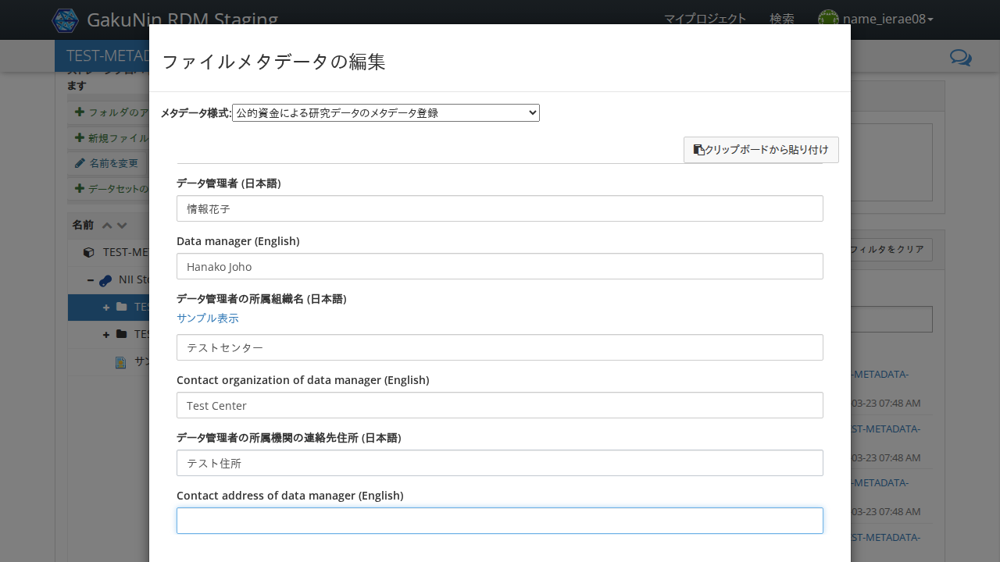

In [61]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'テスト住所'
    await form.fill('データ管理者の所属機関の連絡先住所 (日本語)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理者の所属機関の連絡先住所 (日本語)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「Contact address of data manager (English)」に「Test Address」を入力する

値が表示されること

Start epoch: 1774252244.7556527 seconds


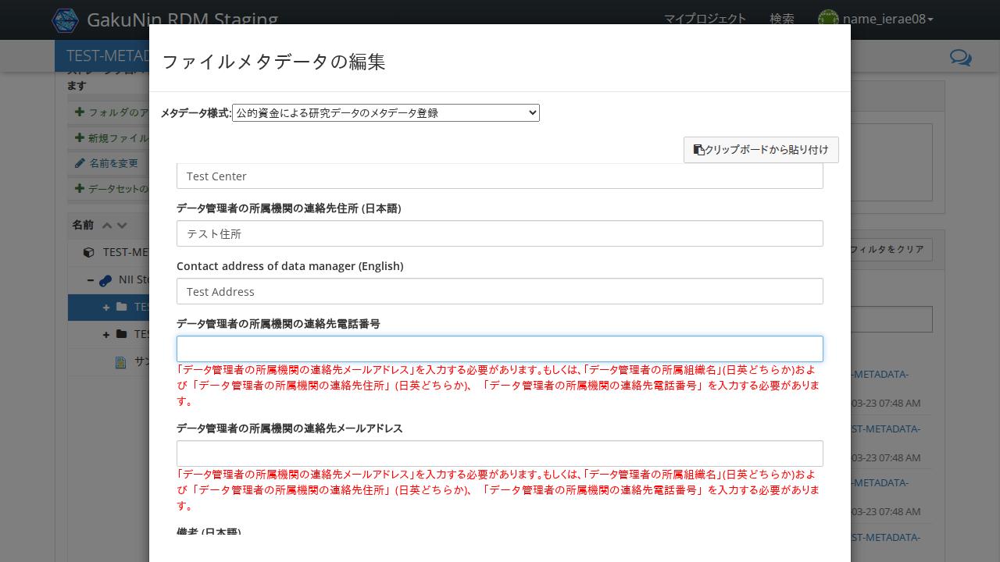

In [62]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'Test Address'
    await form.fill('Contact address of data manager (English)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Contact address of data manager (English)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者の所属機関の連絡先電話番号」に「000-0000-0000」を入力する

「「データ管理者の所属機関の連絡先メールアドレス」を入力する必要があります。もしくは、「データ管理者の所属組織名」(日英どちらか)および「データ管理者の所属機関の連絡先住所」(日英どちらか)、「データ管理者の所属機関の連絡先電話番号」を入力する必要があります。」が表示されなくなること

Start epoch: 1774252246.3556476 seconds


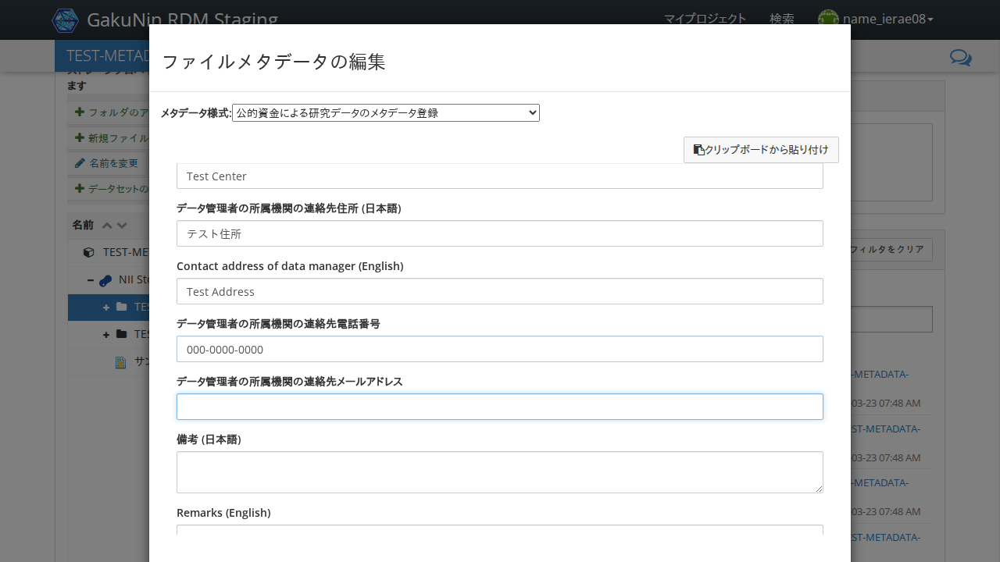

In [63]:
async def _step(page):
    form = FileMetadataForm(page)
    value = '000-0000-0000'
    await form.fill('データ管理者の所属機関の連絡先電話番号', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理者の所属機関の連絡先電話番号')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者の所属機関の連絡先メールアドレス」に「test@example.com」を入力する

入力した値が表示されること

Start epoch: 1774252248.0019372 seconds


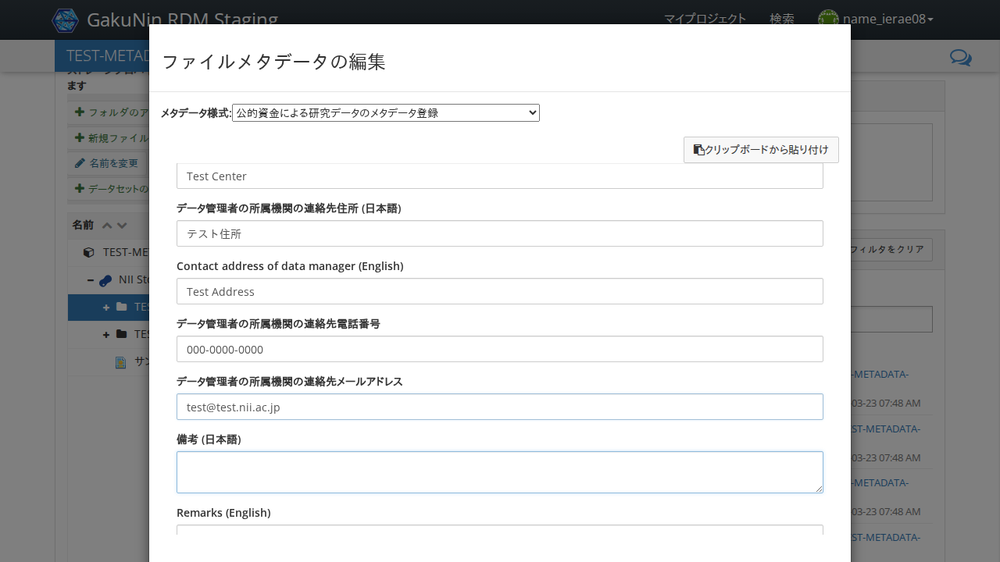

In [64]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'test@test.nii.ac.jp'
    await form.fill('データ管理者の所属機関の連絡先メールアドレス', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理者の所属機関の連絡先メールアドレス')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「備考 (日本語)」に「日本語による備考です。」を入力する

値が表示されること

Start epoch: 1774252249.563704 seconds


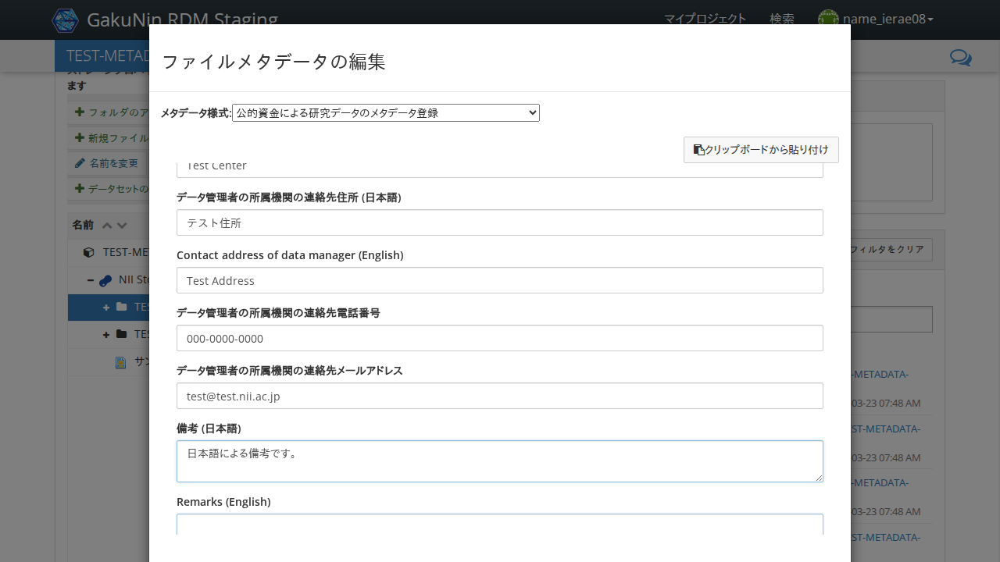

In [65]:
async def _step(page):
    form = FileMetadataForm(page)
    value = '日本語による備考です。'
    await form.fill('備考 (日本語)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('備考 (日本語)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「Remarks (English)」に「Remarks in English.」を入力する

値が表示されること

Start epoch: 1774252251.175666 seconds


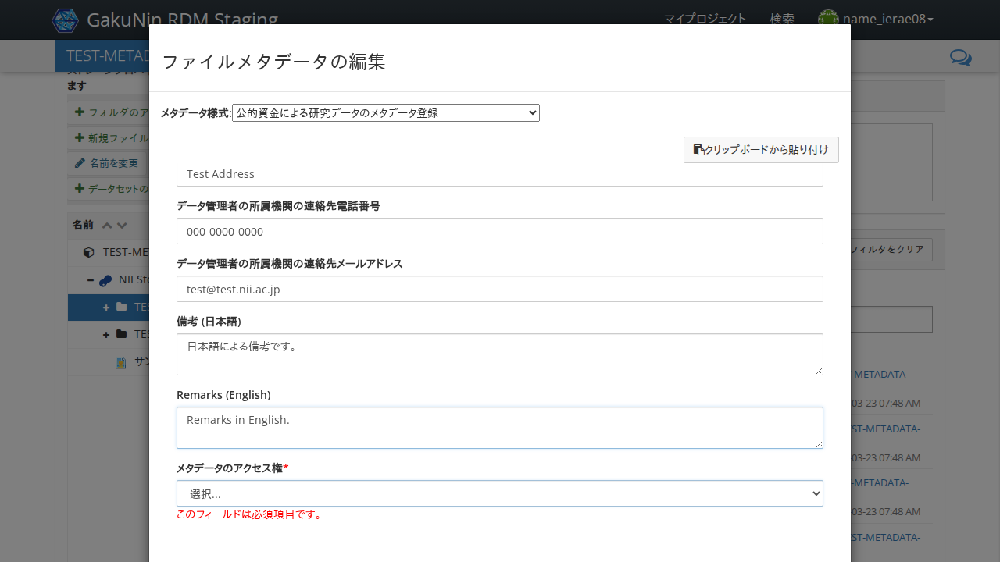

In [66]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'Remarks in English.'
    await form.fill('Remarks (English)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Remarks (English)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

## 「保存」をクリックする

ダイアログが非表示になること

Start epoch: 1774252254.422513 seconds


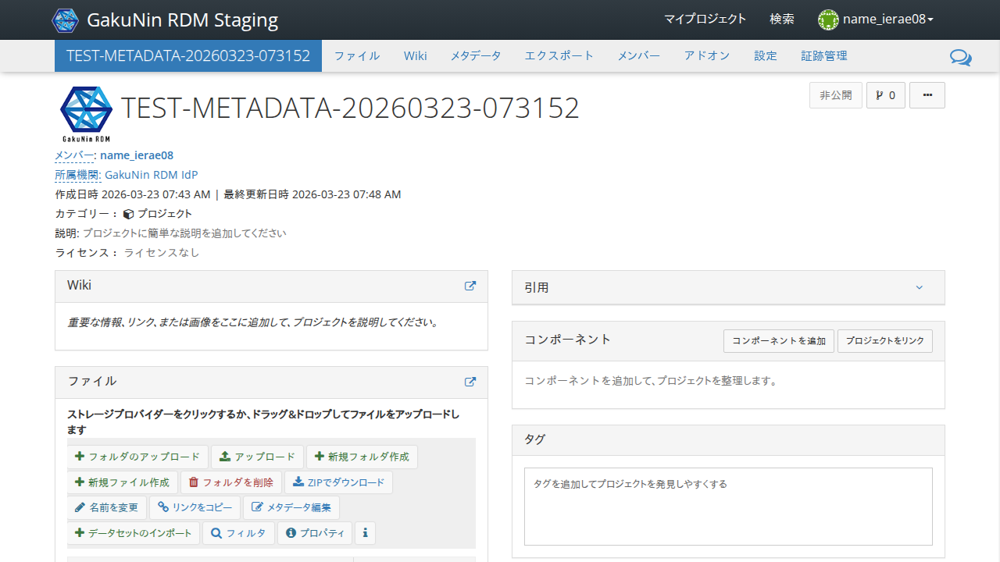

In [68]:
async def _step(page):
    await page.locator('//a[text() = "保存"]').click()
    form = FileMetadataForm(page)
    await expect(form.get_locator('Remarks (English)')).not_to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## プロジェクトダッシュボードの上部メニューから「メタデータ」をクリックする

メタデータの一覧ページが表示されること

Start epoch: 1774252256.823826 seconds


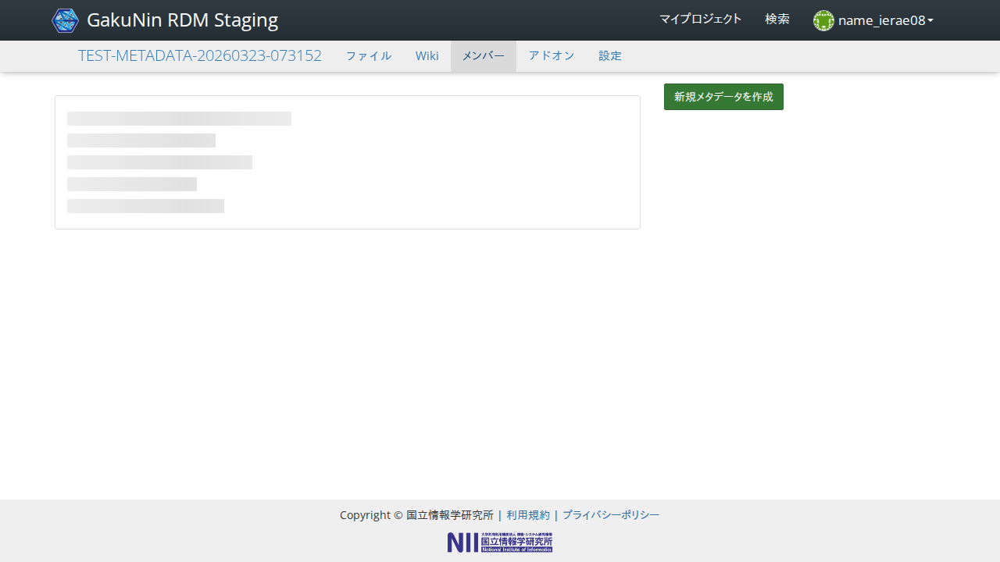

In [69]:
async def _step(page):
    await page.locator('//nav//a[contains(text(), "メタデータ")]').click()
    await expect(page.locator('//*[@data-test-new-metadata-button]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「下書き」をクリックする

メタデータの一覧ページが表示されること

Start epoch: 1774252260.1164098 seconds


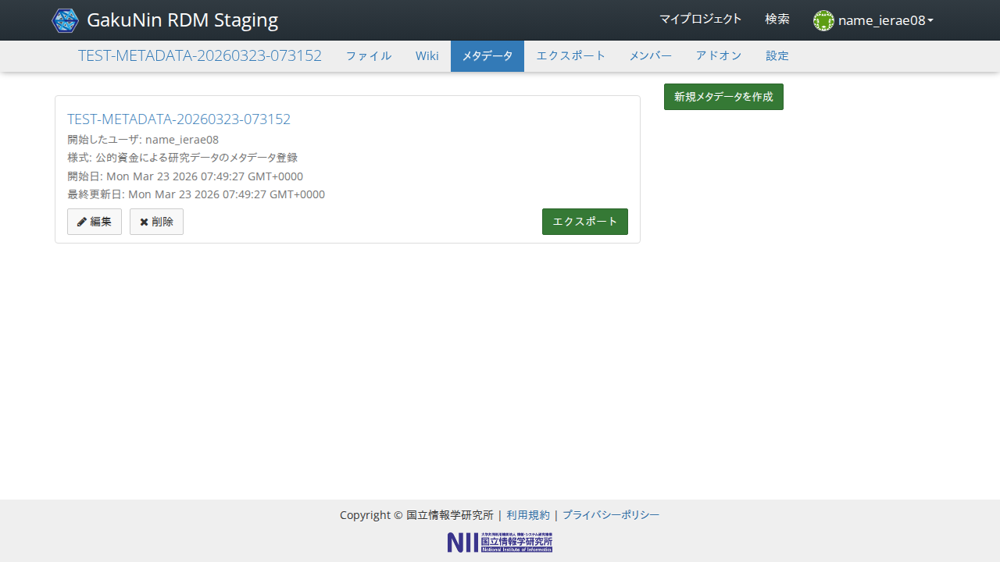

In [70]:
async def _step(page):
    await expect(page.locator('//*[@data-analytics-name = "Edit"]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「編集」をクリックする

メタデータ編集ウィンドウが表示されること

Start epoch: 1774252261.5714257 seconds


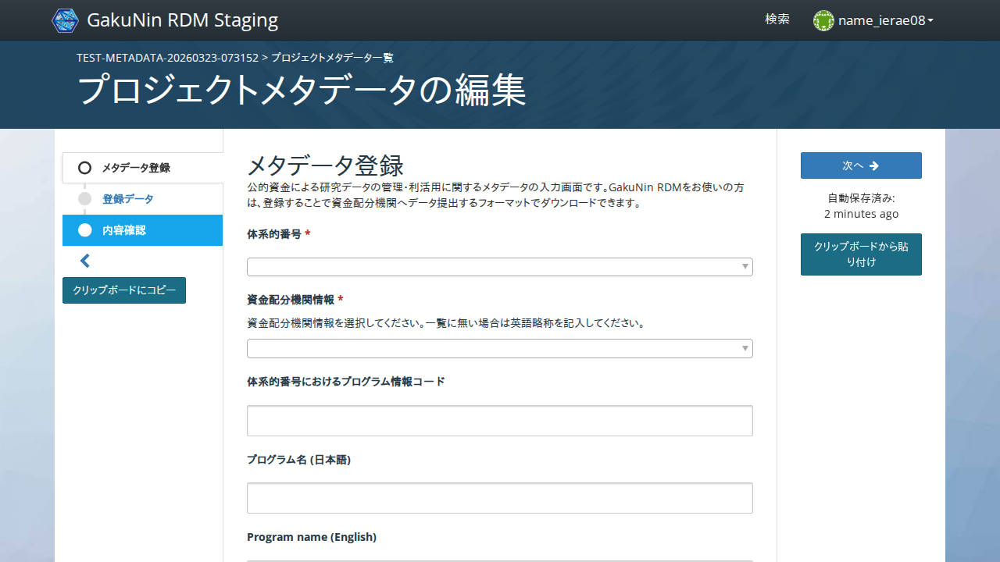

In [71]:
async def _step(page):
    await page.locator('//*[@data-analytics-name = "Edit"]').click()

    form = ProjectMetadataForm(page)
    await expect(form.get_locator('資金配分機関情報').locator('.ember-power-select-status-icon')).to_be_attached(timeout=transition_timeout)
    await expect(form.get_locator('体系的番号におけるプログラム情報コード')).to_be_editable(timeout=1000)
    await expect(form.get_locator('プログラム名 (日本語)')).to_be_editable(timeout=1000)
    await expect(form.get_locator('Program name (English)')).to_be_editable(timeout=1000)
    await expect(form.get_locator('体系的番号')).to_be_editable(timeout=1000)
    await expect(form.get_locator('プロジェクト名 (日本語)')).to_be_editable(timeout=1000)
    await expect(form.get_locator('Project name (English)')).to_be_editable(timeout=1000)
    await expect(form.get_locator('プロジェクトの分野').locator('.ember-power-select-status-icon')).to_be_attached(timeout=1000)

await run_pw(_step)

## 「体系的番号」をクリックする

ダミーデータから候補が表示されること

Start epoch: 1774252265.0859413 seconds


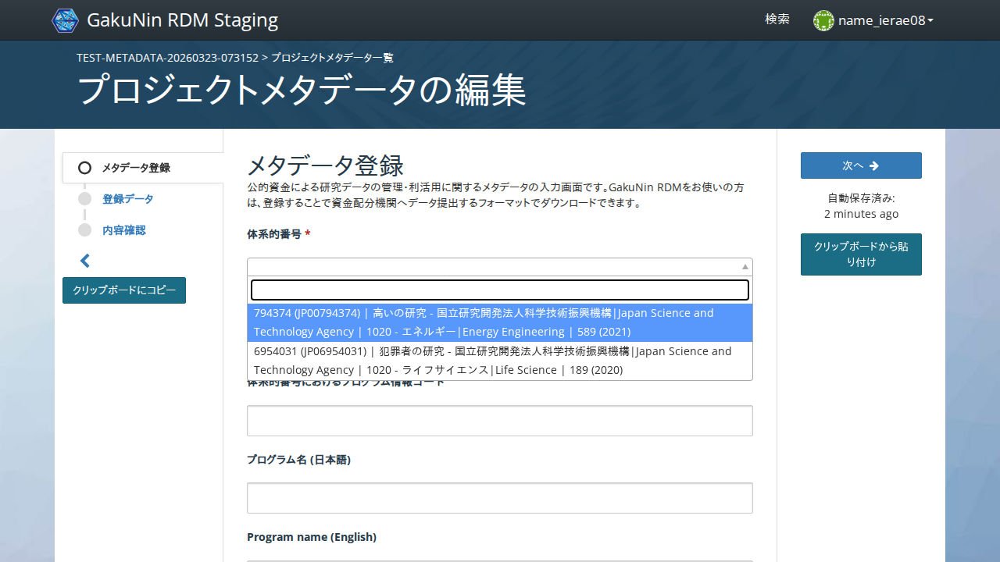

In [72]:
async def _step(page):
    form = ProjectMetadataForm(page)
    locator = form.get_locator('体系的番号')
    await locator.fill('JP')
    await expect(locator).to_have_value('JP', timeout=transition_timeout)
    # 候補が2件表示されること
    await expect(locator.locator('xpath=..').locator('ul li')).to_have_count(2, timeout=transition_timeout)

await run_pw(_step)

## 2番目の候補をクリックする

資金配分機関情報, 体系的番号におけるプログラム情報コード, 体系的番号, プログラム名(日本語), プロジェクト名(日本語), プロジェクトの分野が入力されること

Start epoch: 1774252266.6998534 seconds


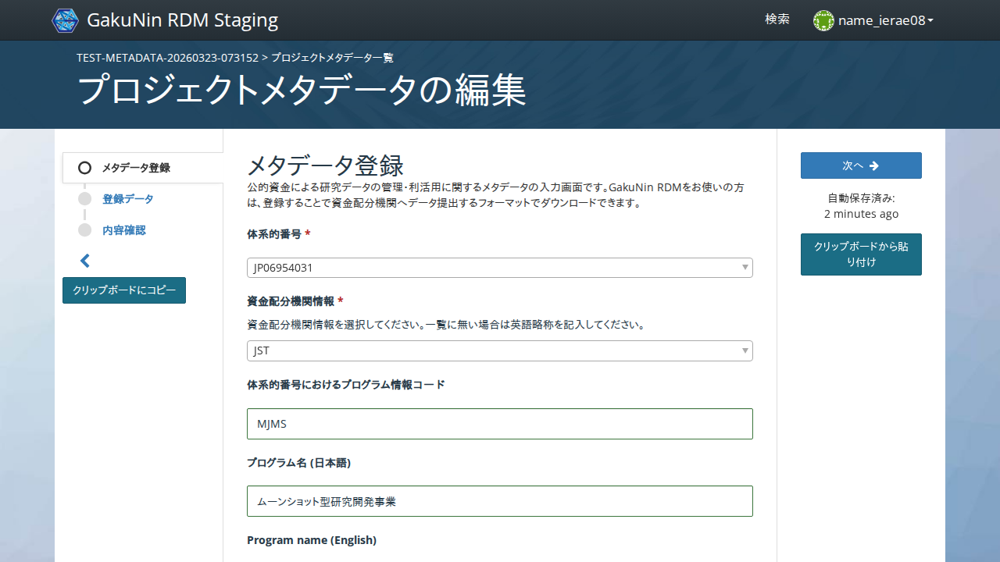

In [73]:
async def _step(page):
    form = ProjectMetadataForm(page)
    locator = form.get_locator('体系的番号')
    # 「犯罪者の研究」の候補をクリック
    await locator.locator('xpath=..').locator('ul li', has_text='犯罪者の研究').click()

    # 各フィールドが自動入力されること
    await expect(form.get_locator('資金配分機関情報').locator('.ember-power-select-selected-item')).not_to_have_text('', timeout=transition_timeout)
    await expect(form.get_locator('体系的番号におけるプログラム情報コード')).not_to_have_value('', timeout=1000)
    await expect(form.get_locator('プログラム名 (日本語)')).not_to_have_value('', timeout=1000)
    await expect(form.get_locator('プロジェクト名 (日本語)')).not_to_have_value('', timeout=1000)
    await expect(form.get_locator('プロジェクトの分野').locator('.ember-power-select-selected-item')).not_to_have_text('', timeout=1000)

await run_pw(_step)

## 「Project name (English)」に「Sample Metadata Project」を入力する

テキストフィールドに値が表示されること

Start epoch: 1774252268.369523 seconds


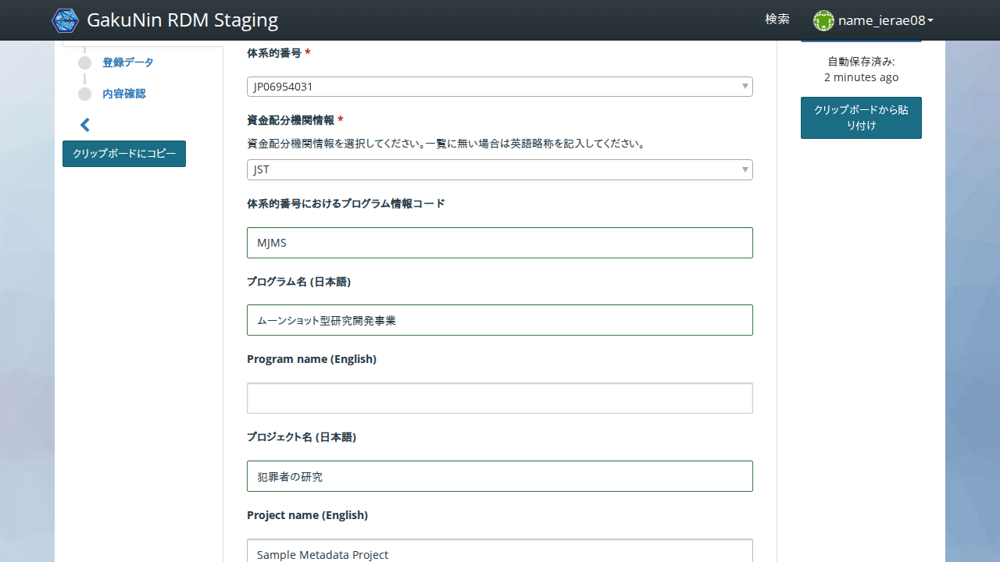

In [74]:
async def _step(page):
    form = ProjectMetadataForm(page)
    await form.fill('Project name (English)', 'Sample Metadata Project')

    await expect(form.get_locator('Project name (English)')).to_have_value('Sample Metadata Project', timeout=transition_timeout)

await run_pw(_step)

## 「次へ」をクリックする

左側ペイン「メタデータ登録」が緑色かつチェックマークが表示されること

Start epoch: 1774252269.9188035 seconds


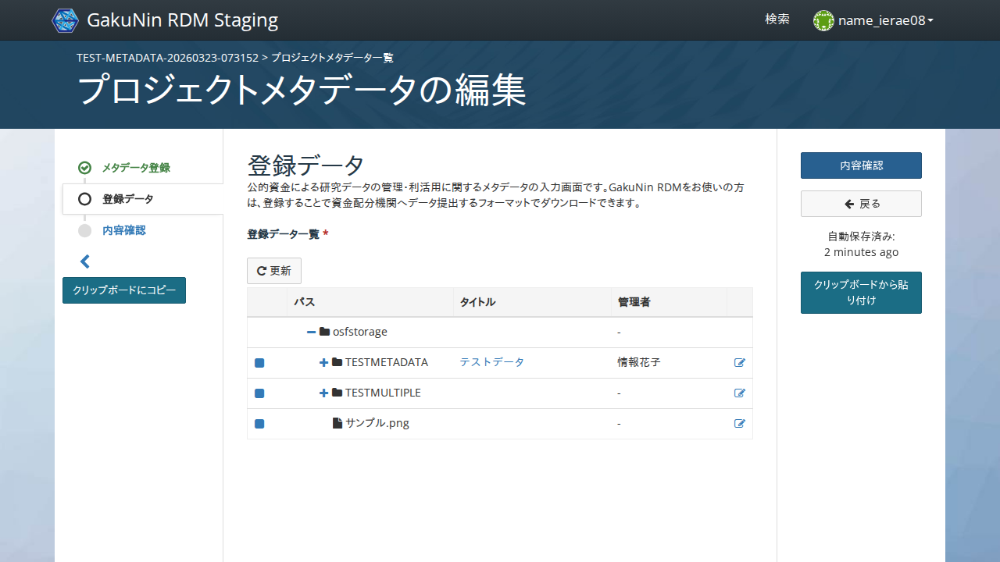

In [75]:
import re

async def _step(page):
    await page.locator('//*[@data-test-goto-next-page]').click()

    await expect(page.locator('//span[@data-test-label and text() = "助成情報登録"]/../preceding-sibling::i')).to_have_class(re.compile(r'.*fa-check-circle-o.*'), timeout=transition_timeout)

await run_pw(_step)

## 「登録データ一覧」の「テストデータ」をクリックする

プロジェクトのファイルタブが表示されること

Start epoch: 1774252271.6180432 seconds


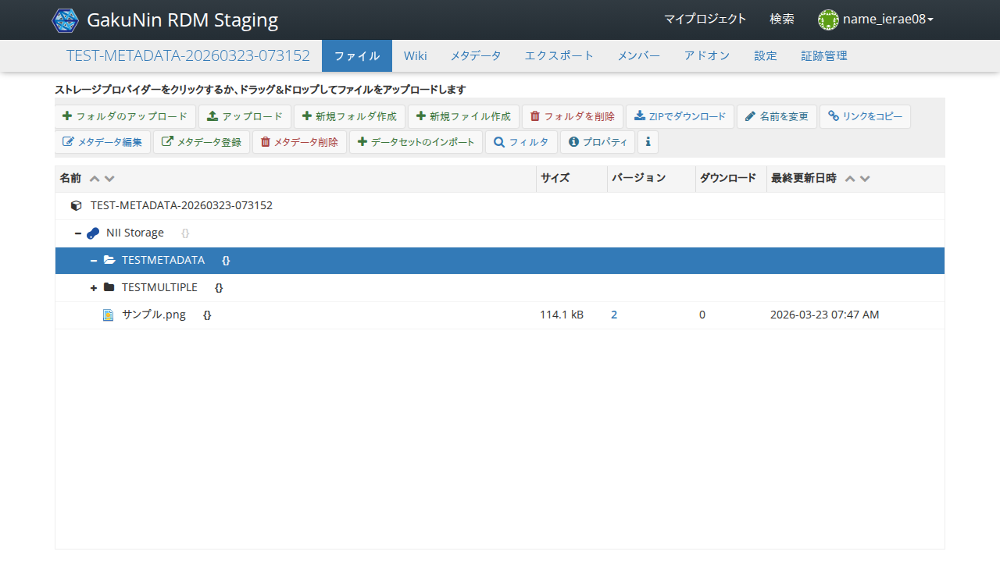

In [76]:
async def _step(page):
    # リンクのhrefを取得
    link_locator = page.locator('//a[@target = "_blank" and text() = "テストデータ"]')
    href = await link_locator.get_attribute('href')
    
    # 新しいタブを開く
    popup_future = page.wait_for_event('popup')
    await page.evaluate(f'window.open("{href}", "_blank")')
    popup = await popup_future
    
    await expect(popup.locator('//a[text() = "アドオン"]')).to_be_visible(timeout=30000)
    await expect(popup.locator('//*[contains(@class, "title-text")]//*[text() = "NII Storage"]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)
    return popup

await run_pw(_step)

## 「NII Storage」をクリックする

「メタデータ編集」ボタンが表示されること (表示まで数秒かかる可能性がある)

Start epoch: 1774252275.3521924 seconds


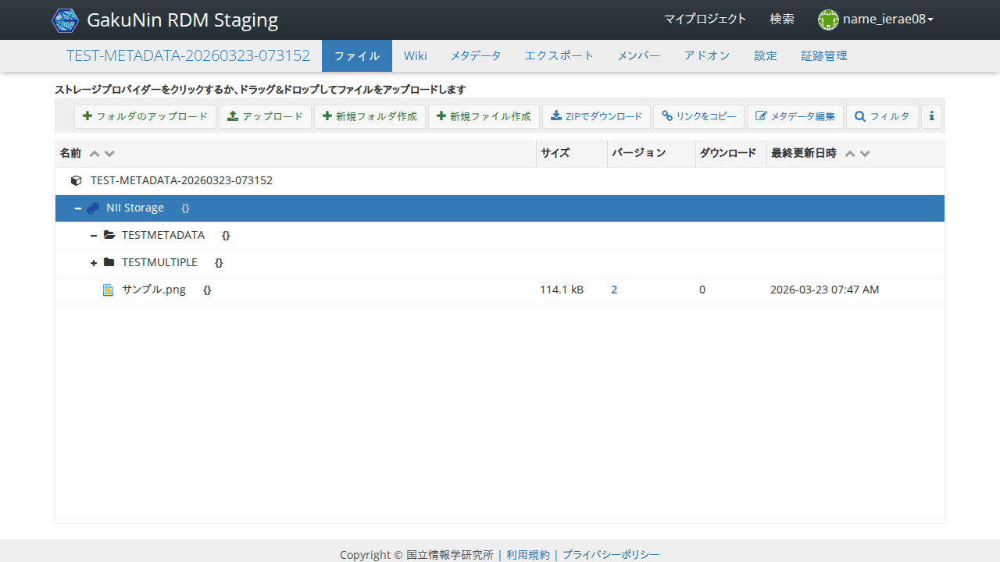

In [77]:
async def _step(page):
    await page.locator('//*[text() = "NII Storage"]').click()
    
    await expect(page.locator('//*[text() = "メタデータ編集"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## ファイルをアップロードする

テスト環境の「sample.png」をNII Storage配下にドラッグ＆ドロップする。

In [78]:
await save_screenshot(os.path.join(work_dir, 'sample.png'))

'/tmp/tmpysqin790/sample.png'

Start epoch: 1774252277.7458684 seconds


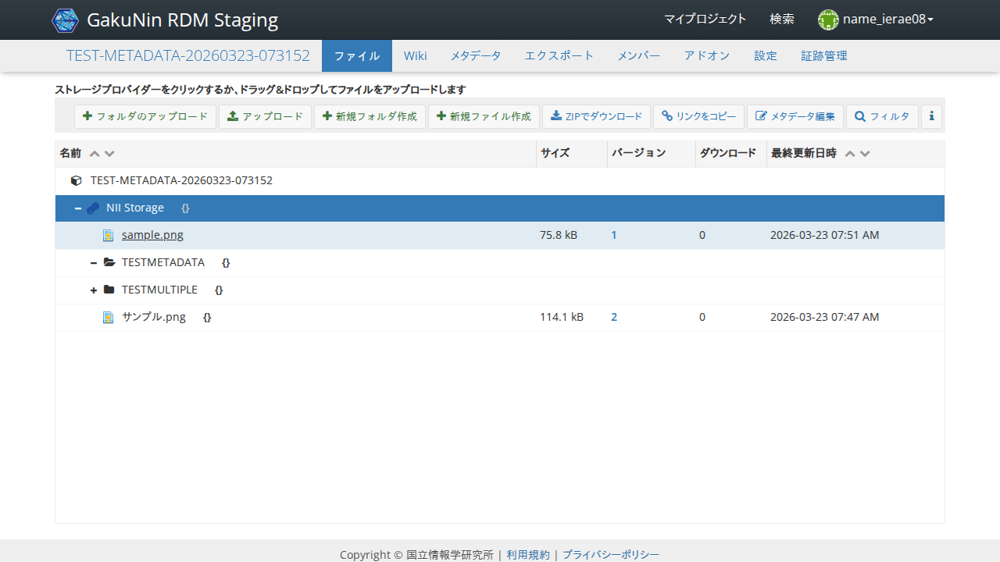

In [79]:
# import scripts.grdm
# importlib.reload(scripts.grdm)

async def _step(page):
    dropzone = grdm.get_select_storage_title_xpath('NII Storage')
    await grdm.drop_file(page, dropzone, os.path.join(work_dir, 'sample.png'))
    time.sleep(1)

    await grdm.wait_for_uploaded(page, 'sample.png')

await run_pw(_step)

## 「sample.png」をクリックする

「メタデータ編集」ボタンが表示されること (表示まで数秒かかる可能性がある)

Start epoch: 1774252282.389813 seconds


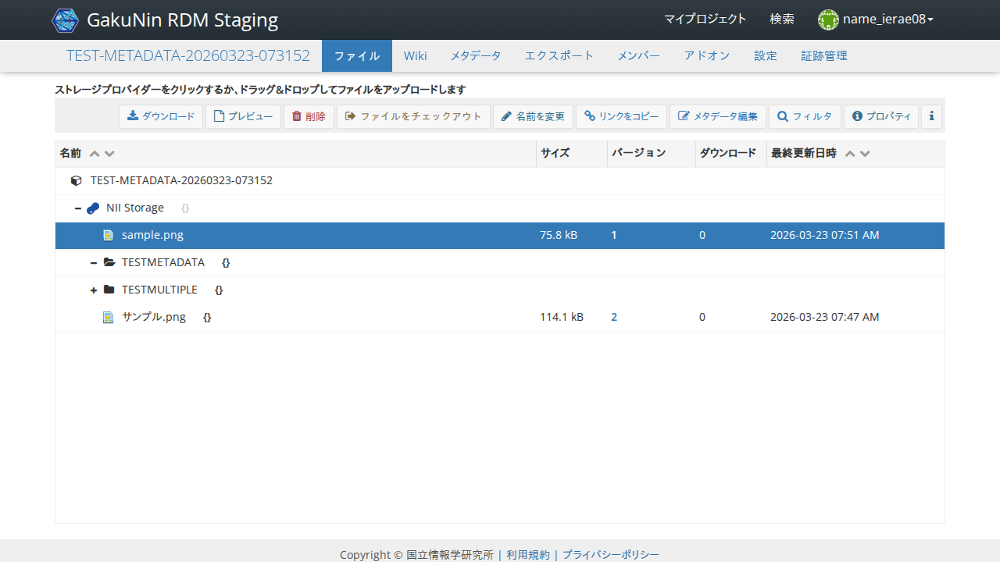

In [80]:
async def _step(page):
    await grdm.get_select_file_extension_locator(page, 'sample.png').click()
    await expect(page.locator('//*[text() = "メタデータ編集"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

##  「メタデータ編集」をクリックする

「メタデータ編集」ダイアログが表示されること

Start epoch: 1774252283.9497182 seconds


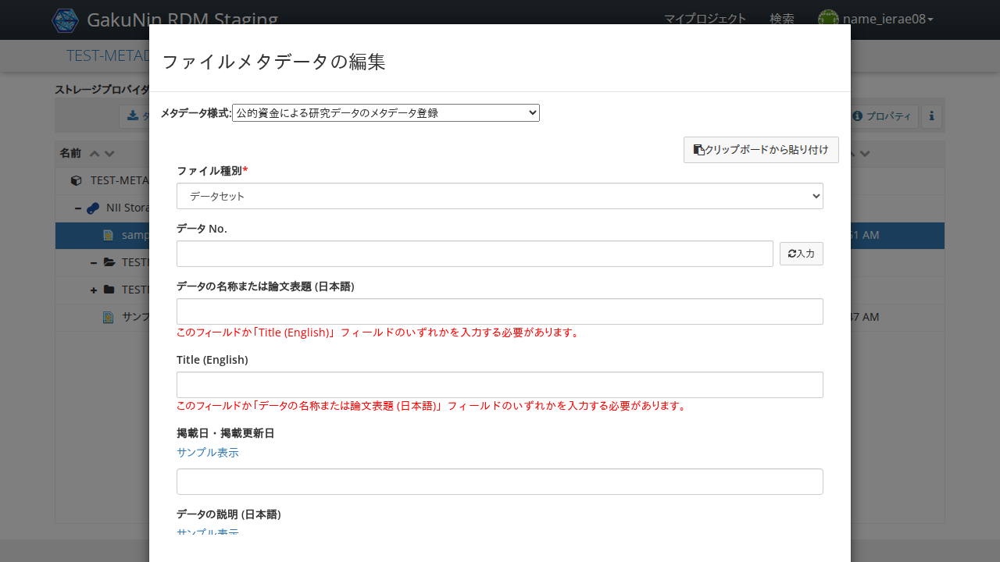

In [81]:
async def _step(page):
    await page.locator('//*[text() = "メタデータ編集"]').click()

    await expect(page.locator('//label[contains(text(), "メタデータ様式")]/following-sibling::select')).to_be_editable(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

##  「メタデータ様式」に「研究成果（公的資金対応）のメタデータ登録」を入力する

「データNo.」フィールドが表示されること

Start epoch: 1774252286.5905519 seconds


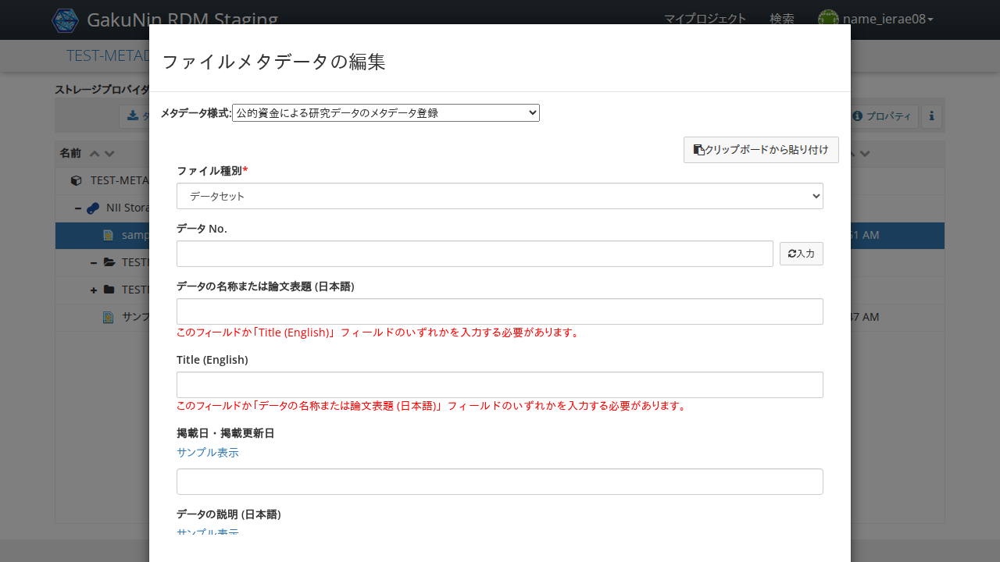

In [82]:
async def _step(page):
    await page.locator('//label[contains(text(), "メタデータ様式")]/following-sibling::select').select_option('研究成果（公的資金対応）のメタデータ登録')
    form = FileMetadataForm(page)

    await expect(form.get_locator('データ No.')).to_be_editable(timeout=transition_timeout)

await run_pw(_step)

##  「データ No.」の「入力」をクリックする

データNo.に5桁のIDが表示されること

Start epoch: 1774252288.2098238 seconds


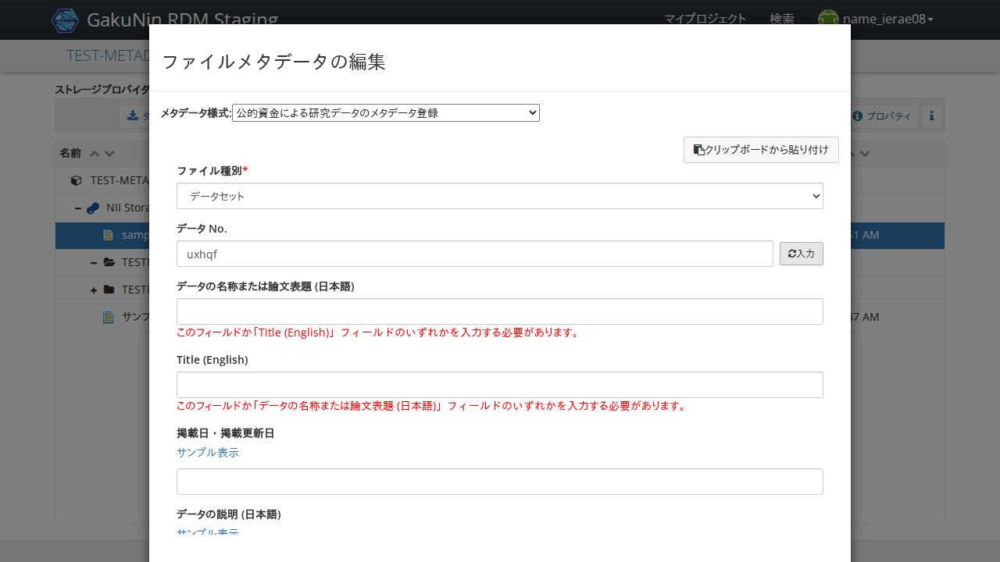

In [83]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データ No.', 'test1')

    await expect(form.get_locator('データ No.')).to_have_value('test1', timeout=transition_timeout)

await run_pw(_step)

##  「データの名称(日本語)」に「テストデータ」を入力する

「このフィールドか「Title(English)」フィールドのいずれかを入力する必要があります。」が表示されなくなること

Start epoch: 1774252290.1722286 seconds


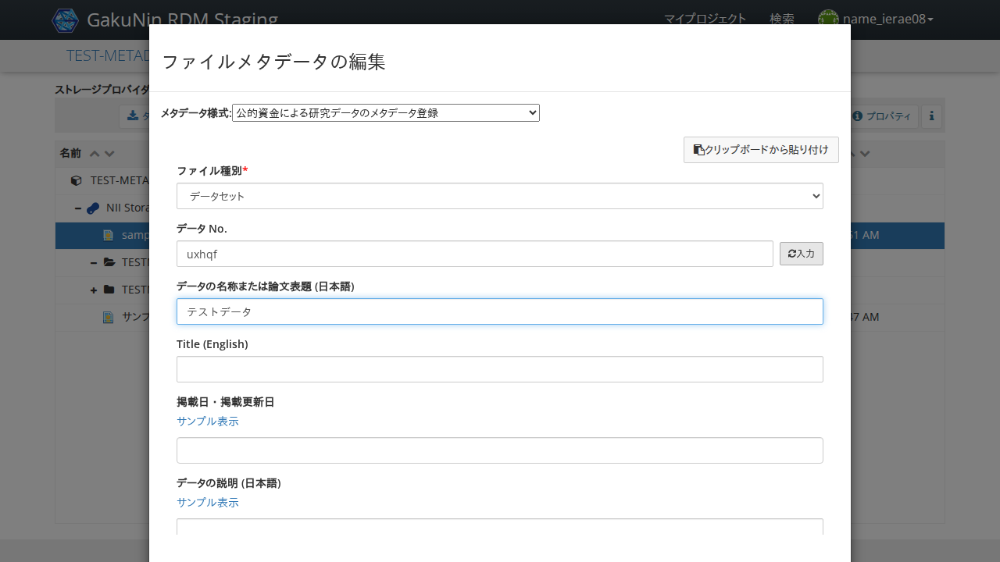

In [84]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データの名称 (日本語)', 'テストデータ')
    await page.keyboard.press('Enter')

    await expect(form.get_locator('データの名称 (日本語)')).to_have_value('テストデータ', timeout=transition_timeout)

await run_pw(_step)

##  「Title (English)」に「Test Data」を入力する

入力した値が表示されること

Start epoch: 1774252291.8726451 seconds


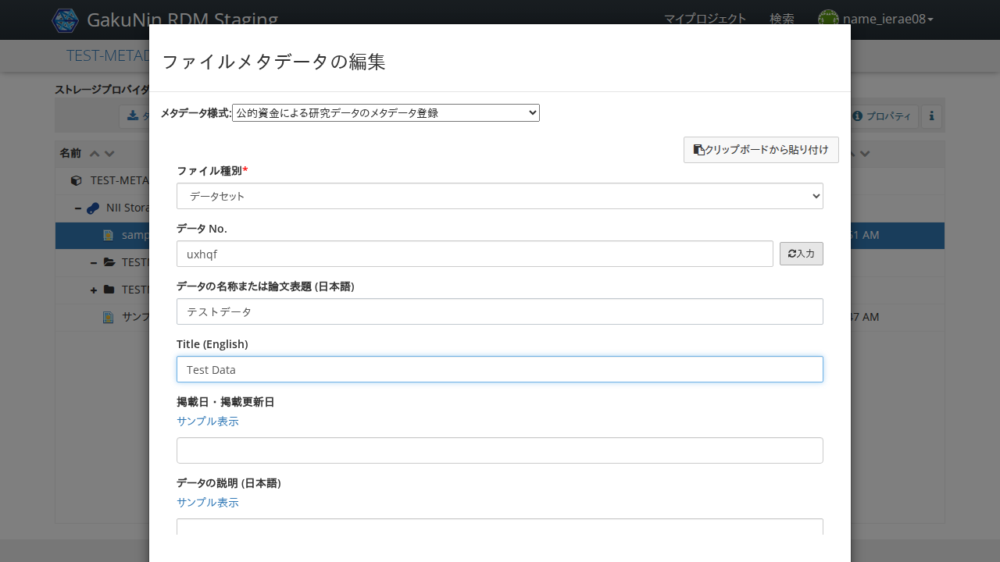

In [85]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('Data title (English)', 'Test Data')
    await page.keyboard.press('Enter')

    await expect(form.get_locator('Data title (English)')).to_have_value('Test Data', timeout=transition_timeout)

await run_pw(_step)

##  「掲載日・掲載更新日」に「2022-05-25」を入力する

入力した値が表示されること

Start epoch: 1774252293.4666154 seconds


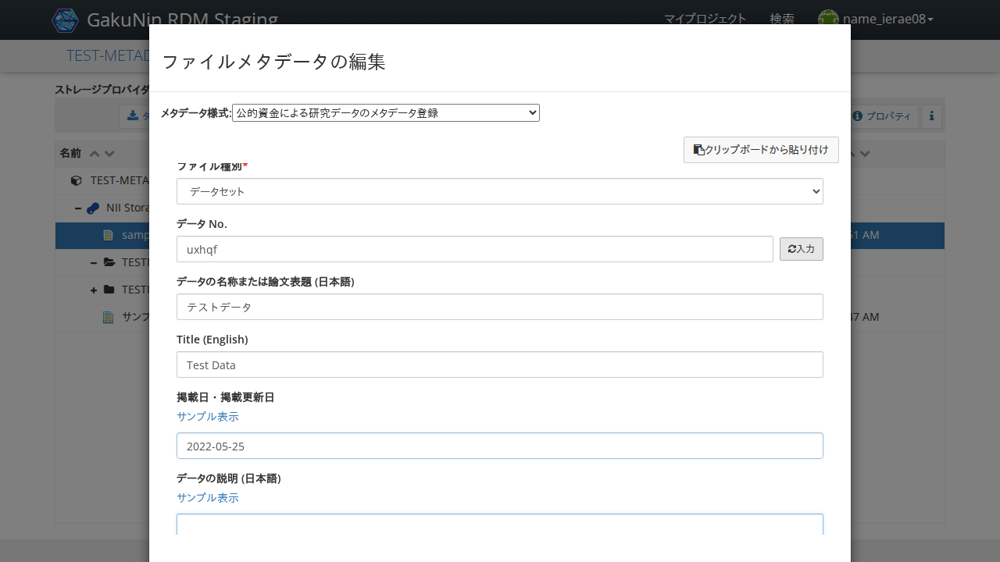

In [86]:
async def _step(page):
    form = FileMetadataForm(page)
    locator = form.get_locator('掲載日・掲載更新日')
    await locator.focus()
    await page.keyboard.type('2022-05-25')
    await page.keyboard.press('Tab')

    await expect(locator).to_have_value('2022-05-25', timeout=transition_timeout)

await run_pw(_step)

##  「データの説明 (日本語)」に「自動テストによって作成されたメタデータです。」を入力する

「このフィールドか「Description(English)」フィールドのいずれかを入力する必要があります。」が表示されなくなること

Start epoch: 1774252295.2672985 seconds


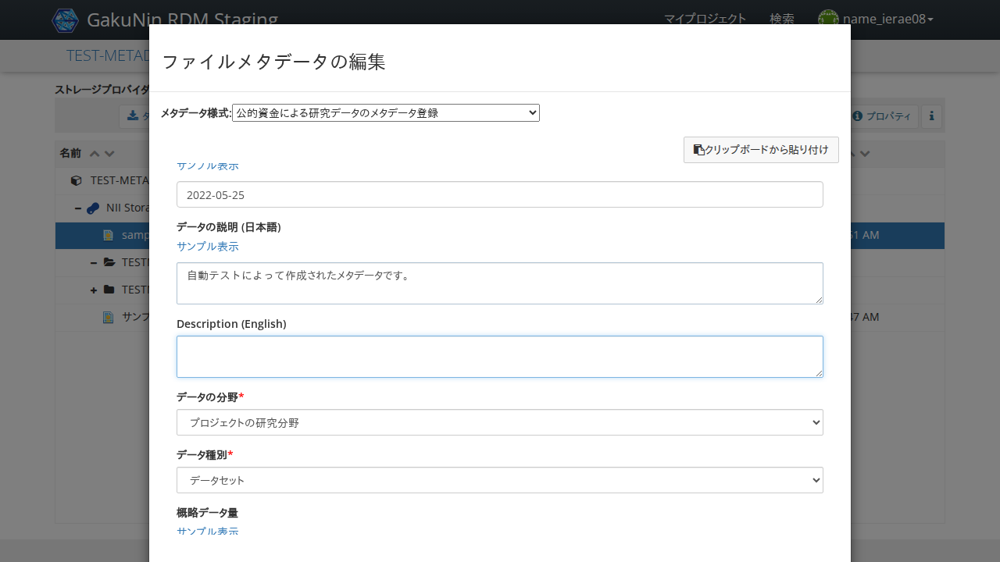

In [87]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データの説明 (日本語)', '自動テストによって作成されたメタデータです。')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データの説明 (日本語)')).to_have_value('自動テストによって作成されたメタデータです。', timeout=transition_timeout)

await run_pw(_step)

##  「Description (English)」に「Metadata created by automated testing.」を入力する

入力した値が表示されること

Start epoch: 1774252296.9741774 seconds


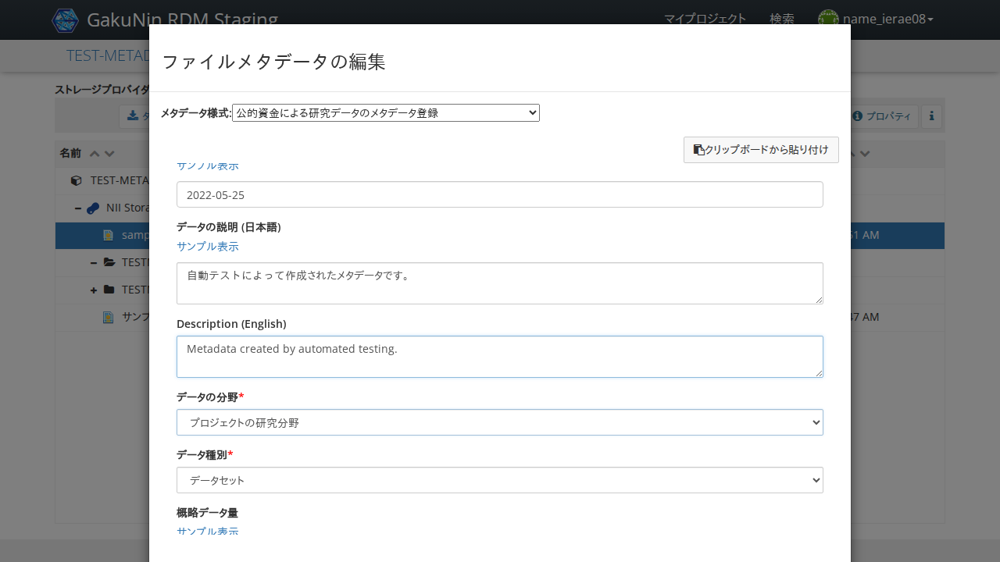

In [88]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('Description (English)', 'Metadata created by automated testing.')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Description (English)')).to_have_value('Metadata created by automated testing.', timeout=transition_timeout)

await run_pw(_step)

##  「データの分野」に「プロジェクトの研究分野」を入力する

すでに設定されている場合は操作不要。「プロジェクトの研究分野」が表示されること

Start epoch: 1774252298.6452897 seconds


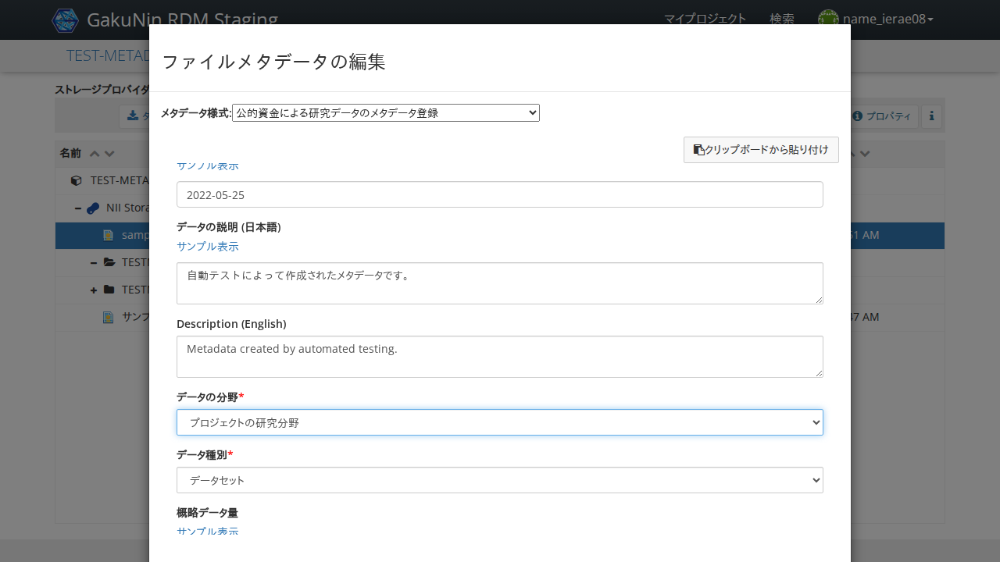

In [89]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データの分野', 'プロジェクトの研究分野')

    await expect(form.get_locator('データの分野').locator('option:checked')).to_have_text('プロジェクトの研究分野', timeout=transition_timeout)

await run_pw(_step)

##  「データ種別」に「ゲノムデータ」を入力する

入力した値が表示されること

Start epoch: 1774252300.2988024 seconds


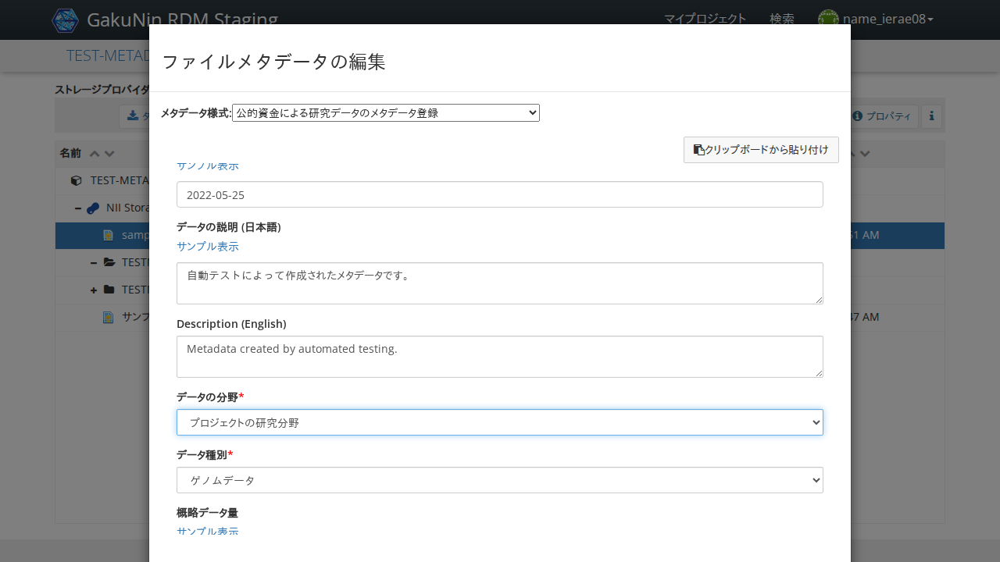

In [90]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データ種別', 'ゲノムデータ')

    await expect(form.get_locator('データ種別').locator('option:checked')).to_have_text('ゲノムデータ', timeout=transition_timeout)

await run_pw(_step)

##  「概略データ量」の「計算」をクリックする

アップロードしたsample.pngのファイルサイズが表示されること

Start epoch: 1774252301.9001517 seconds


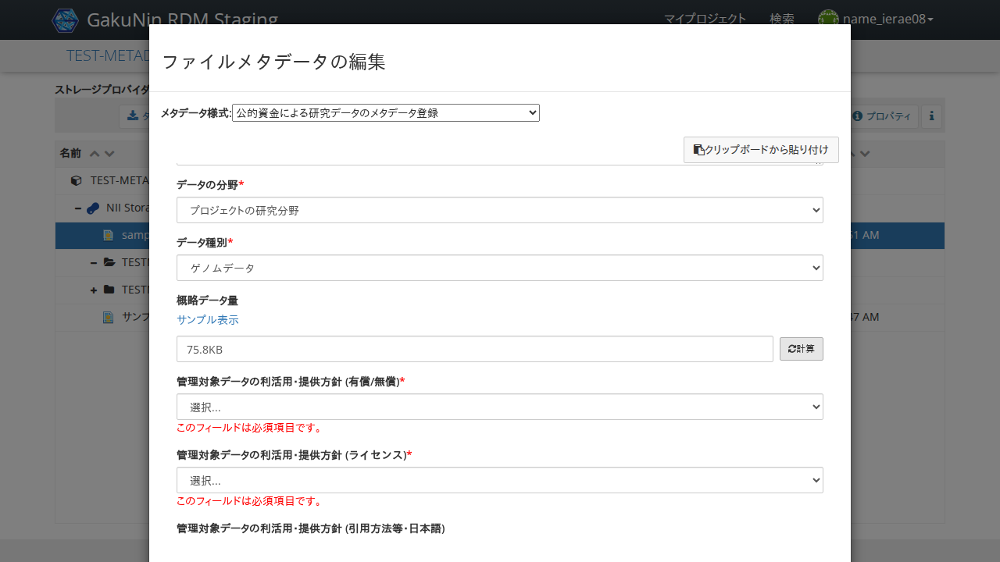

In [91]:
async def _step(page):
    await page.locator('//label[contains(text(), "概略データ量")]/../following-sibling::div[1]//*[text() = "計算"]').click()
    form = FileMetadataForm(page)

    await expect(form.get_locator('概略データ量')).not_to_have_value('', timeout=transition_timeout)

await run_pw(_step)

##  「管理対象データの利活用・提供方針 (有償/無償)」に「無償」を入力する

「このフィールドは必須項目です。」が表示されなくなること

Start epoch: 1774252303.9385157 seconds


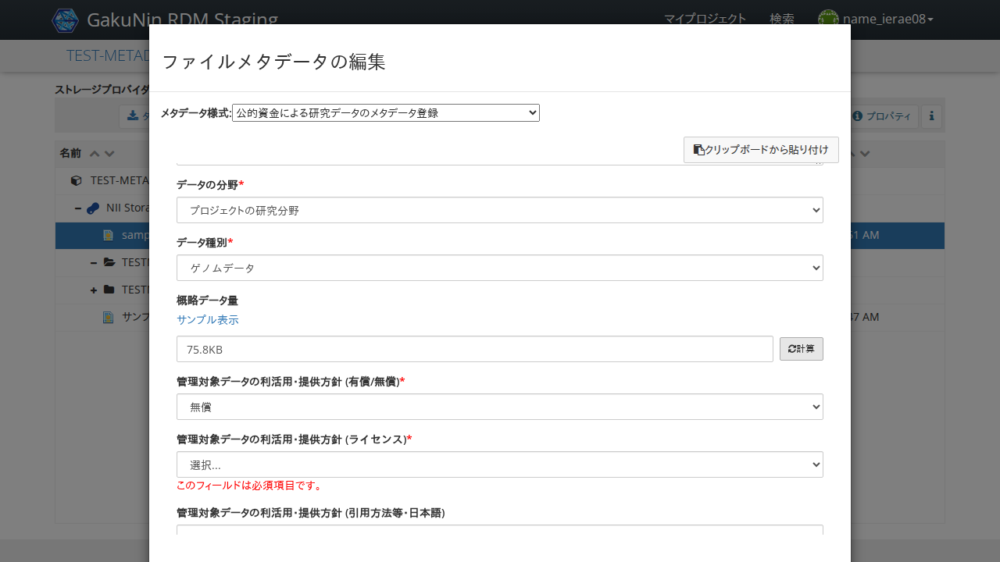

In [92]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('管理対象データの利活用・提供方針 (有償/無償)', '無償')

    await expect(form.get_locator('管理対象データの利活用・提供方針 (有償/無償)').locator('input[type="radio"]:checked + span, label:has(input[type="radio"]:checked)')).to_contain_text('無償', timeout=transition_timeout)

await run_pw(_step)

##  「管理対象データの利活用・提供方針 (ライセンス)」に「CC BY 4.0 表示 国際」を入力する

「このフィールドは必須項目です。」が表示されなくなること

Start epoch: 1774252305.6373641 seconds


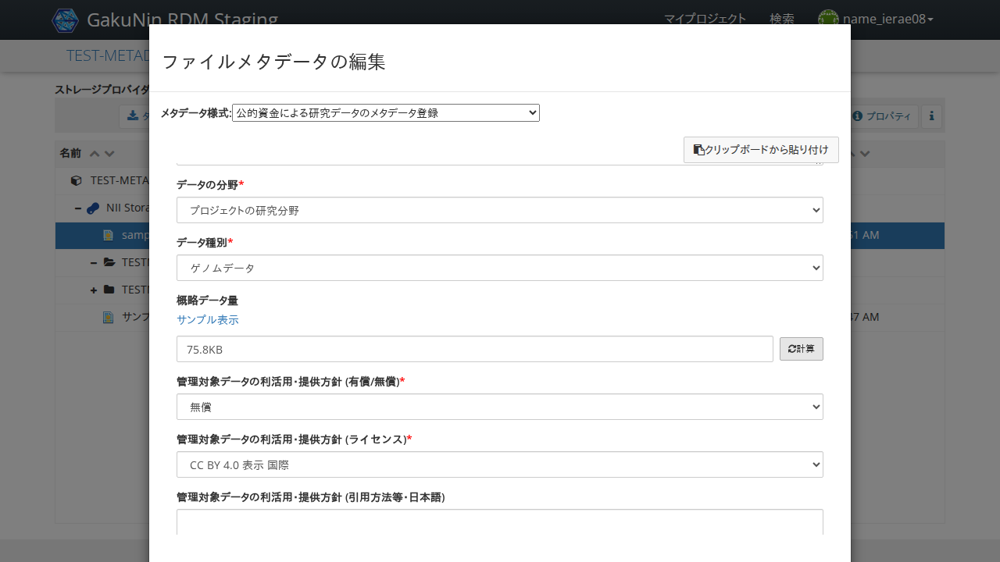

In [93]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('管理対象データの利活用・提供方針 (ライセンス)', 'CC BY 4.0 表示 国際')

    await expect(form.get_locator('管理対象データの利活用・提供方針 (ライセンス)').locator('option:checked')).to_have_text('CC BY 4.0 表示 国際', timeout=transition_timeout)

await run_pw(_step)

##  「管理対象データの利活用・提供方針 (引用方法等・日本語)」に「利用方針をここに記載します。」を入力する

「このフィールドか「Data utilization and provision policy (citation information, English)」フィールドのいずれかを入力する必要があります。」が表示されなくなること

Start epoch: 1774252307.286664 seconds


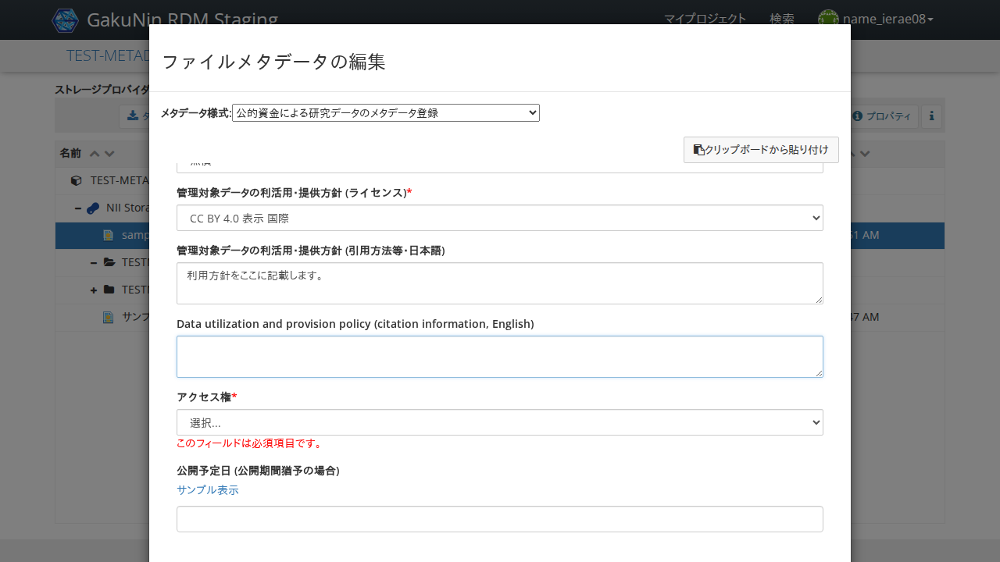

In [94]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('管理対象データの利活用・提供方針 (引用方法等・日本語)', '利用方針をここに記載します。')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('管理対象データの利活用・提供方針 (引用方法等・日本語)')).to_have_value('利用方針をここに記載します。', timeout=transition_timeout)

await run_pw(_step)

##  「Data utilization and provision policy (citation information, English)」に「The policy for use is described here.」を入力する

入力した値が表示されること

Start epoch: 1774252308.9767604 seconds


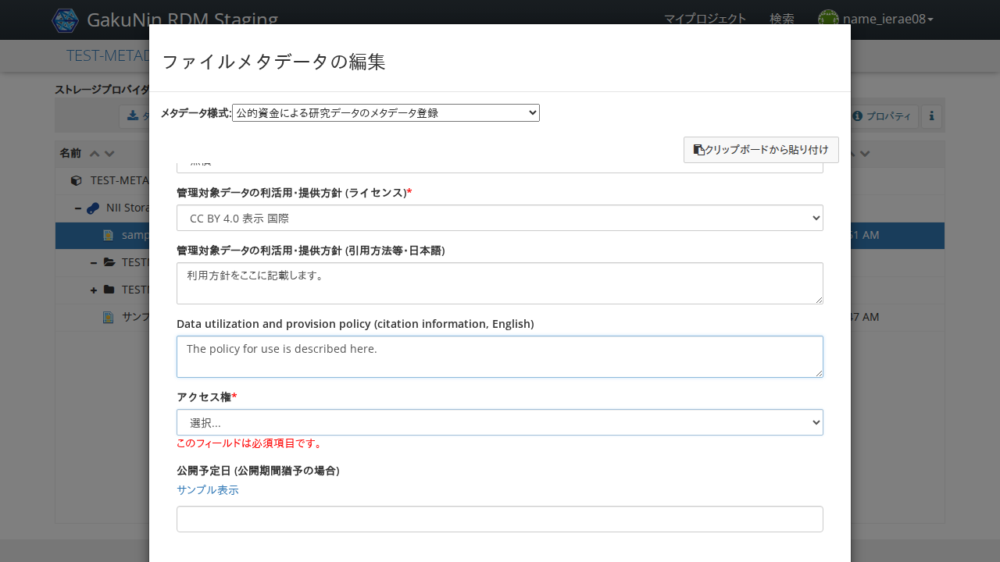

In [95]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('Data utilization and provision policy (citation information, English)', 'The policy for use is described here.')
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Data utilization and provision policy (citation information, English)')).to_have_value('The policy for use is described here.', timeout=transition_timeout)

await run_pw(_step)

##  「アクセス権」に「公開期間猶予」を入力する

「このフィールドは必須項目です。」が表示されなくなること

Start epoch: 1774252310.7085276 seconds


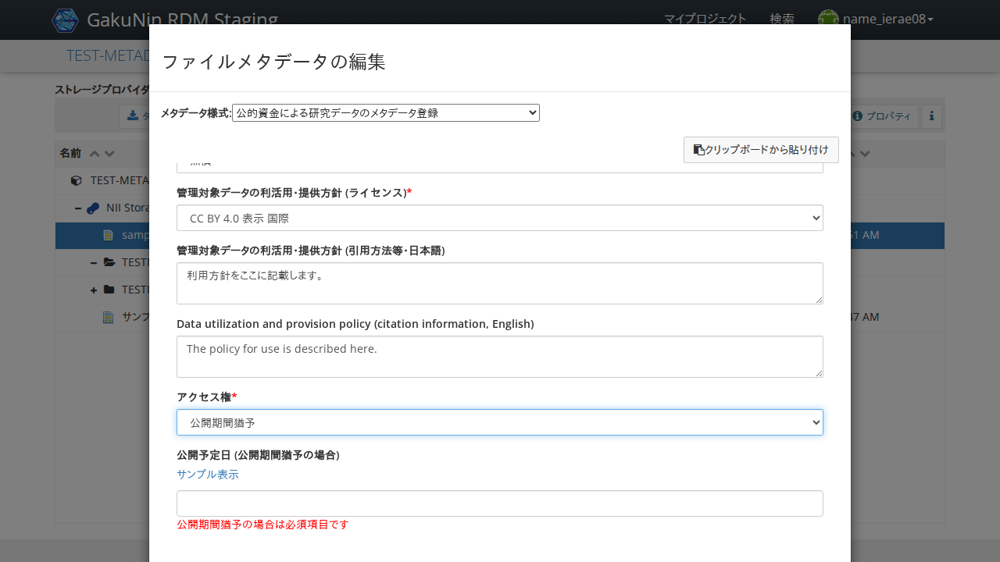

In [96]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('アクセス権', '公開期間猶予')

    await expect(form.get_locator('アクセス権').locator('option:checked')).to_have_text('公開期間猶予', timeout=transition_timeout)

await run_pw(_step)

##  「公開予定日 (公開期間猶予の場合)」に「2022-05-25」を入力する

「公開期間猶予の場合は必須項目です」が表示されなくなること

Start epoch: 1774252312.364355 seconds


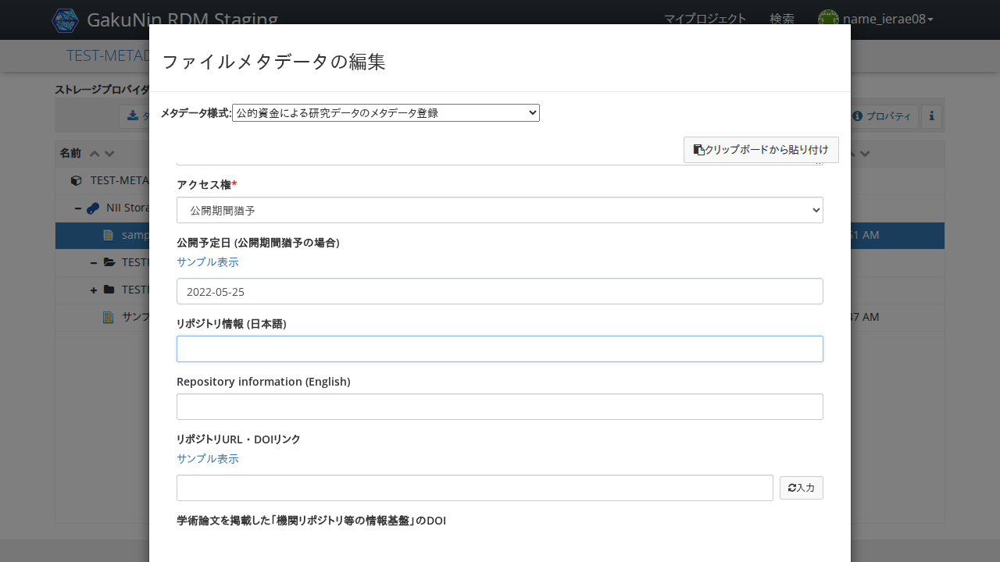

In [97]:
async def _step(page):
    form = FileMetadataForm(page)
    locator = form.get_locator('公開予定日')
    await locator.focus()
    await page.keyboard.type('2022-05-25')
    await page.keyboard.press('Tab')

    await expect(locator).to_have_value('2022-05-25', timeout=transition_timeout)

await run_pw(_step)

##  「リポジトリ情報 (日本語)」に「テストリポジトリ」を入力する

入力した値が表示されること

Start epoch: 1774252314.202819 seconds


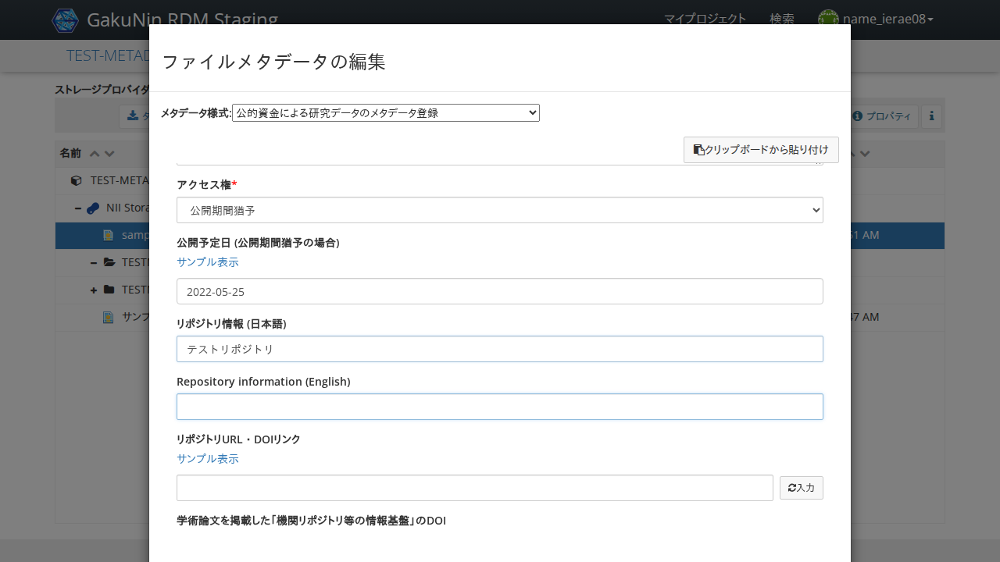

In [98]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'テストリポジトリ'
    await form.fill('リポジトリ情報 (日本語)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('リポジトリ情報 (日本語)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「Repository information (English)」に「Test Repository」を入力する

入力した値が表示されること

Start epoch: 1774252315.959153 seconds


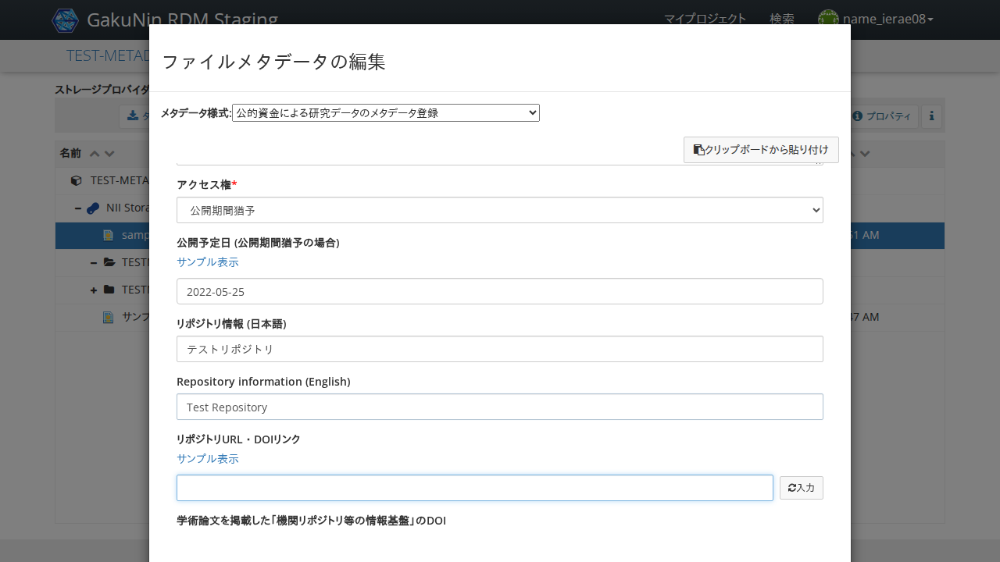

In [99]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'Test Repository'
    await form.fill('Repository information (English)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Repository information (English)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「リポジトリURL・DOIリンク」の「入力」をクリックする

ファイルのURLが表示されること

Start epoch: 1774252317.7012236 seconds


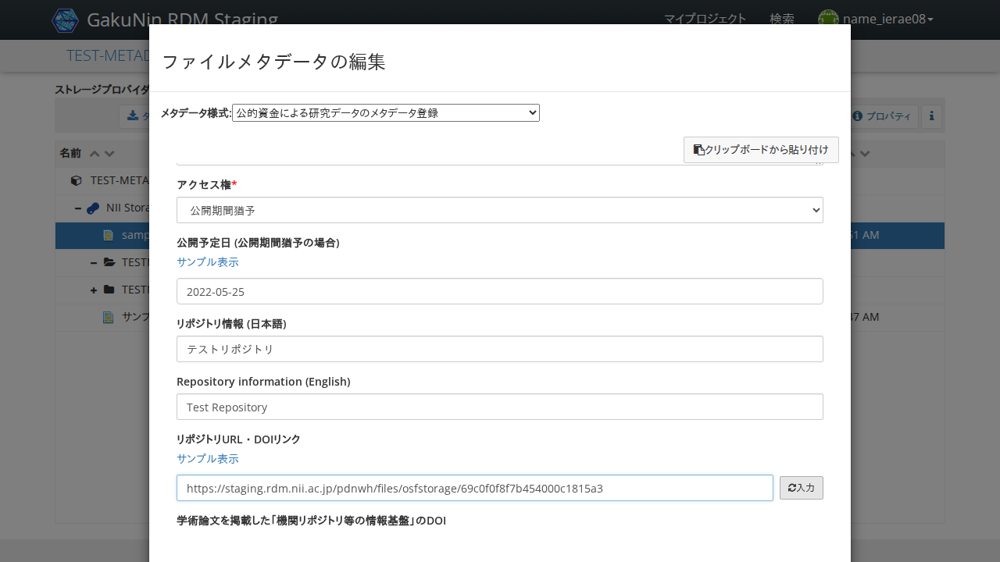

In [100]:
import re

async def _step(page):
    form = FileMetadataForm(page)
    input_locator = form.get_locator('リポジトリURL・DOIリンク')
    await page.locator('//label[contains(text(), "リポジトリURL・DOIリンク")]/../following-sibling::div[1]//*[text() = "GakuNin RDM URL入力"]').click()
    value = re.compile(r'.+files\/osfstorage\/[0-9a-z]{24}')

    await expect(input_locator).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「データ作成者」の「追加」をクリックする

作成者入力フィールドが表示されること

Start epoch: 1774252319.3969066 seconds


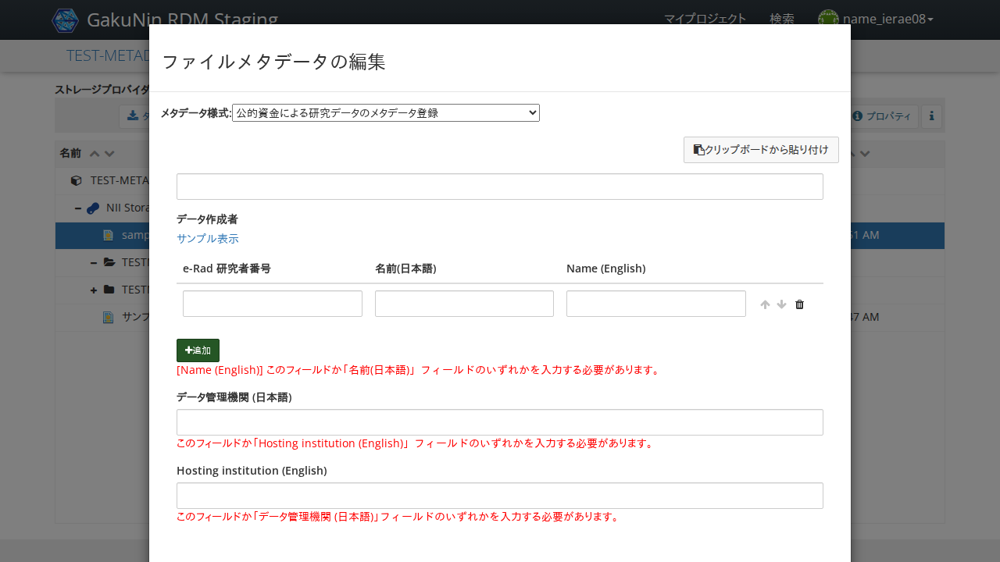

In [101]:
async def _step(page):
    form = FileMetadataForm(page)
    container = form.get_locator('データ作成者')
    panel = container.locator('.metadata-edit-mode >> visible=true').last
    erad_input = panel.locator('xpath=.//label[contains(text(), "e-Rad 研究者番号")]/following-sibling::div[1]//input')

    await expect(erad_input).to_be_editable(timeout=transition_timeout)

await run_pw(_step)

##  「e-Rad研究者番号」に「3」を入力する

フィールドに候補「情報 陽一」が表示されること

Start epoch: 1774252321.1331449 seconds


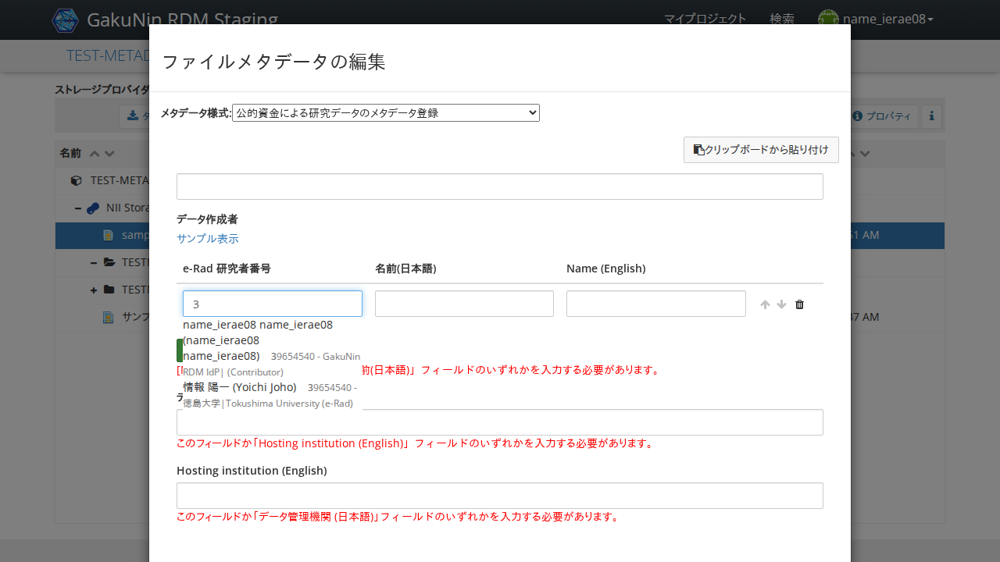

In [102]:
async def _step(page):
    form = FileMetadataForm(page)
    container = form.get_locator('データ作成者')
    panel = container.locator('.metadata-edit-mode >> visible=true').last
    erad_input = panel.locator('xpath=.//label[contains(text(), "e-Rad 研究者番号")]/following-sibling::div[1]//input')
    await erad_input.fill('')
    await erad_input.focus()
    await page.keyboard.press('3')
    time.sleep(1)

    # 候補「情報 陽一」が表示されること
    await expect(page.locator('//div[contains(@class, "tt-suggestion") and contains(., "情報 陽一")]')).not_to_have_count(0, timeout=transition_timeout)

await run_pw(_step)

## 「情報 陽一」をクリックする

「名前 (日本語)」, 「Name (English)」が入力されること

Start epoch: 1774252323.7219174 seconds


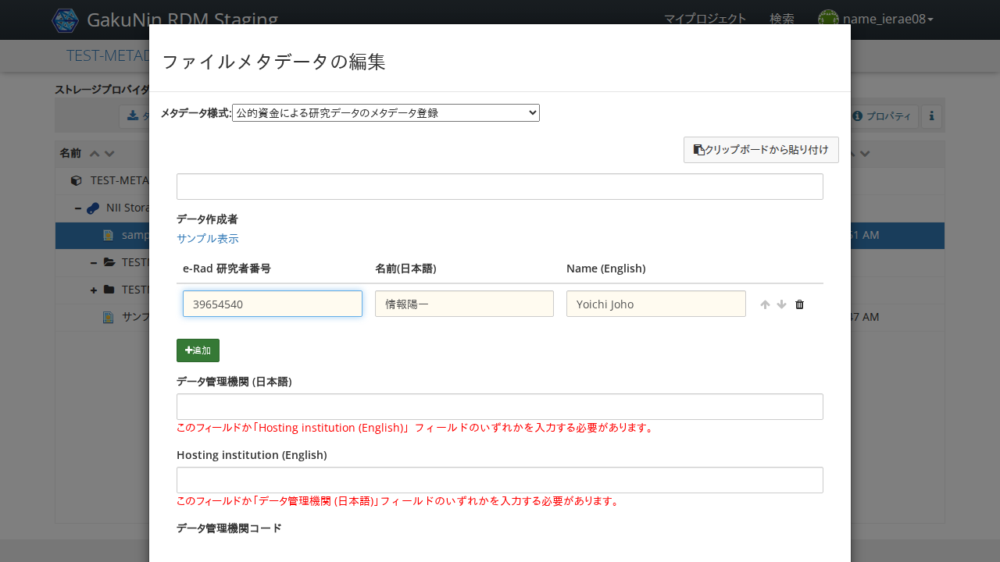

In [103]:
async def _step(page):
    await page.locator('(//div[contains(@class, "tt-suggestion") and contains(., "情報 陽一")])[1]').click()

    form = FileMetadataForm(page)
    author = await form.get_author(table_label='データ作成者', row_index=0)
    # 名前(日本語)が自動入力されていること
    assert author['name_ja']['last'] != '', f"Expected non-empty last name (ja), got {author['name_ja']}"
    assert author['name_ja']['first'] != '', f"Expected non-empty first name (ja), got {author['name_ja']}"
    # Name(English)が自動入力されていること
    assert author['name_en']['last'] != '', f"Expected non-empty last name (en), got {author['name_en']}"
    assert author['name_en']['first'] != '', f"Expected non-empty first name (en), got {author['name_en']}"

await run_pw(_step)

## 「データ管理者の種類」にて「個人」を選択する

すでに値が表示されている場合は選択不要。「個人」が表示されること

Start epoch: 1774252325.5523267 seconds


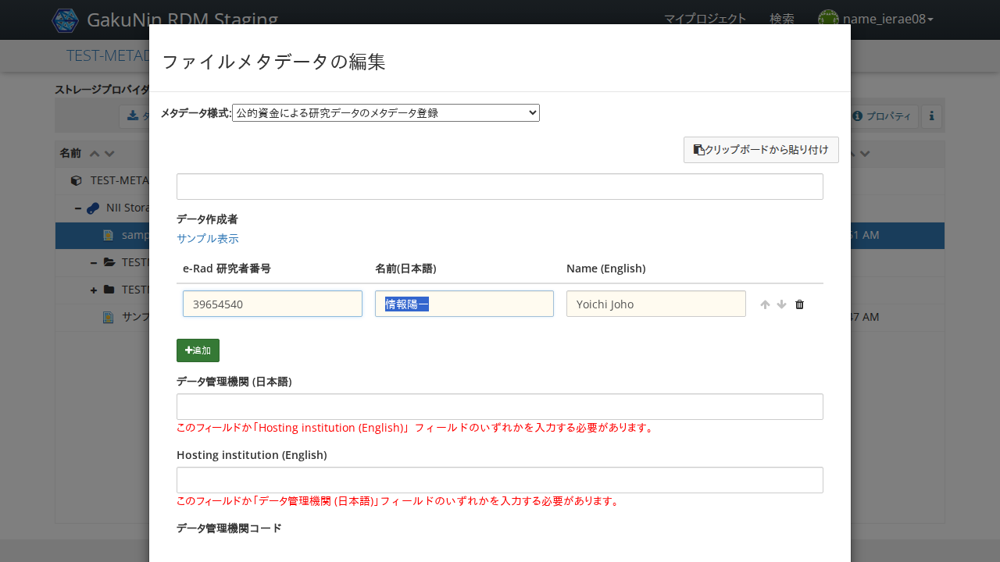

In [104]:
async def _step(page):
    form = FileMetadataForm(page)
    await form.fill('データ管理者の種類', '個人')

    await expect(form.get_locator('データ管理者の種類').locator('input[type="radio"]:checked')).to_have_value('individual', timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者の e-Rad 研究者番号」に「3」を入力する

候補「情報 陽一」が表示されること

Start epoch: 1774252327.325799 seconds


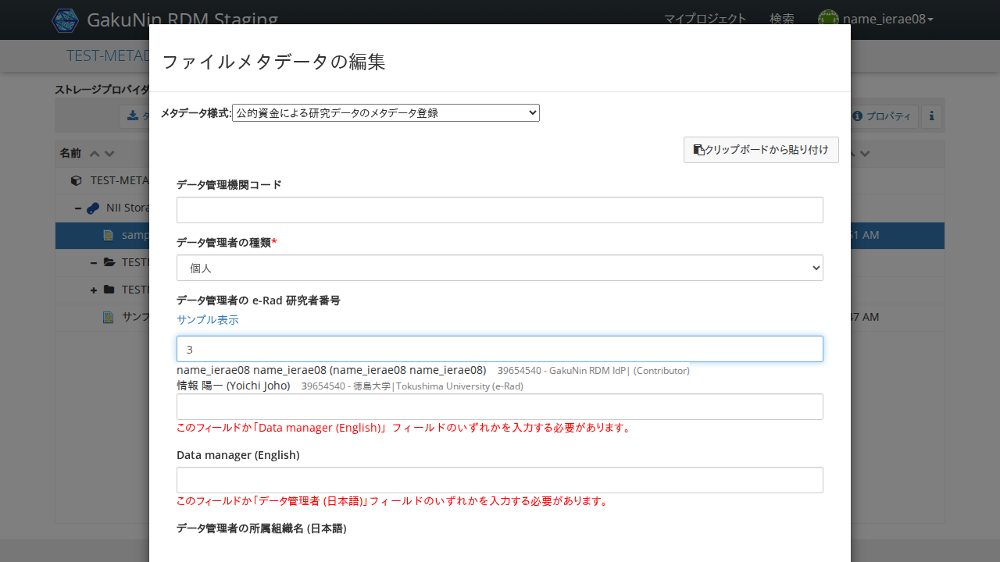

In [105]:
async def _step(page):
    form = FileMetadataForm(page)
    locator = form.get_locator('データ管理者の e-Rad 研究者番号')
    await locator.focus()
    await page.keyboard.type('3')
    time.sleep(1)

    # 候補「情報 陽一」が表示されること
    await expect(page.locator('//div[contains(@class, "tt-suggestion") and contains(., "情報 陽一")]')).not_to_have_count(0, timeout=transition_timeout)

await run_pw(_step)

## 「情報 陽一」をクリックする

「データ管理者 (日本語)」「Data manager (English)」「データ管理者の所属組織名 (日本語)」, 「Contact organization of data manager (English)」が入力されること

Start epoch: 1774252329.9353554 seconds


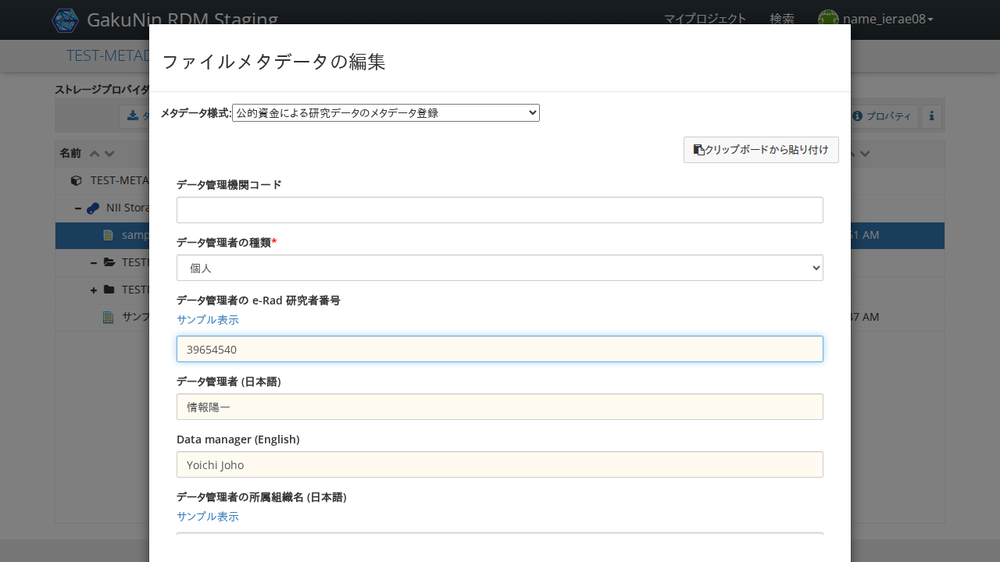

In [106]:
async def _step(page):
    await page.locator('(//div[contains(@class, "tt-suggestion") and contains(., "情報 陽一")])[1]').click()

    form = FileMetadataForm(page)
    # データ管理者の所属組織名が自動入力されること
    await expect(form.get_locator('データ管理者の所属組織名 (日本語)')).to_have_value(re.compile('.+'), timeout=transition_timeout)
    await expect(form.get_locator('Contact organization of data manager (English)')).to_have_value(re.compile('.+'), timeout=transition_timeout)
    # データ管理者の名前が自動入力されること(姓・名)
    name_ja = await form.get_name('データ管理者 (日本語)')
    assert name_ja['last'] != '', f"Expected non-empty last name (ja), got {name_ja}"
    assert name_ja['first'] != '', f"Expected non-empty first name (ja), got {name_ja}"
    name_en = await form.get_name('Data manager (English)')
    assert name_en['last'] != '', f"Expected non-empty last name (en), got {name_en}"
    assert name_en['first'] != '', f"Expected non-empty first name (en), got {name_en}"

await run_pw(_step)

##  「データ管理機関 (日本語)」に「東京」を入力する

入力候補が表示されること

Start epoch: 1774252331.8411095 seconds


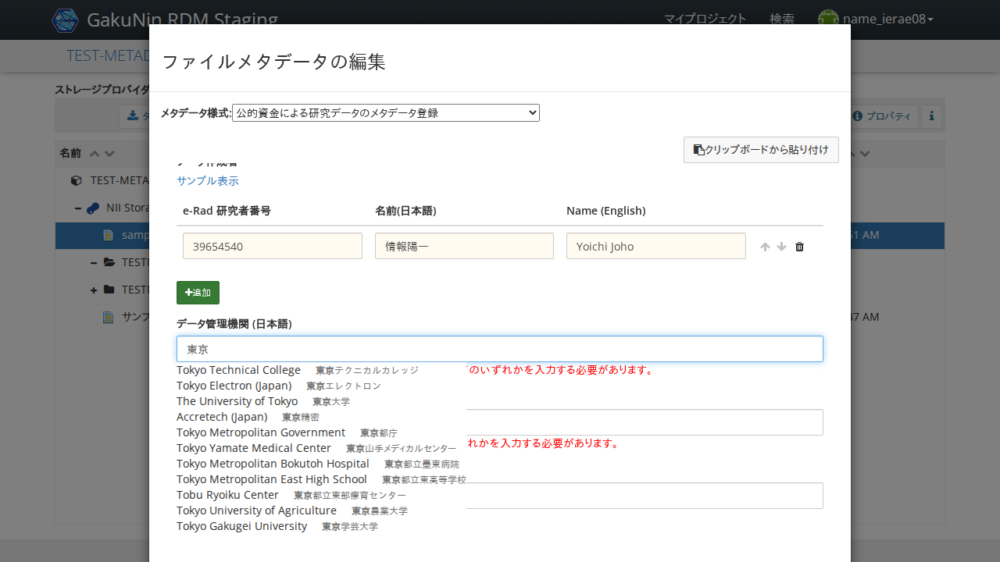

In [107]:
async def _step(page):
    form = FileMetadataForm(page)
    locator = form.get_locator('データ管理機関 (日本語)')
    await locator.focus()
    await page.keyboard.type('東京')
    time.sleep(1)

    await expect(page.locator('//*[text() = "The University of Tokyo"]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「東京大学」をクリックする

「データ管理機関コード」, 「Hosting institution (English)」が入力されること


Start epoch: 1774252335.5744455 seconds


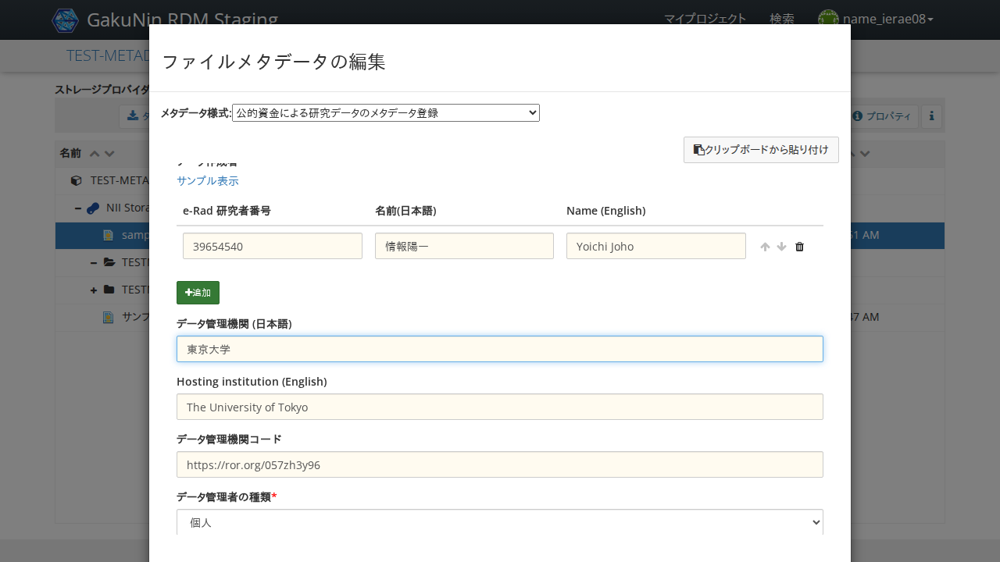

In [108]:
async def _step(page):
    await page.locator('//*[text() = "The University of Tokyo"]').click()

    form = FileMetadataForm(page)
    await expect(form.get_locator('データ管理機関 (日本語)')).to_have_value('東京大学', timeout=transition_timeout)
    await expect(form.get_locator('Hosting institution (English)')).to_have_value(re.compile('.+'), timeout=transition_timeout)
    await expect(form.get_locator('データ管理機関コード')).to_have_value(re.compile('.+'), timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者の所属機関の連絡先住所 (日本語)」に「テスト住所」を入力する

値が表示されること

Start epoch: 1774252337.3820555 seconds


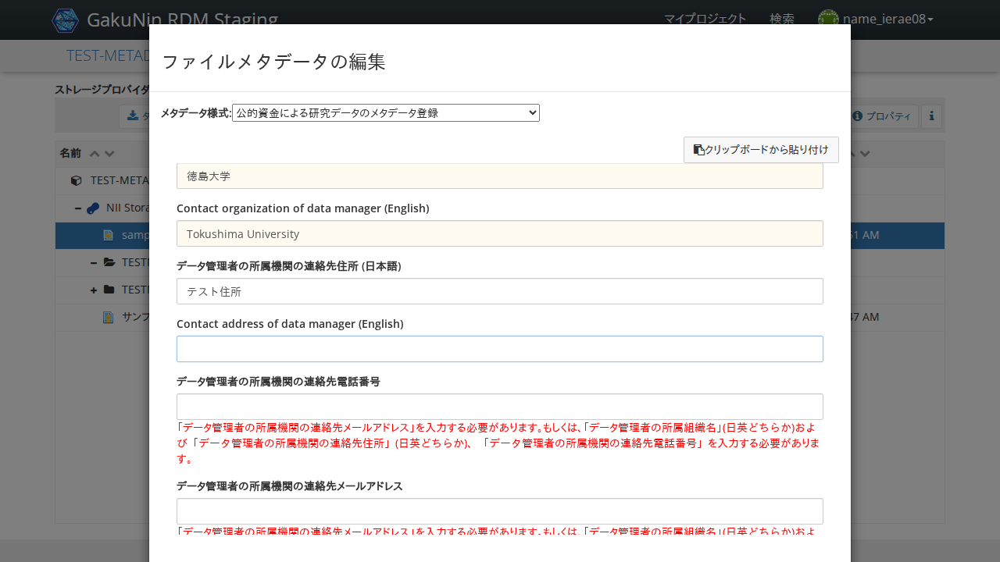

In [109]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'テスト住所'
    await form.fill('データ管理者の所属機関の連絡先住所 (日本語)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理者の所属機関の連絡先住所 (日本語)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「Contact address of data manager (English)」に「Test Address」を入力する

値が表示されること

Start epoch: 1774252339.2269504 seconds


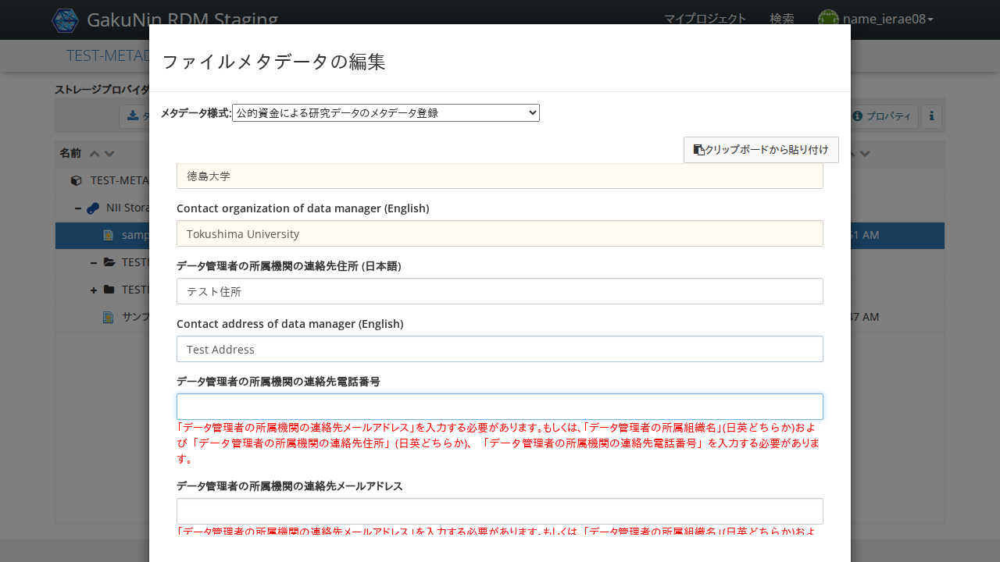

In [110]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'Test Address'
    await form.fill('Contact address of data manager (English)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Contact address of data manager (English)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者の所属機関の連絡先電話番号」に「000-0000-0000」を入力する

「「データ管理者の所属機関の連絡先メールアドレス」を入力する必要があります。もしくは、「データ管理者の所属組織名」(日英どちらか)および「データ管理者の所属機関の連絡先住所」(日英どちらか)、「データ管理者の所属機関の連絡先電話番号」を入力する必要があります。」が表示されなくなること

Start epoch: 1774252341.0594337 seconds


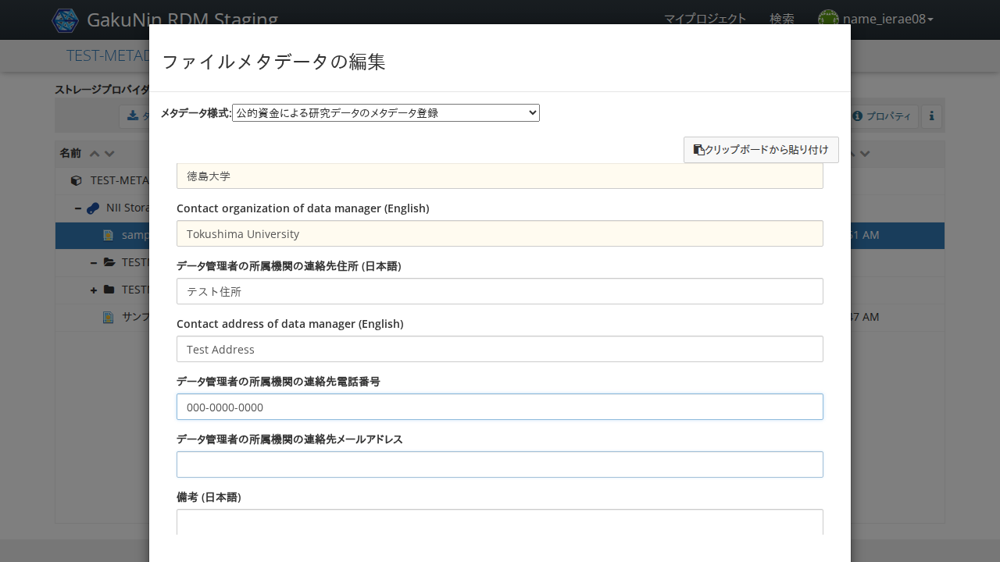

In [111]:
async def _step(page):
    form = FileMetadataForm(page)
    value = '000-0000-0000'
    await form.fill('データ管理者の所属機関の連絡先電話番号', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理者の所属機関の連絡先電話番号')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「データ管理者の所属機関の連絡先メールアドレス」に「test@example.com」を入力する

入力した値が表示されること

Start epoch: 1774252342.8544333 seconds


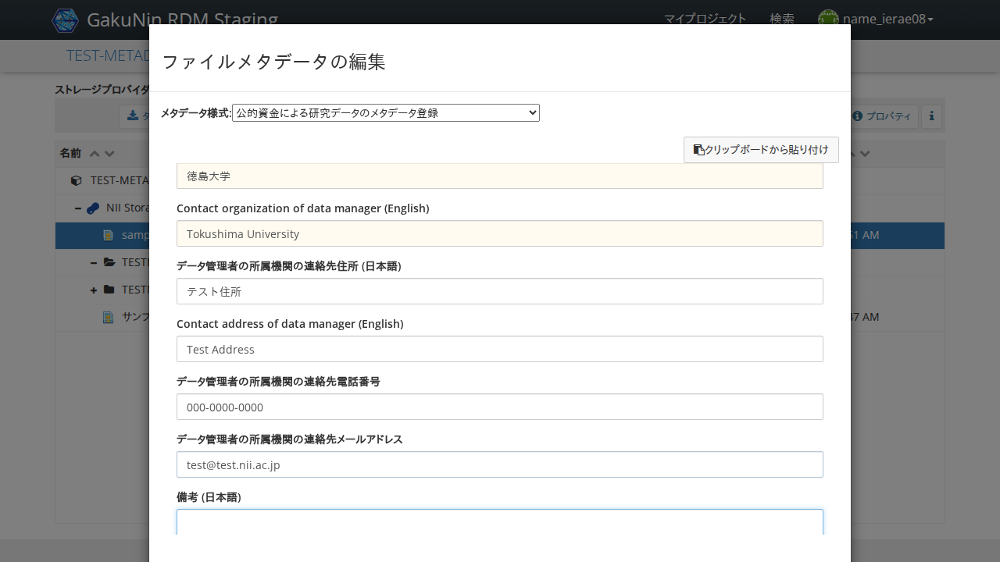

In [112]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'test@test.nii.ac.jp'
    await form.fill('データ管理者の所属機関の連絡先メールアドレス', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('データ管理者の所属機関の連絡先メールアドレス')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「備考 (日本語)」に「日本語による備考です。」を入力する

値が表示されること

Start epoch: 1774252344.6649158 seconds


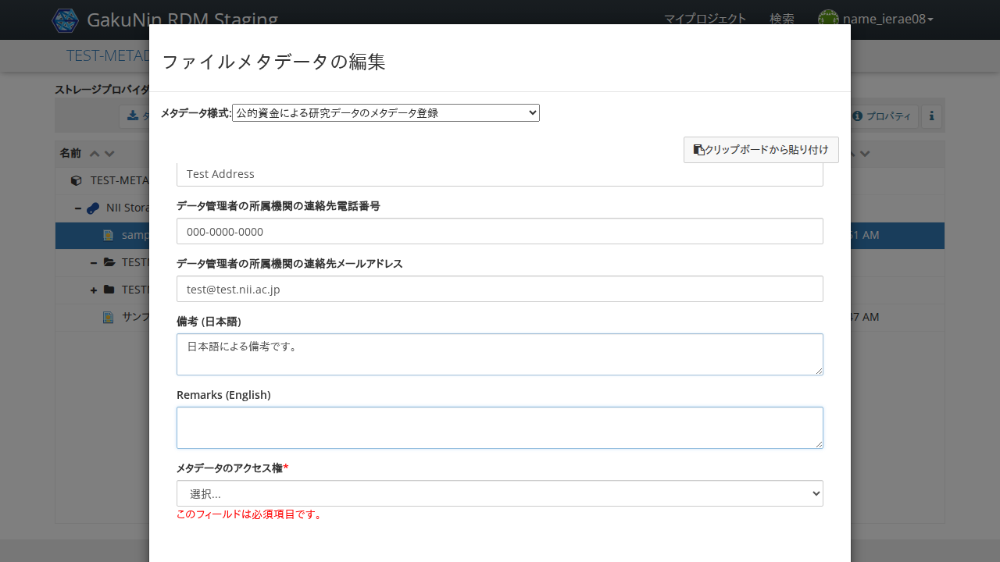

In [113]:
async def _step(page):
    form = FileMetadataForm(page)
    value = '日本語による備考です。'
    await form.fill('備考 (日本語)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('備考 (日本語)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

##  「Remarks (English)」に「Remarks in English.」を入力する

値が表示されること

Start epoch: 1774252346.4585965 seconds


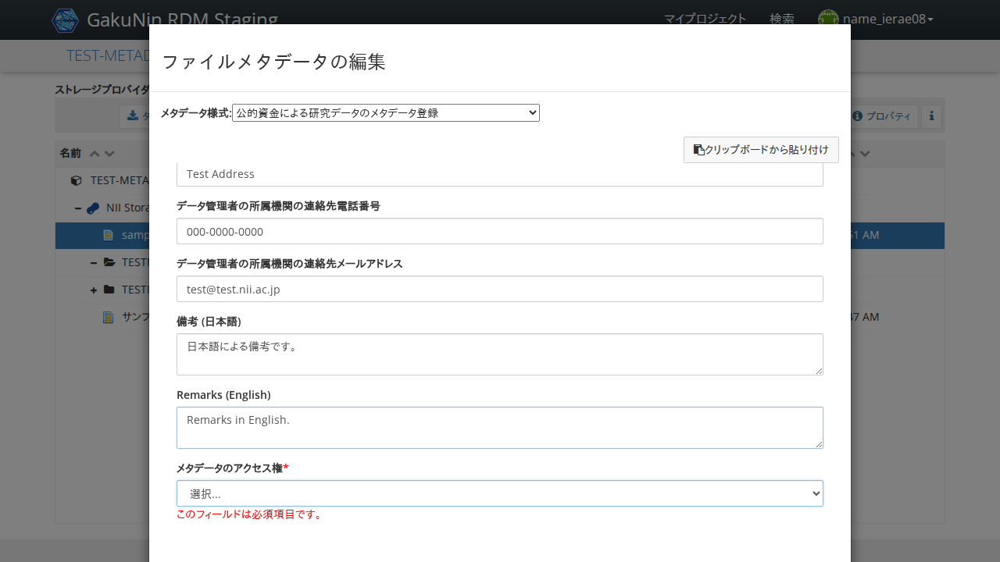

In [114]:
async def _step(page):
    form = FileMetadataForm(page)
    value = 'Remarks in English.'
    await form.fill('Remarks (English)', value)
    await page.keyboard.press('Tab')

    await expect(form.get_locator('Remarks (English)')).to_have_value(value, timeout=transition_timeout)

await run_pw(_step)

## 「保存」をクリックする

ダイアログが非表示になること

Start epoch: 1774252350.052872 seconds


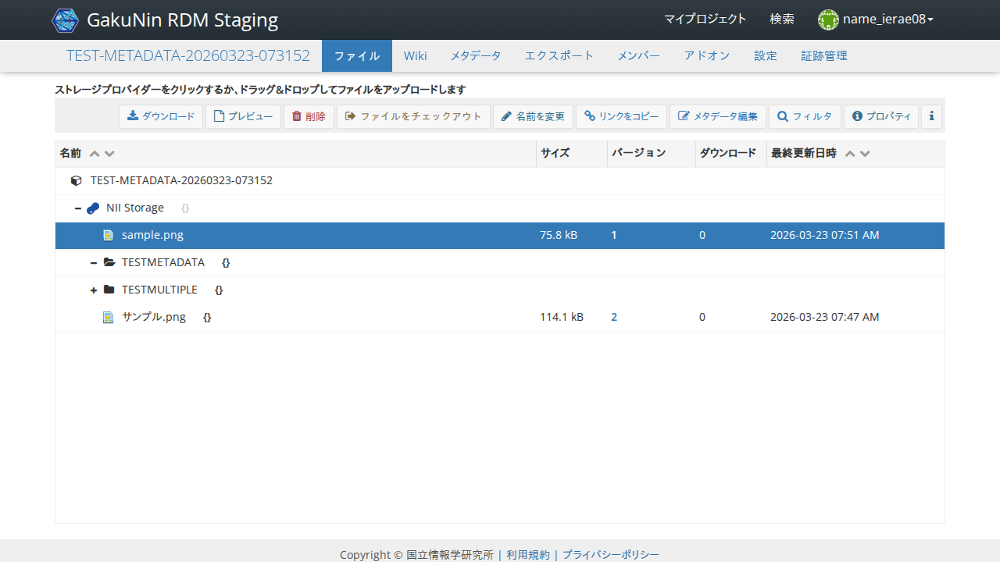

In [116]:
async def _step(page):
    await page.locator('//a[text() = "保存"]').click()
    form = FileMetadataForm(page)
    await expect(form.get_locator('Remarks (English)')).not_to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「sample.png」をクリックする

「メタデータ登録」ボタンが表示されること

Start epoch: 1774252352.6349525 seconds


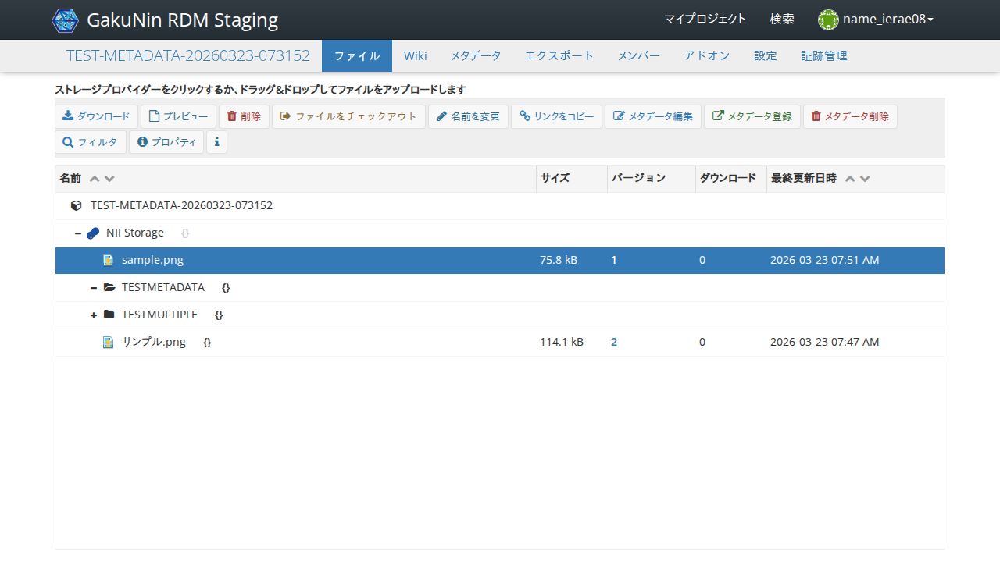

In [117]:
async def _step(page):
    await grdm.get_select_file_extension_locator(page, 'sample.png').click()
    await expect(page.locator('//*[text() = "メタデータ登録"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

##  「メタデータ登録」をクリックする

「ファイルメタデータ登録先の選択」ダイアログが表示され、「サンプルメタデータプロジェクト」とチェックボックスが表示されること

Start epoch: 1774252354.4314384 seconds


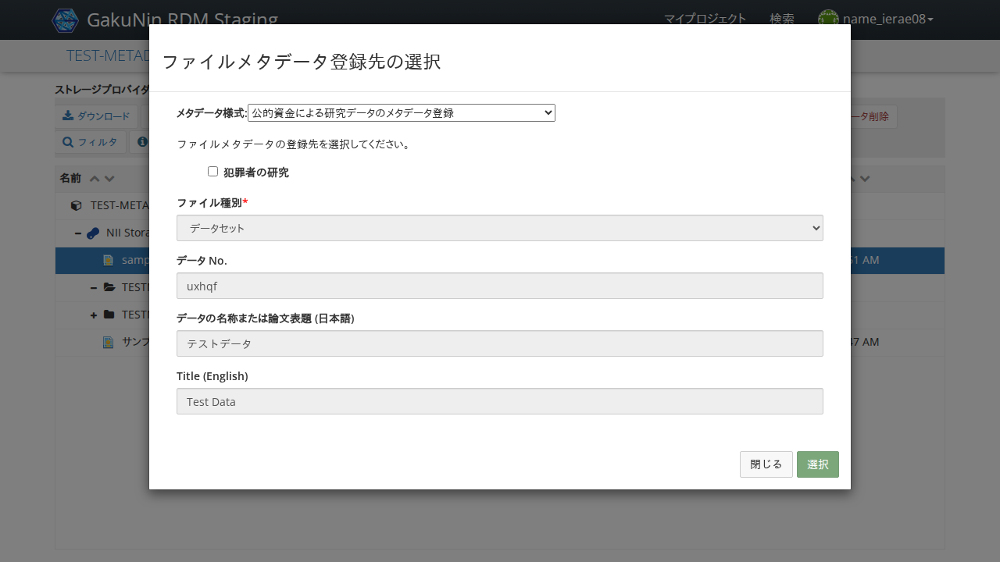

In [118]:
async def _step(page):
    await page.locator('//*[text() = "メタデータ登録"]').click()
    await expect(page.locator('//input[starts-with(@id, "draft-")]')).to_have_count(1, timeout=transition_timeout)

await run_pw(_step)

##  「犯罪者の研究」をクリックする

チェックボックスがチェック状態になること

Start epoch: 1774252356.6303077 seconds


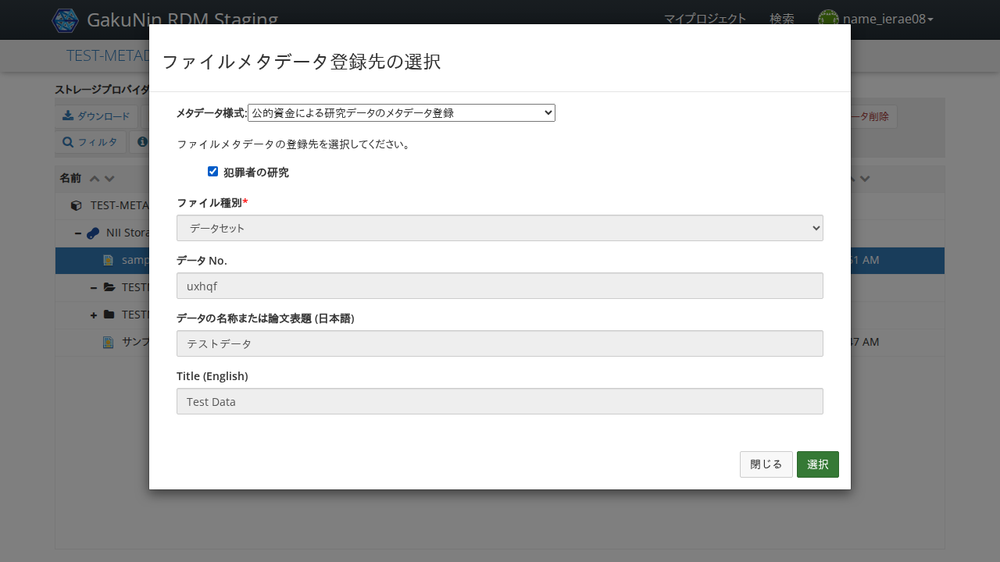

In [119]:
async def _step(page):
    checkbox = page.locator('//input[starts-with(@id, "draft-")]')
    await checkbox.click()
    await expect(checkbox).to_be_checked(timeout=transition_timeout)

await run_pw(_step)

##  「選択」をクリックする

「サンプルメタデータプロジェクト」に「開く」リンクが現れること

Start epoch: 1774252358.4047878 seconds


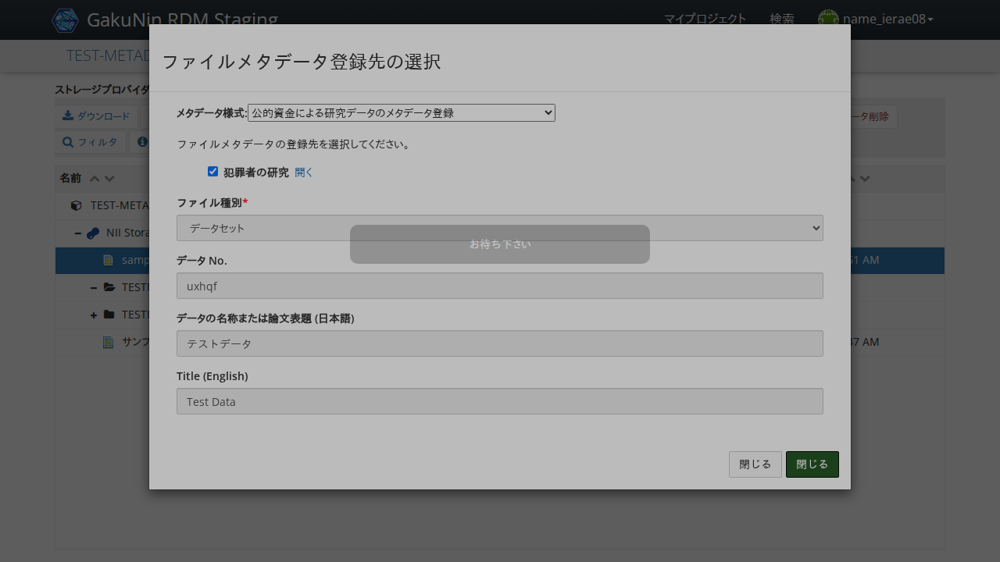

In [120]:
async def _step(page):
    await page.locator('//*[text() = "選択"]').click()
    await expect(page.locator('//*[text() = "開く"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「開く」をクリックする

ワークフローメタデータ編集画面が表示され、登録データ一覧に「テストデータ」が表示されること

Start epoch: 1774252360.563502 seconds


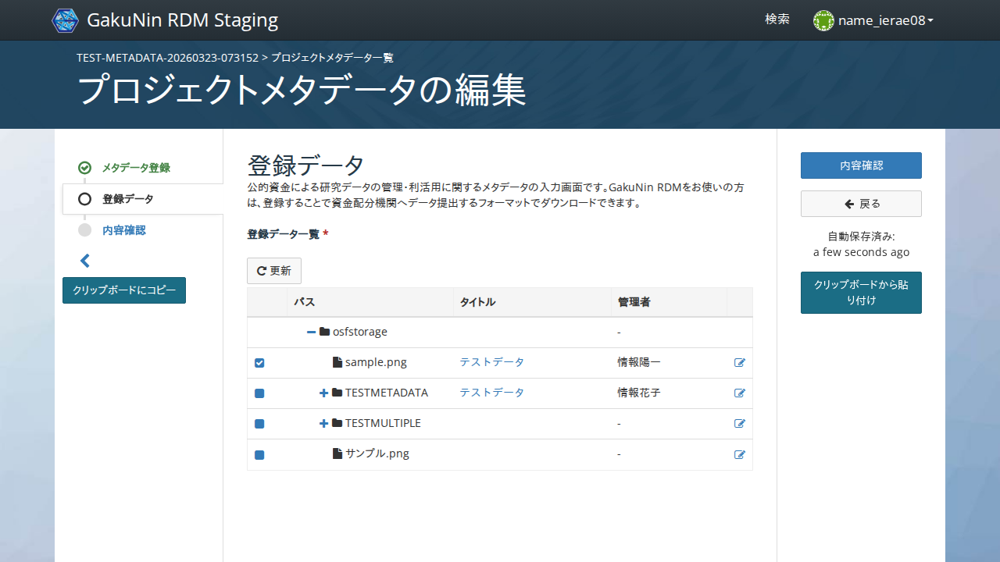

In [121]:
async def _step(page):
    await page.locator('//*[text() = "開く"]').click()
    await expect(page.locator('//*[@data-test-goto-review]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

## 「内容確認」をクリックする

左側ペイン「登録データ」が緑色かつチェックマークが表示されること

Start epoch: 1774252364.770237 seconds


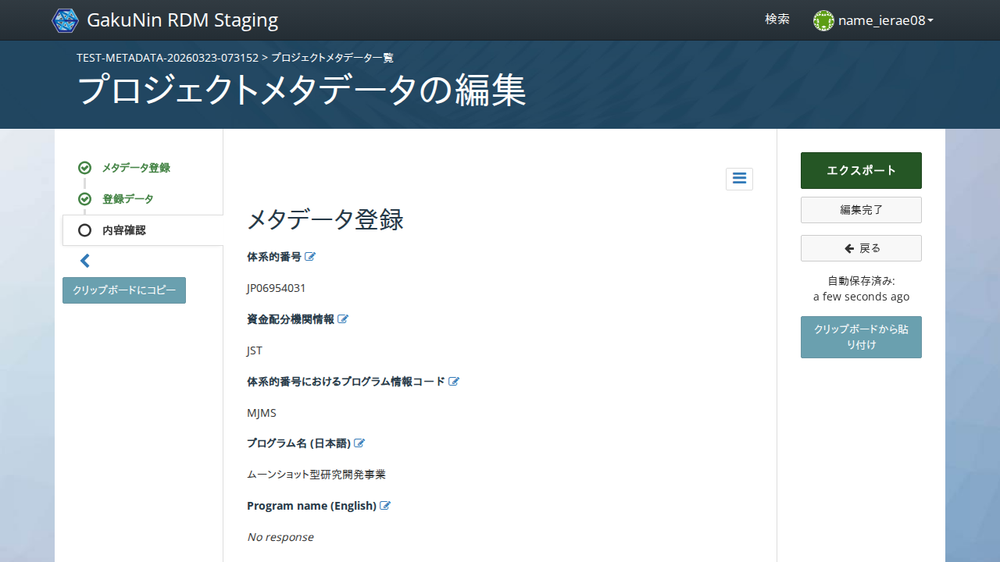

In [122]:
async def _step(page):
    await page.locator('//*[@data-test-goto-review]').click()
    
    await expect(page.locator('//span[@data-test-label and text() = "登録データ"]/../preceding-sibling::i')).to_have_class(re.compile(r'.*fa-check-circle-o.*'), timeout=transition_timeout)

await run_pw(_step)

## 「エクスポート」をクリックする

言語選択画面が表示されること

Start epoch: 1774252366.7746692 seconds


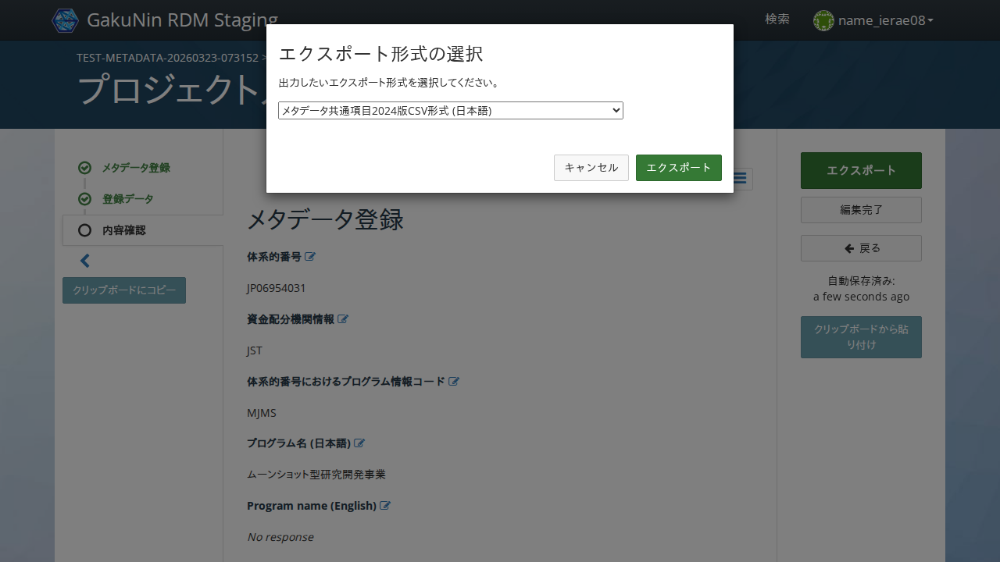

In [123]:
async def _step(page):
    await page.locator('//button[@data-test-registration-card-export]').click()
    
    await expect(page.locator('//select[@id = "registration-report-format-selection"]')).to_be_enabled(timeout=30000)
    time.sleep(1)

await run_pw(_step)

## 「Common Metadata Elements 2024 edition CSV format (English)」を選択し「エクスポート」をクリックする

CSVファイルがダウンロードされ、かつ、このCSVはUTF-16 BOM付きファイルで2行のファイルとなっていること。
Research fieldが「Life Science」となっていること

Start epoch: 1774252369.631864 seconds


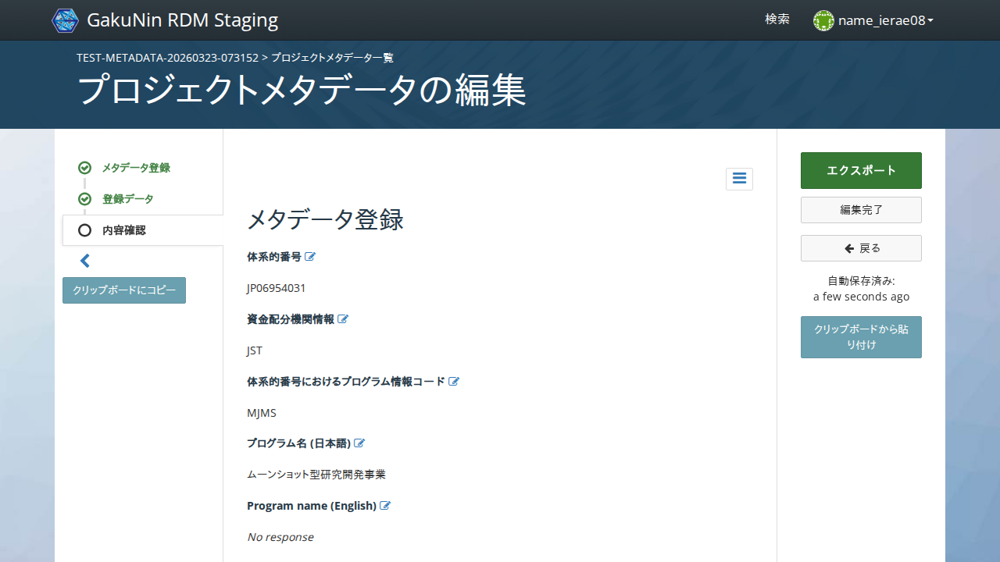

In [124]:
async def _step(page):
    await page.locator('//select[@id = "registration-report-format-selection"]').select_option('Common Metadata Elements 2024 edition CSV format (English)')
    download_future = page.wait_for_event('download')
    await page.locator('//button[@data-test-registration-report-submit]').click()
    download = await download_future
    await download.save_as(os.path.join(work_dir, 'report.csv'))
    assert os.path.exists(os.path.join(work_dir, 'report.csv'))

await run_pw(_step)

In [125]:
import pandas as pd
df = pd.read_csv(os.path.join(work_dir, 'report.csv'), encoding='utf-16')
df

In [ ]:
import re
import numpy as np

assert_values = {
    'Funder': 'Japan Science and Technology Agency',
    'Funding stream code in Japan Grant Number': 'MJMS',
    'Program name': np.nan,
    'Japan Grant Number': 'JP06954031',
    'Project name': 'Sample Metadata Project',
    'Title': 'Test Data',
    'Date (Issued / Updated)': '2022-05-25',
    'Description': 'Metadata created by automated testing.',
    'Research field': 'Life Science',
    'Data type': 'genomic data',
    'Data utilization and provision policy(Free/Consideration)': 'free',
    'Data utilization and provision policy(License)': 'CCBY',
    'Data utilization and provision policy(citation information)': 'The policy for use is described here.',
    'Access rights': 'embargoed access',
    'Publication date (for embargoed access)': '2022-05-25',
    'Repository information': 'Test Repository',
    'Creator Name': 'Yoichi Joho',
    'Creator name identifier (e-Rad)': 39654540,
    'Hosting institution': 'The University of Tokyo',
    'Hosting institution Identifier': 'https://ror.org/057zh3y96',
    'Data manager': 'Yoichi Joho',
    'Data manager identifier (e-Rad)': 39654540,
    'Contact organization of data manager': 'Test University',
    'Contact address of data manager': 'Test Address',
    'Contact phone number of data manager': '000-0000-0000',
    'Contact mail address of data manager': 'test@test.nii.ac.jp',
    'Remarks': 'Remarks in English.'
}
for column in ['Funder',
 'Funding stream code in Japan Grant Number',
 'Program name',
 'Japan Grant Number',
 'Project name',
 'Title',
 'Date (Issued / Updated)',
 'Description',
 'Research field',
 'Data type',
 'Data utilization and provision policy(Free/Consideration)',
 'Data utilization and provision policy(License)',
 'Data utilization and provision policy(citation information)',
 'Access rights',
 'Publication date (for embargoed access)',
 'Repository information',
 'Creator Name',
 'Creator name identifier (e-Rad)',
 'Hosting institution',
 'Hosting institution Identifier',
 'Data manager',
 'Data manager identifier (e-Rad)',
 'Contact organization of data manager',
 'Contact address of data manager',
 'Contact phone number of data manager',
 'Contact mail address of data manager',
 'Remarks']:
    assert column in assert_values, (column)
    if isinstance(assert_values[column], float) and np.isnan(assert_values[column]):
        assert np.isnan(df[column].values[0]), (column, assert_values[column], df[column].values[0])
        continue
    if hasattr(assert_values[column], 'match'):
        assert assert_values[column].match(df[column].values[0]), (column, assert_values[column], df[column].values[0])
        continue
    assert df[column].values[0] == assert_values[column], (column, assert_values[column], df[column].values[0])

In [127]:
!rm {work_dir}/report.csv

## 「編集完了」をクリックする

メタデータ一覧画面が表示されること

Start epoch: 1774252374.365313 seconds


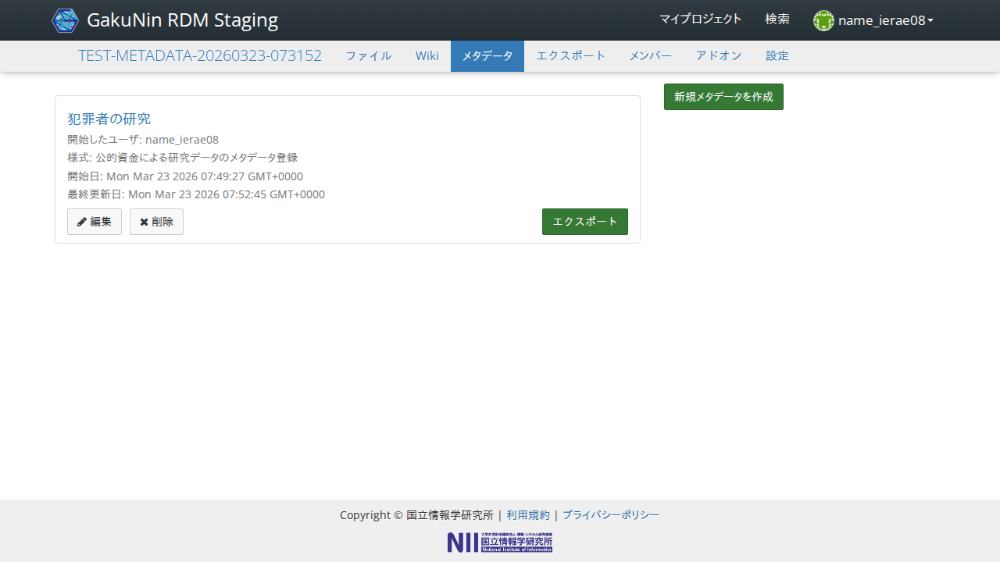

In [128]:
async def _step(page):
    await page.locator('//*[@data-analytics-name="Edit Complete"]').click()
    await expect(page.locator('//button[@data-test-registration-card-export]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「エクスポート」をクリックする

言語選択画面が表示されること

Start epoch: 1774252378.4821732 seconds


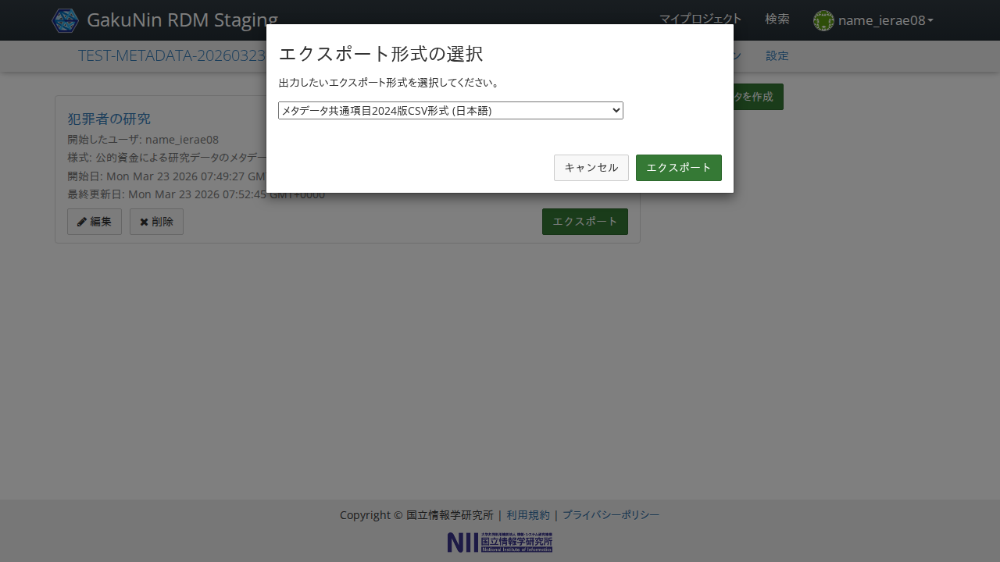

In [129]:
async def _step(page):
    await page.locator('//button[@data-test-registration-card-export]').click()
    
    await expect(page.locator('//select[@id = "registration-report-format-selection"]')).to_be_enabled(timeout=30000)
    time.sleep(1)

await run_pw(_step)

## 「Common Metadata Elements 2024 edition CSV format (English)」を選択し「エクスポート」をクリックする

CSVファイルがダウンロードされ、かつ、このCSVはUTF-16 BOM付きファイルで2行のファイルとなっていること。
Research fieldが「Life Science」となっていること

Start epoch: 1774252381.3256676 seconds


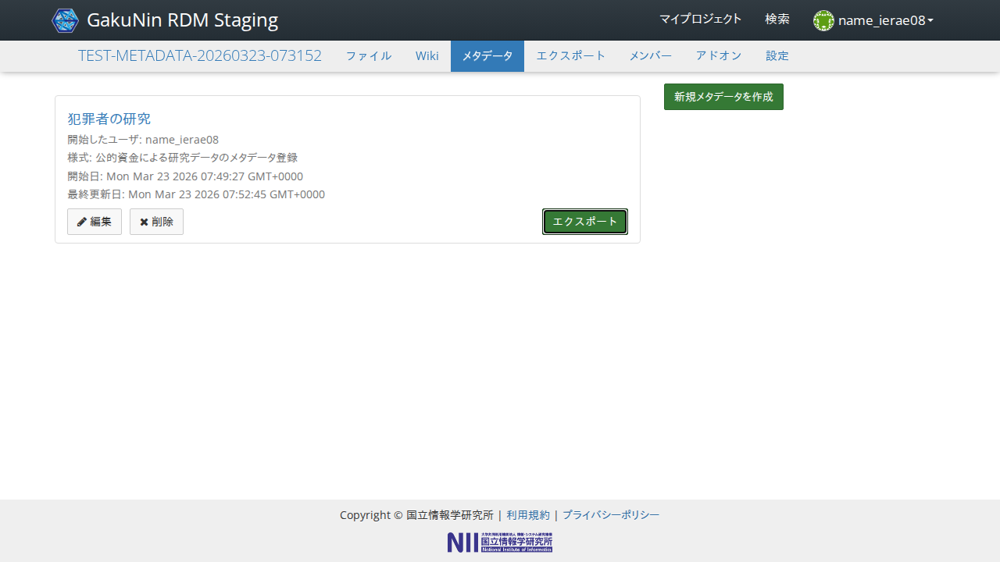

In [130]:
async def _step(page):
    await page.locator('//select[@id = "registration-report-format-selection"]').select_option('Common Metadata Elements 2024 edition CSV format (English)')
    download_future = page.wait_for_event('download')
    await page.locator('//button[@data-test-registration-report-submit]').click()
    download = await download_future
    await download.save_as(os.path.join(work_dir, 'report.csv'))
    assert os.path.exists(os.path.join(work_dir, 'report.csv'))

await run_pw(_step)

In [131]:
import pandas as pd
df = pd.read_csv(os.path.join(work_dir, 'report.csv'), encoding='utf-16')
df

In [ ]:
import re
import numpy as np

assert_values = {
    'Funder': 'Japan Science and Technology Agency',
    'Funding stream code in Japan Grant Number': 'MJMS',
    'Program name': np.nan,
    'Japan Grant Number': 'JP06954031',
    'Project name': 'Sample Metadata Project',
    'Title': 'Test Data',
    'Date (Issued / Updated)': '2022-05-25',
    'Description': 'Metadata created by automated testing.',
    'Research field': 'Life Science',
    'Data type': 'genomic data',
    'Data utilization and provision policy(Free/Consideration)': 'free',
    'Data utilization and provision policy(License)': 'CCBY',
    'Data utilization and provision policy(citation information)': 'The policy for use is described here.',
    'Access rights': 'embargoed access',
    'Publication date (for embargoed access)': '2022-05-25',
    'Repository information': 'Test Repository',
    'Creator Name': 'Yoichi Joho',
    'Creator name identifier (e-Rad)': 39654540,
    'Hosting institution': 'The University of Tokyo',
    'Hosting institution Identifier': 'https://ror.org/057zh3y96',
    'Data manager': 'Yoichi Joho',
    'Data manager identifier (e-Rad)': 39654540,
    'Contact organization of data manager': 'Test University',
    'Contact address of data manager': 'Test Address',
    'Contact phone number of data manager': '000-0000-0000',
    'Contact mail address of data manager': 'test@test.nii.ac.jp',
    'Remarks': 'Remarks in English.'
}
for column in ['Funder',
 'Funding stream code in Japan Grant Number',
 'Program name',
 'Japan Grant Number',
 'Project name',
 'Title',
 'Date (Issued / Updated)',
 'Description',
 'Research field',
 'Data type',
 'Data utilization and provision policy(Free/Consideration)',
 'Data utilization and provision policy(License)',
 'Data utilization and provision policy(citation information)',
 'Access rights',
 'Publication date (for embargoed access)',
 'Repository information',
 'Creator Name',
 'Creator name identifier (e-Rad)',
 'Hosting institution',
 'Hosting institution Identifier',
 'Data manager',
 'Data manager identifier (e-Rad)',
 'Contact organization of data manager',
 'Contact address of data manager',
 'Contact phone number of data manager',
 'Contact mail address of data manager',
 'Remarks']:
    assert column in assert_values, (column)
    if isinstance(assert_values[column], float) and np.isnan(assert_values[column]):
        assert np.isnan(df[column].values[0]), (column, assert_values[column], df[column].values[0])
        continue
    if hasattr(assert_values[column], 'match'):
        assert assert_values[column].match(df[column].values[0]), (column, assert_values[column], df[column].values[0])
        continue
    assert df[column].values[0] == assert_values[column], (column, assert_values[column], df[column].values[0])

後始末

## ダッシュボードのURLを開く

GRDMダッシュボードが表示されること

Start epoch: 1774252385.8494992 seconds


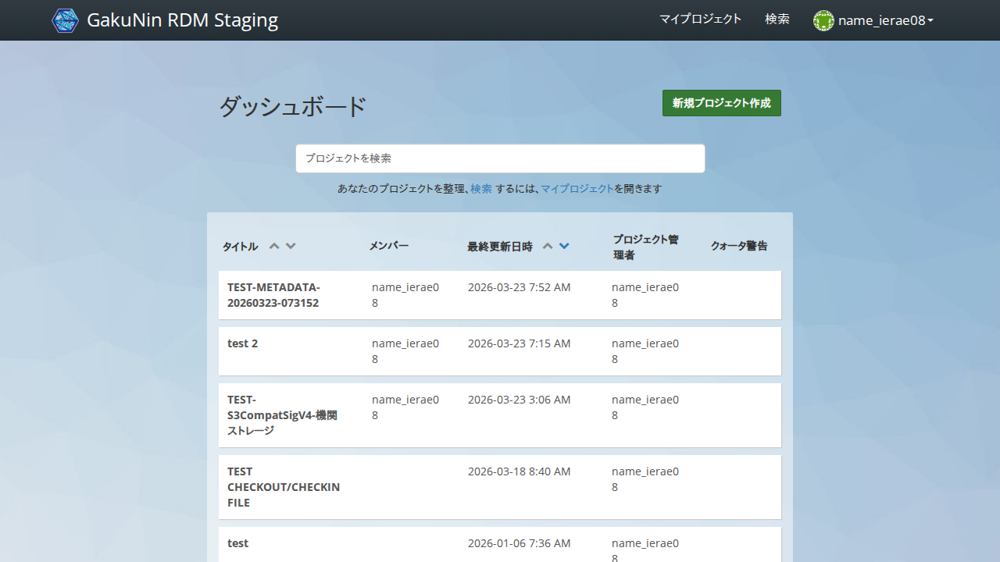

In [133]:
from urllib.parse import urljoin

async def _step(page):
    await page.goto(urljoin(rdm_url, 'dashboard'))
    await scripts.grdm.ensure_project_exists(page, rdm_project_name, transition_timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## ダッシュボードのプロジェクト一覧から作成したプロジェクトをクリックする

作成したプロジェクトのプロジェクトダッシュボードが表示されること

Start epoch: 1774252390.4362988 seconds


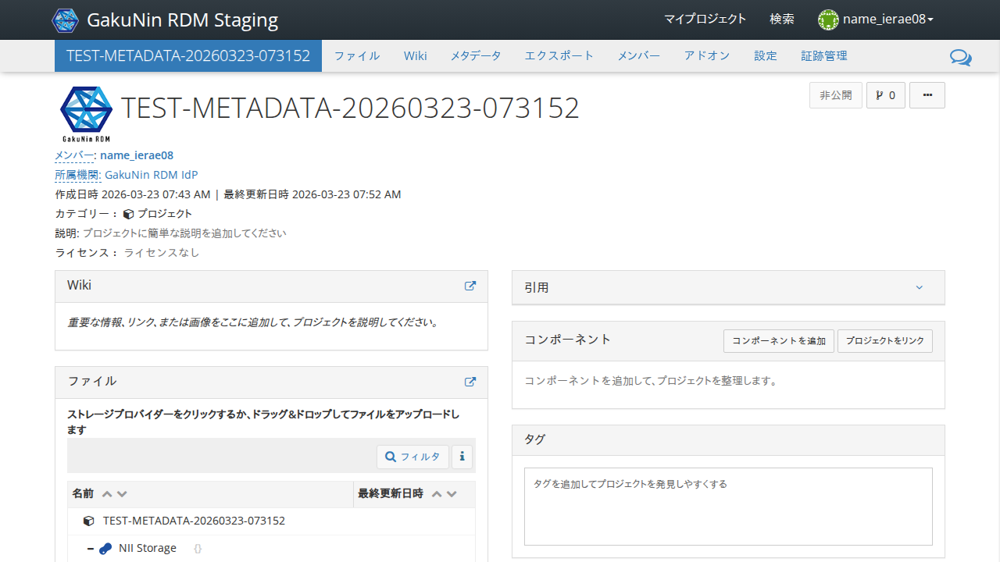

In [134]:
async def _step(page):
    await page.locator(f'//*[@data-test-dashboard-item-title and text() = "{rdm_project_name}"]').click()
    
    await expect(page.locator('//a[text() = "アドオン"]')).to_be_visible(timeout=transition_timeout)
    await expect(page.locator('//*[contains(@class, "title-text")]//*[text() = "NII Storage"]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「サンプル.png」のアイコンをクリックする

「メタデータ編集」ボタンが表示されること

Start epoch: 1774252394.704056 seconds


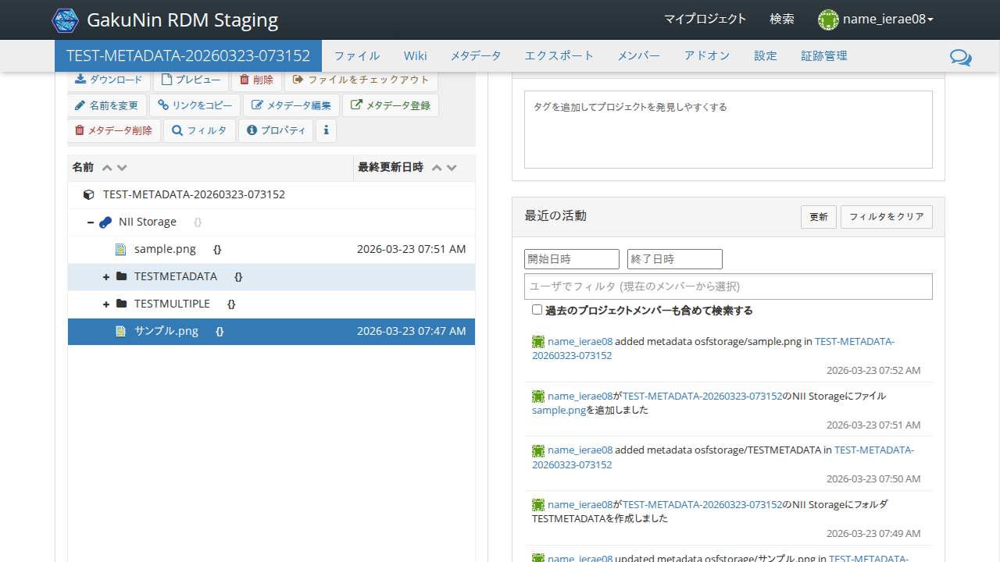

In [ ]:
filename = 'サンプル.png'
async def _step(page):
    global filename
    locator = grdm.get_select_file_extension_locator(page, filename)
    if not await locator.is_visible():
        filename = None
        return
    await locator.click()
    await expect(page.locator('//*[text() = "メタデータ編集"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「メタデータ削除」をクリックする

「ファイルメタデータの削除」のダイアログが表示されること

Start epoch: 1774252396.7463343 seconds


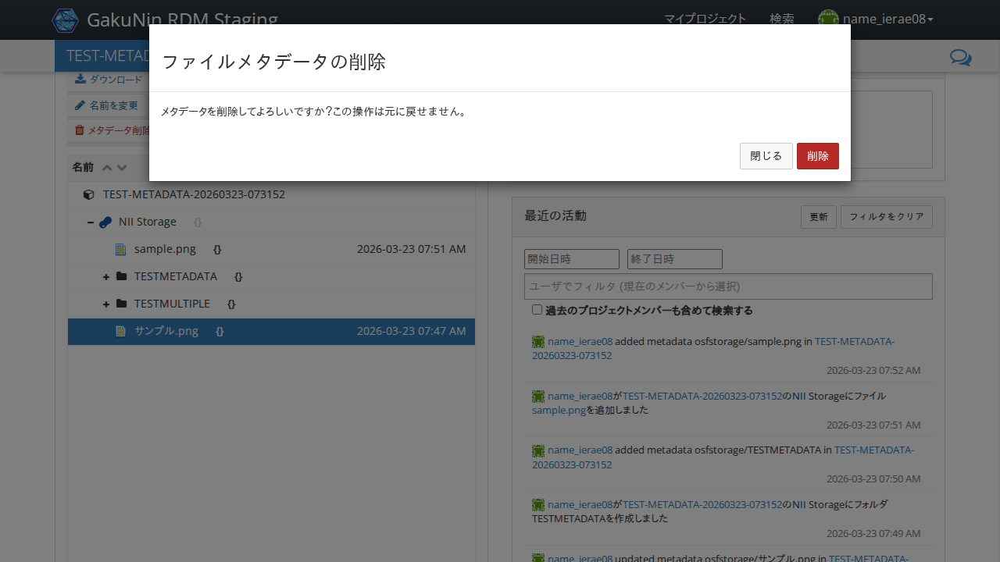

In [ ]:
async def _step(page):
    if not filename:
        return
    await page.locator('//*[text() = "メタデータ削除"]').click()
    await expect(page.locator('//*[text() = "メタデータを削除してよろしいですか？この操作は元に戻せません。"]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「削除」をクリックする

メタデータが削除されること

Start epoch: 1774252400.1845481 seconds


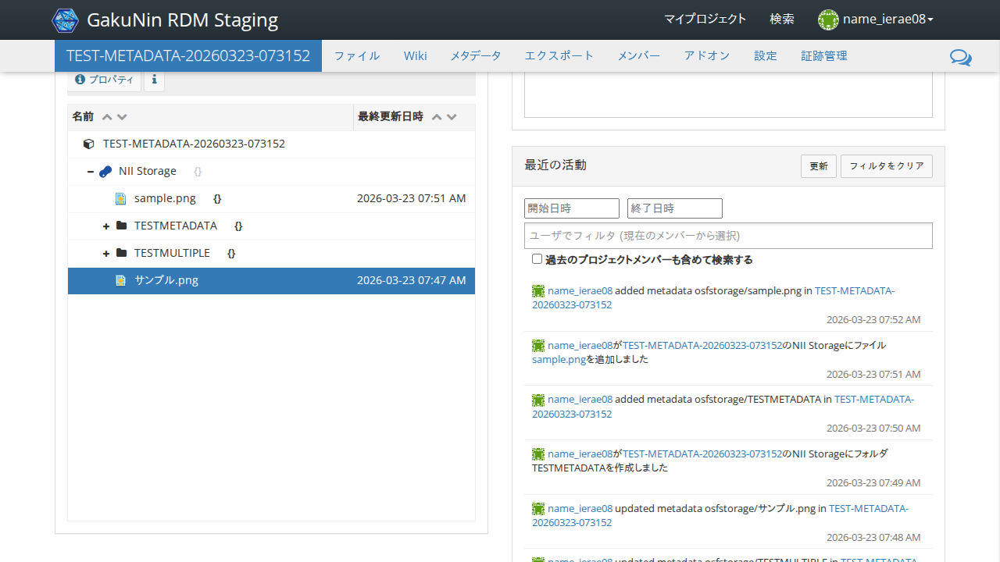

In [ ]:
async def _step(page):
    if not filename:
        return
    await page.locator('//*[contains(@class, "btn-danger") and text() = "削除"]').first.click()

    await expect(page.locator('//*[text() = "メタデータを削除してよろしいですか？この操作は元に戻せません。"]')).not_to_be_visible(timeout=transition_timeout)
    await grdm.get_select_file_extension_locator(page, filename).click()
    time.sleep(5)
    await grdm.get_select_file_extension_locator(page, filename).scroll_into_view_if_needed()

await run_pw(_step)

## 「TESTMULTIPLE」のアイコンをクリックする

「メタデータ編集」ボタンが表示されること

Start epoch: 1774252408.3578124 seconds


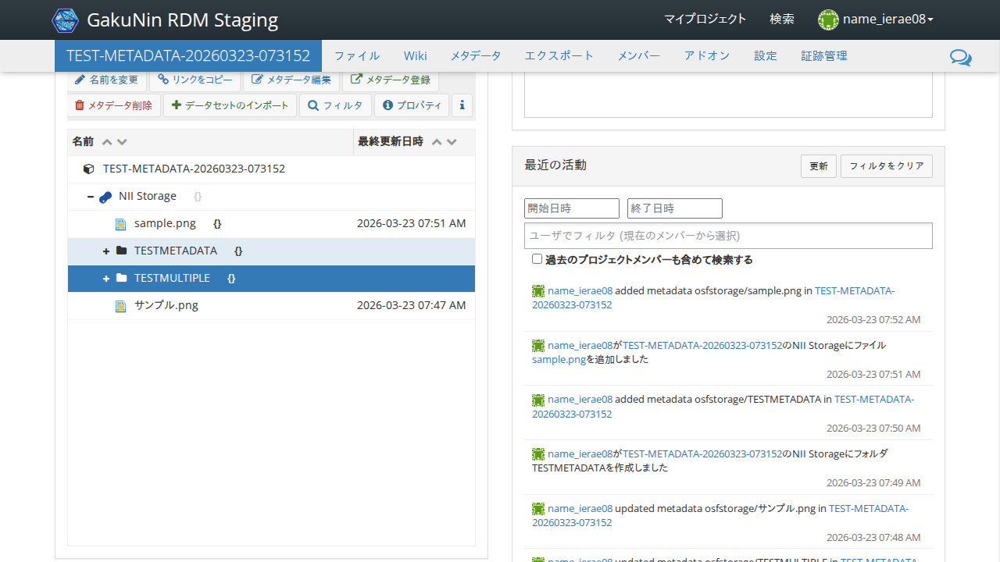

In [ ]:
foldername = 'TESTMULTIPLE'
async def _step(page):
    global foldername
    locator = grdm.get_select_folder_title_locator(page, foldername)
    if not await locator.is_visible():
        foldername = None
        return
    await locator.click()
    await expect(page.locator('//*[text() = "メタデータ編集"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「メタデータ削除」をクリックする

「ファイルメタデータの削除」のダイアログが表示されること

Start epoch: 1774252410.5015259 seconds


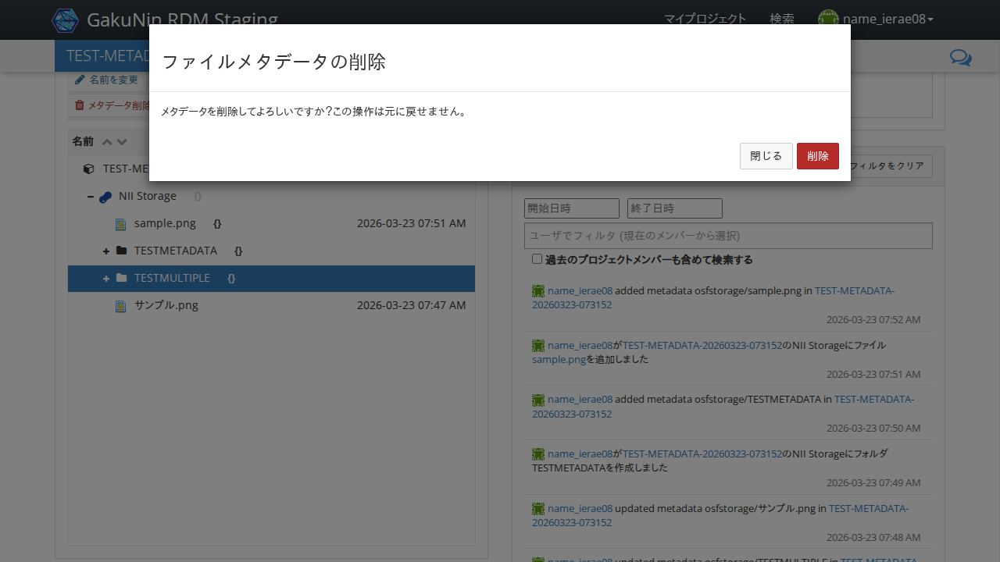

In [ ]:
async def _step(page):
    if not foldername:
        return
    await page.locator('//*[text() = "メタデータ削除"]').click()
    await expect(page.locator('//*[text() = "メタデータを削除してよろしいですか？この操作は元に戻せません。"]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「削除」をクリックする

メタデータが削除されること

Start epoch: 1774252414.2252283 seconds


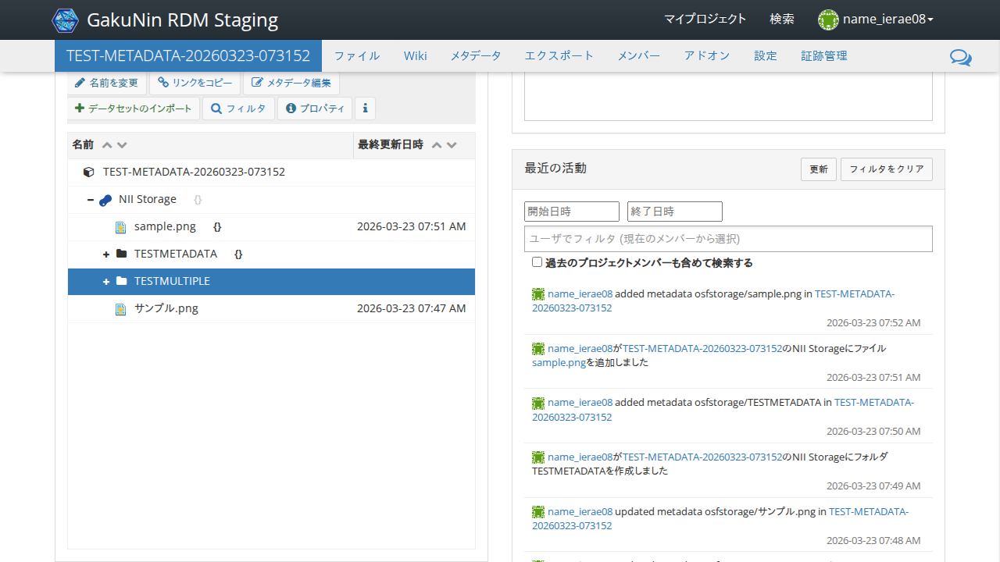

In [ ]:
async def _step(page):
    if not foldername:
        return
    await page.locator('//*[contains(@class, "btn-danger") and text() = "削除"]').first.click()

    await expect(page.locator('//*[text() = "メタデータを削除してよろしいですか？この操作は元に戻せません。"]')).not_to_be_visible(timeout=transition_timeout)
    await grdm.get_select_folder_title_locator(page, foldername).click()
    time.sleep(5)
    await grdm.get_select_folder_title_locator(page, foldername).scroll_into_view_if_needed()

await run_pw(_step)

## 「TESTMETADATA」のアイコンをクリックする

「メタデータ編集」ボタンが表示されること

Start epoch: 1774252422.213843 seconds


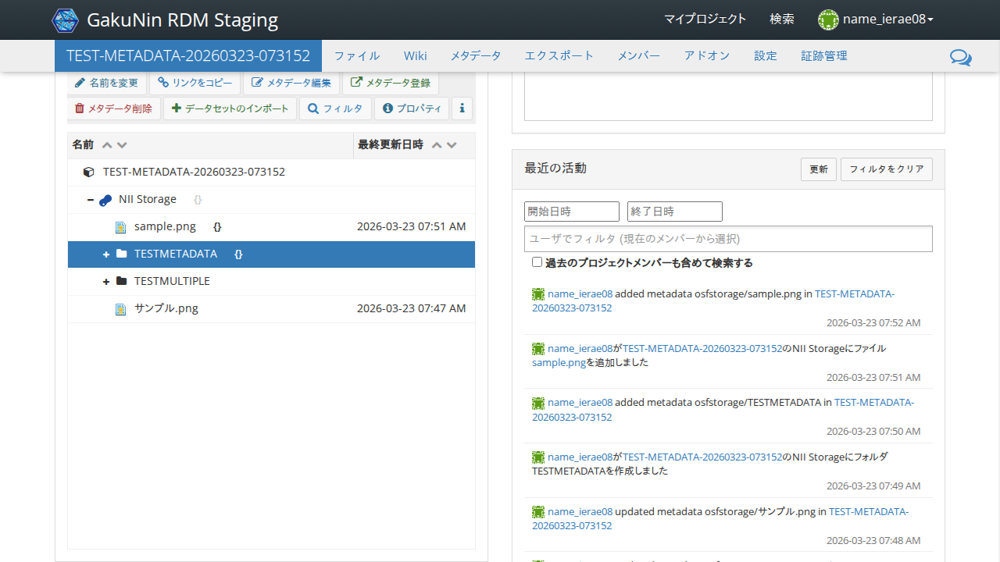

In [ ]:
foldername = 'TESTMETADATA'
async def _step(page):
    global foldername
    locator = grdm.get_select_folder_title_locator(page, foldername)
    if not await locator.is_visible():
        foldername = None
        return
    await locator.click()
    await expect(page.locator('//*[text() = "メタデータ編集"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「メタデータ削除」をクリックする

「ファイルメタデータの削除」のダイアログが表示されること

Start epoch: 1774252424.2628407 seconds


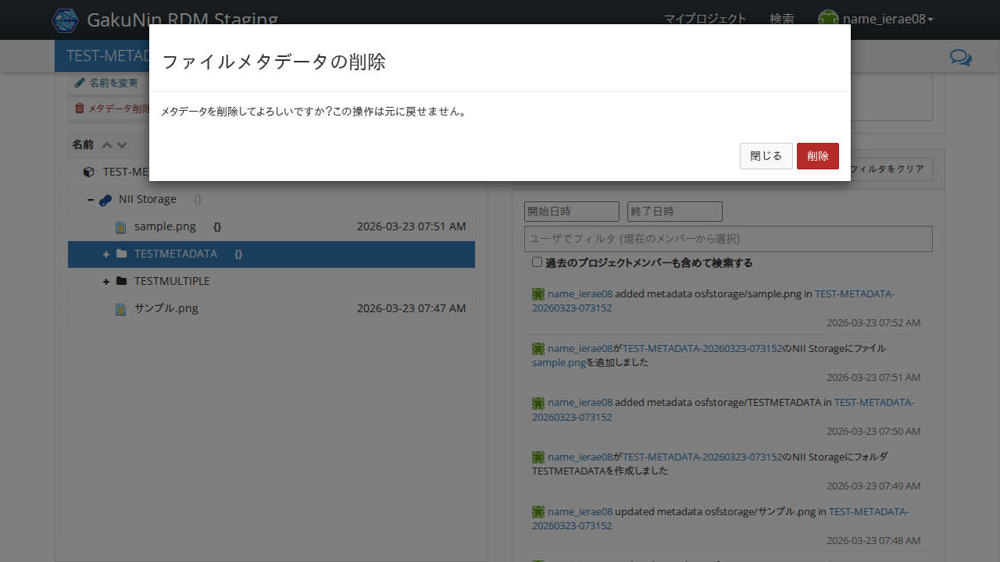

In [ ]:
async def _step(page):
    if not foldername:
        return
    await page.locator('//*[text() = "メタデータ削除"]').click()
    await expect(page.locator('//*[text() = "メタデータを削除してよろしいですか？この操作は元に戻せません。"]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「削除」をクリックする

メタデータが削除されること

Start epoch: 1774252427.6423411 seconds


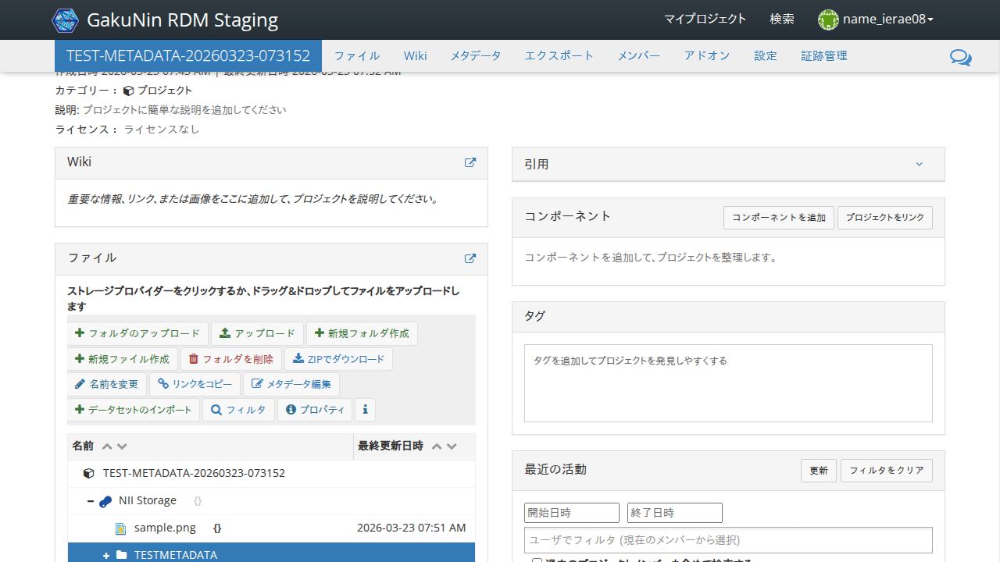

In [ ]:
async def _step(page):
    if not foldername:
        return
    await page.locator('//*[contains(@class, "btn-danger") and text() = "削除"]').first.click()

    await expect(page.locator('//*[text() = "メタデータを削除してよろしいですか？この操作は元に戻せません。"]')).not_to_be_visible(timeout=transition_timeout)
    await grdm.get_select_folder_title_locator(page, foldername).click()
    time.sleep(5)
    await grdm.get_select_folder_title_locator(page, foldername).scroll_into_view_if_needed()

await run_pw(_step)

## 「sample.png」のアイコンをクリックする

「メタデータ編集」ボタンが表示されること

Start epoch: 1774252436.5430155 seconds


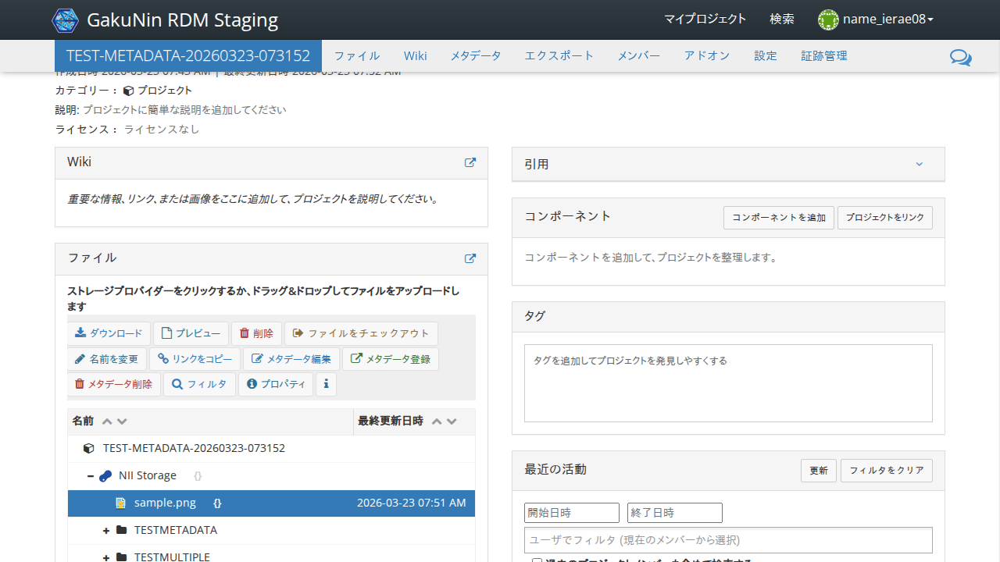

In [ ]:
filename = 'sample.png'
async def _step(page):
    global filename
    locator = grdm.get_select_file_extension_locator(page, filename)
    if not await locator.is_visible():
        filename = None
        return
    await locator.click()
    await expect(page.locator('//*[text() = "メタデータ編集"]')).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「メタデータ削除」をクリックする

「ファイルメタデータの削除」のダイアログが表示されること

Start epoch: 1774252438.5622706 seconds


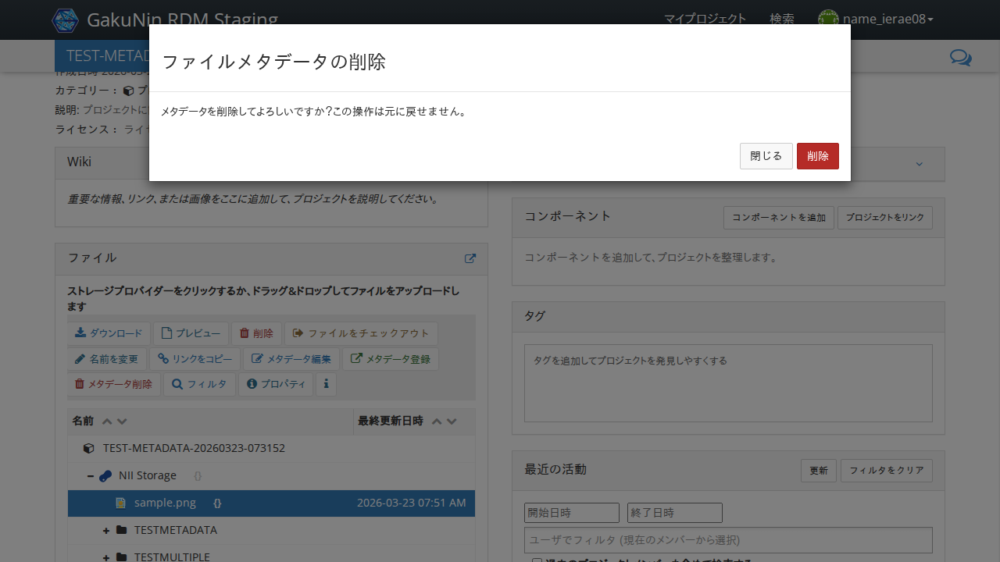

In [ ]:
async def _step(page):
    if not filename:
        return
    await page.locator('//*[text() = "メタデータ削除"]').click()
    await expect(page.locator('//*[text() = "メタデータを削除してよろしいですか？この操作は元に戻せません。"]')).to_be_visible(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「削除」をクリックする

メタデータが削除されること

Start epoch: 1774252442.002053 seconds


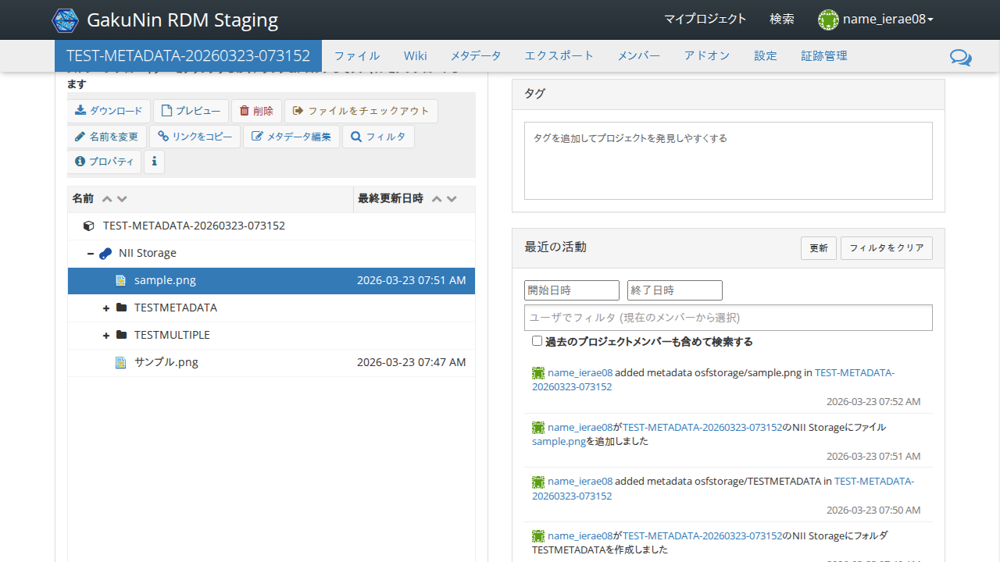

In [ ]:
async def _step(page):
    if not filename:
        return
    await page.locator('//*[contains(@class, "btn-danger") and text() = "削除"]').first.click()

    await expect(page.locator('//*[text() = "メタデータを削除してよろしいですか？この操作は元に戻せません。"]')).not_to_be_visible(timeout=transition_timeout)
    await grdm.get_select_file_extension_locator(page, filename).click()
    time.sleep(5)
    await grdm.get_select_file_extension_locator(page, filename).scroll_into_view_if_needed()

await run_pw(_step)

## 「サンプル.png」のアイコンをクリックする

「削除」ボタンが表示されること

Start epoch: 1774252451.02071 seconds


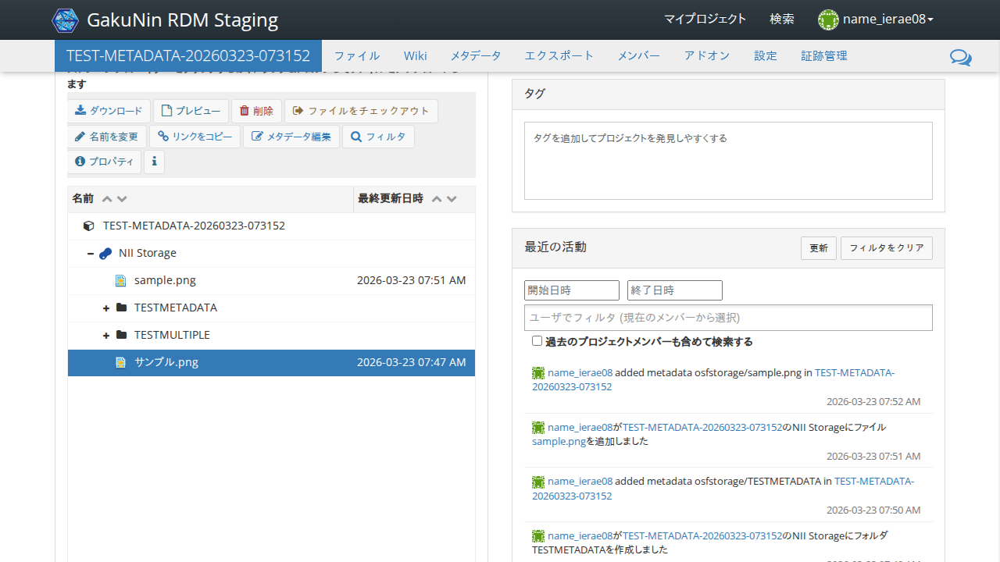

In [ ]:
filename = 'サンプル.png'
async def _step(page):
    global filename
    locator = grdm.get_select_file_extension_locator(page, filename)
    if not await locator.is_visible():
        filename = None
        return
    await locator.click()
    await expect(page.locator('//*[contains(@class, "btn-danger") and text() = "削除"]').first).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「削除」をクリックする

「"サンプル.png"を削除しますか？」のダイアログが表示されること

Start epoch: 1774252453.1059783 seconds


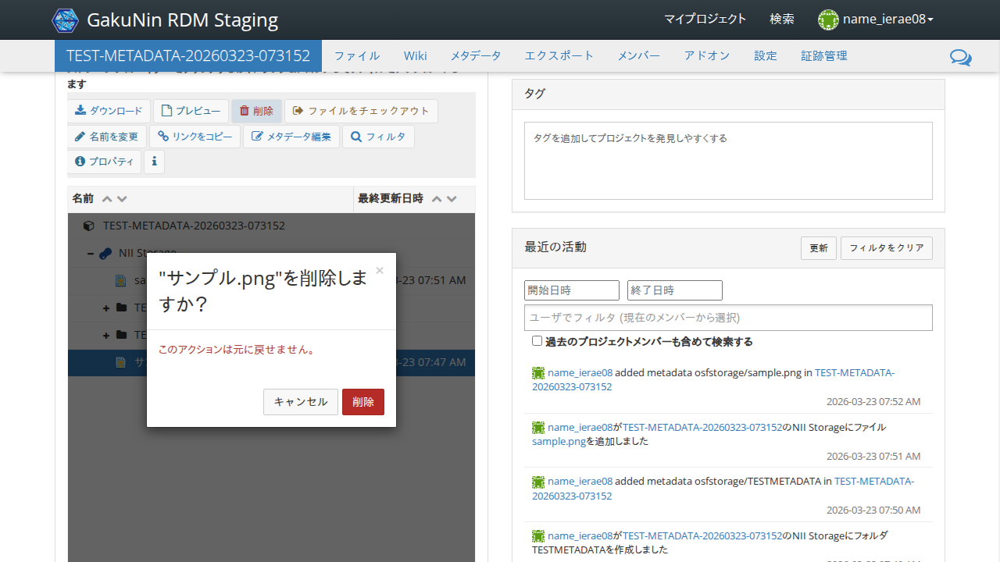

In [ ]:
async def _step(page):
    if not filename:
        return
    await page.locator('//i[contains(@class, "fa-trash")]/../*[text() = "削除"]').click()
    locator = page.locator('//*[@id = "tb-tbody"]//*[@class = "modal-content"]//*[contains(@class, "btn-danger")]')
    await locator.scroll_into_view_if_needed()
    await expect(locator).to_be_enabled(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「削除」をクリックする

サンプル.pngが削除されること

Start epoch: 1774252456.2597022 seconds


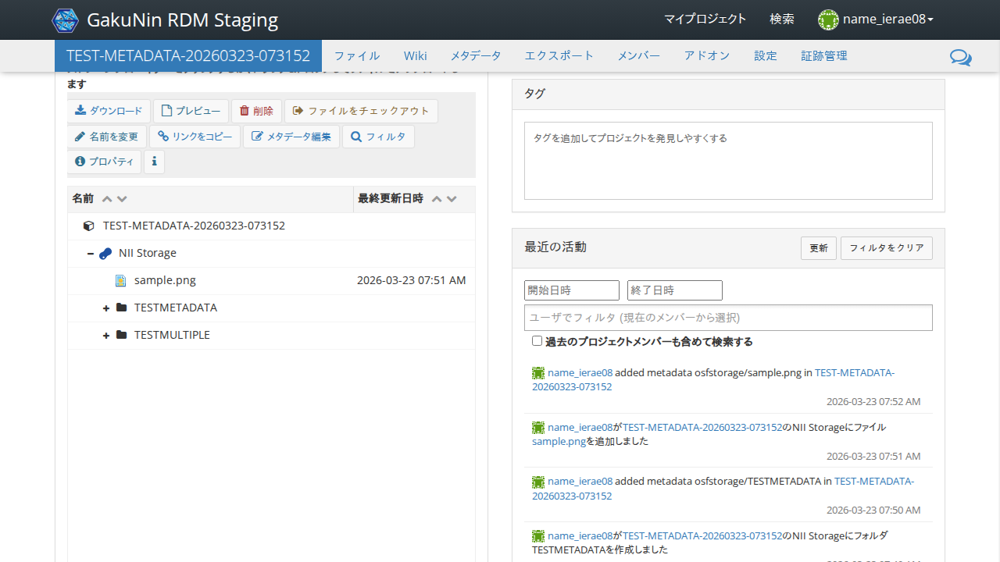

In [ ]:
async def _step(page):
    if not filename:
        return
    await page.locator('//*[@id = "tb-tbody"]//*[@class = "modal-content"]//*[contains(@class, "btn-danger")]').click()
    await expect(grdm.get_select_file_title_locator(page, filename)).to_have_count(0, timeout=transition_timeout)
    time.sleep(1)
    await page.locator('//*[contains(@class, "title-text")]//*[text() = "NII Storage"]').scroll_into_view_if_needed()

await run_pw(_step)

## 「TESTMULTIPLE」をクリックする	

「フォルダを削除」ボタンが表示されること

Start epoch: 1774252459.675856 seconds


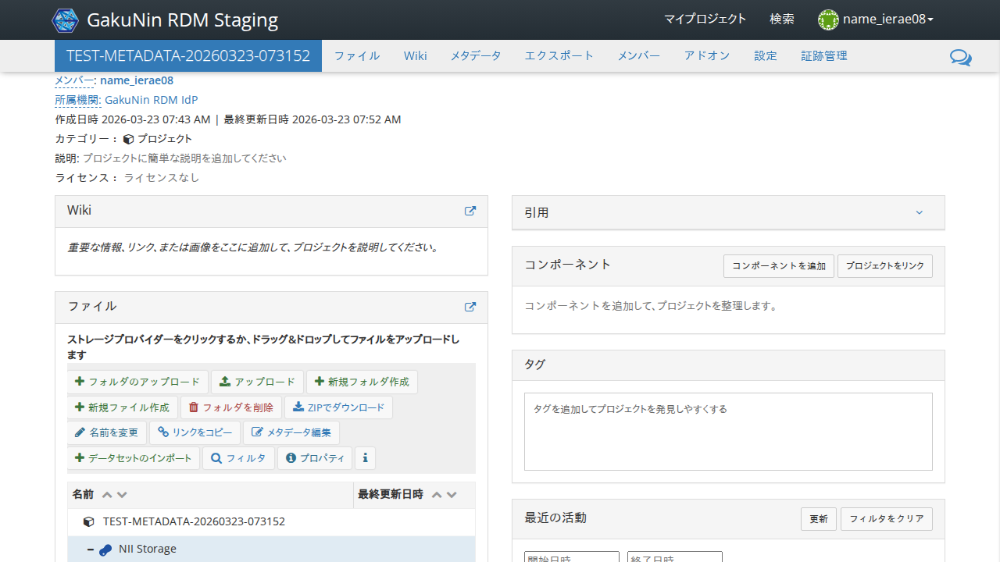

In [ ]:
foldername = 'TESTMULTIPLE'
async def _step(page):
    global foldername
    locator = grdm.get_select_folder_title_locator(page, foldername)
    if not await locator.is_visible():
        foldername = None
        return
    await locator.click()
    await expect(page.locator('//*[contains(@class, "btn-danger") and text() = "削除"]').first).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「フォルダを削除」をクリックする

「"TESTMULTIPLE"を削除しますか？」のダイアログが表示されること

Start epoch: 1774252461.787861 seconds


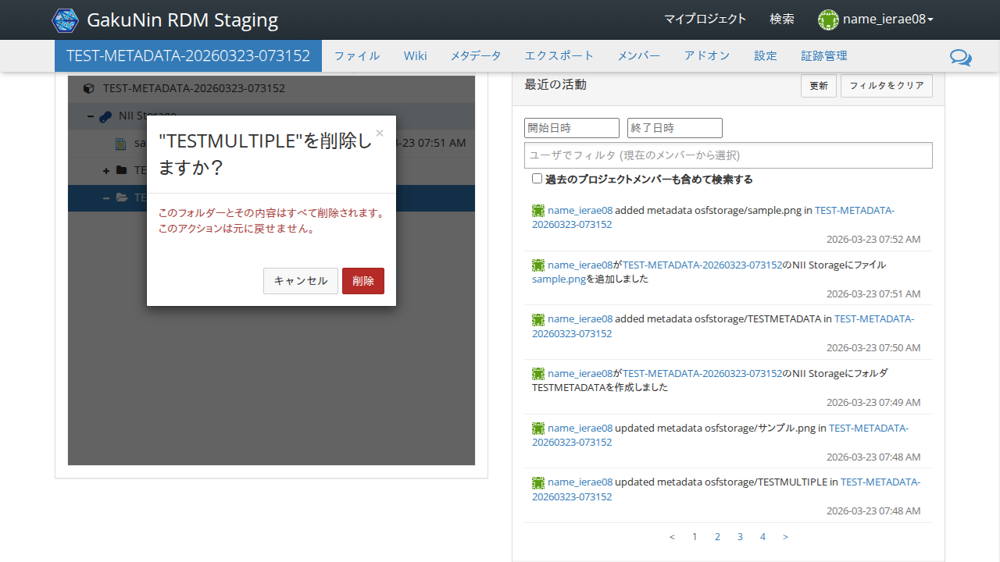

In [ ]:
async def _step(page):
    if not foldername:
        return
    await page.locator('//i[contains(@class, "fa-trash")]/../*[text() = "フォルダを削除"]').click()
    locator = page.locator('//*[@id = "tb-tbody"]//*[@class = "modal-content"]//*[contains(@class, "btn-danger")]')
    await locator.scroll_into_view_if_needed()
    await expect(locator).to_be_enabled(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「削除」をクリックする

TESTMULTIPLEが削除されること

Start epoch: 1774252466.1992784 seconds


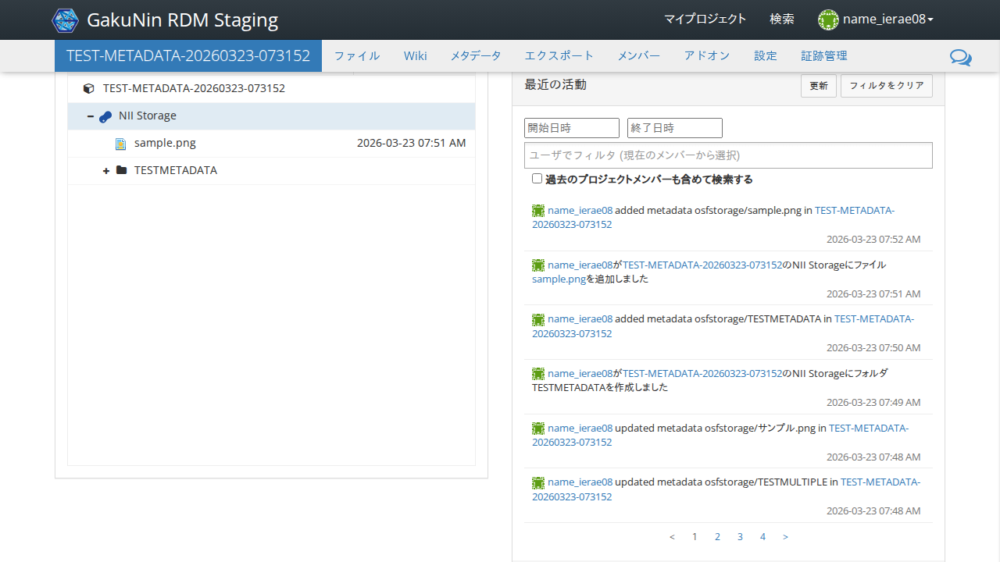

In [ ]:
async def _step(page):
    if not foldername:
        return
    await page.locator('//*[@id = "tb-tbody"]//*[@class = "modal-content"]//*[contains(@class, "btn-danger")]').click()
    await expect(grdm.get_select_folder_title_locator(page, foldername)).to_have_count(0, timeout=transition_timeout)
    time.sleep(1)
    await page.locator('//*[contains(@class, "title-text")]//*[text() = "NII Storage"]').scroll_into_view_if_needed()

await run_pw(_step)

## 「TESTMETADATA」をクリックする	

「フォルダを削除」ボタンが表示されること

Start epoch: 1774252469.7038434 seconds


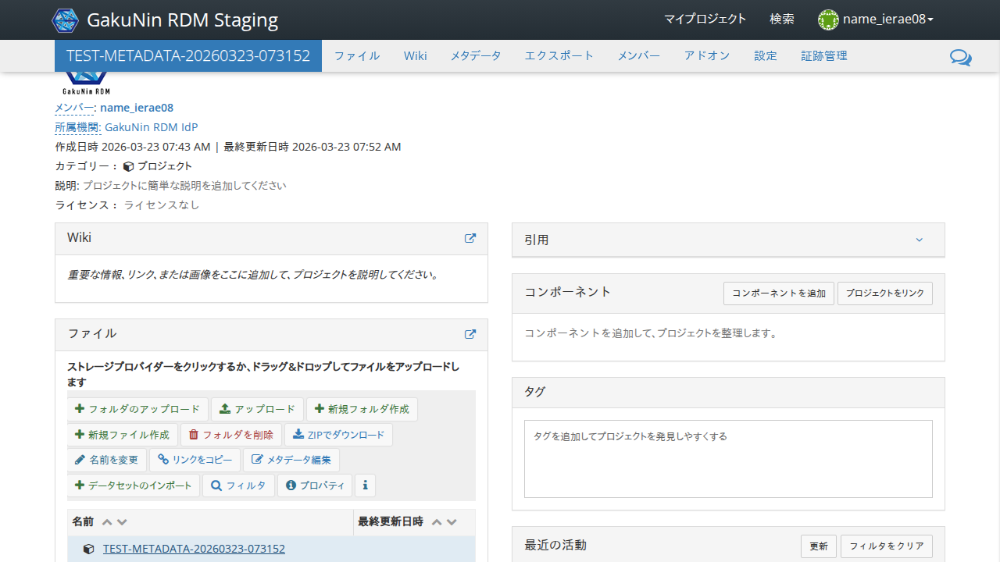

In [ ]:
foldername = 'TESTMETADATA'
async def _step(page):
    global foldername
    locator = grdm.get_select_folder_title_locator(page, foldername)
    if not await locator.is_visible():
        foldername = None
        return
    await locator.click()
    await expect(page.locator('//*[contains(@class, "btn-danger") and text() = "削除"]').first).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「フォルダを削除」をクリックする

「"TESTMETADATA"を削除しますか？」のダイアログが表示されること

Start epoch: 1774252471.8801649 seconds


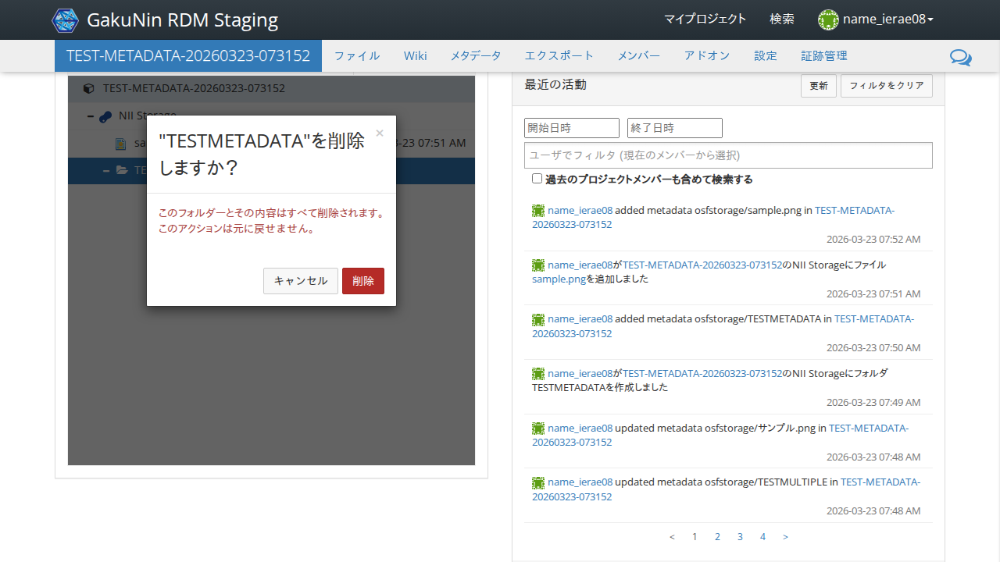

In [ ]:
async def _step(page):
    if not foldername:
        return
    await page.locator('//i[contains(@class, "fa-trash")]/../*[text() = "フォルダを削除"]').click()
    locator = page.locator('//*[@id = "tb-tbody"]//*[@class = "modal-content"]//*[contains(@class, "btn-danger")]')
    await locator.scroll_into_view_if_needed()
    await expect(locator).to_be_enabled(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「削除」をクリックする

TESTMETADATAが削除されること

Start epoch: 1774252475.3620925 seconds


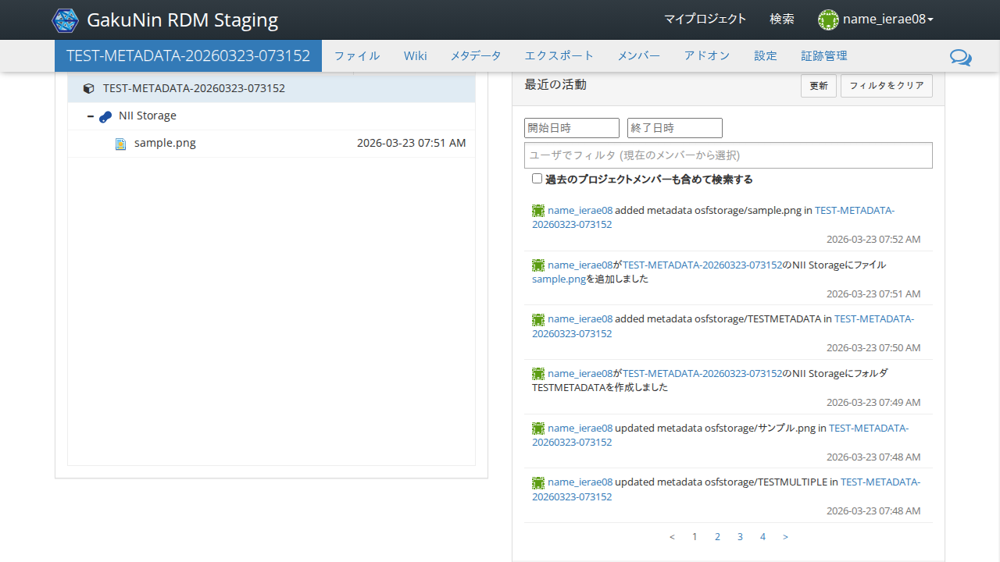

In [ ]:
async def _step(page):
    if not foldername:
        return
    await page.locator('//*[@id = "tb-tbody"]//*[@class = "modal-content"]//*[contains(@class, "btn-danger")]').click()
    await expect(grdm.get_select_folder_title_locator(page, foldername)).to_have_count(0, timeout=transition_timeout)
    time.sleep(1)
    await page.locator('//*[contains(@class, "title-text")]//*[text() = "NII Storage"]').scroll_into_view_if_needed()

await run_pw(_step)

## 「sample.png」のアイコンをクリックする

「削除」ボタンが表示されること

Start epoch: 1774252478.8755918 seconds


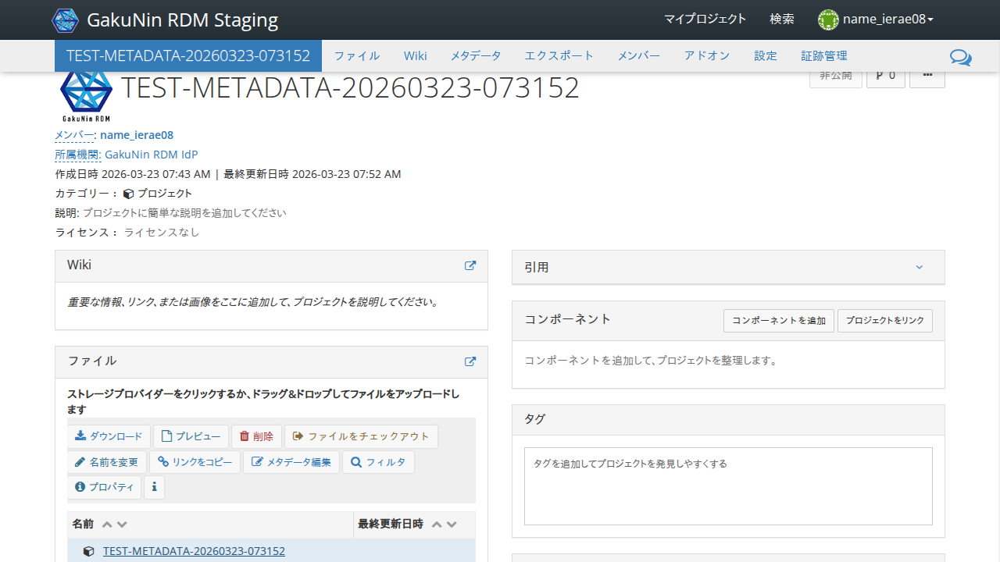

In [ ]:
filename = 'sample.png'
async def _step(page):
    global filename
    locator = grdm.get_select_file_extension_locator(page, filename)
    if not await locator.is_visible():
        filename = None
        return
    await locator.click()
    await expect(page.locator('//*[contains(@class, "btn-danger") and text() = "削除"]').first).to_be_enabled(timeout=transition_timeout)

await run_pw(_step)

## 「削除」をクリックする

「"sample.png"を削除しますか？」のダイアログが表示されること

Start epoch: 1774252481.1180527 seconds


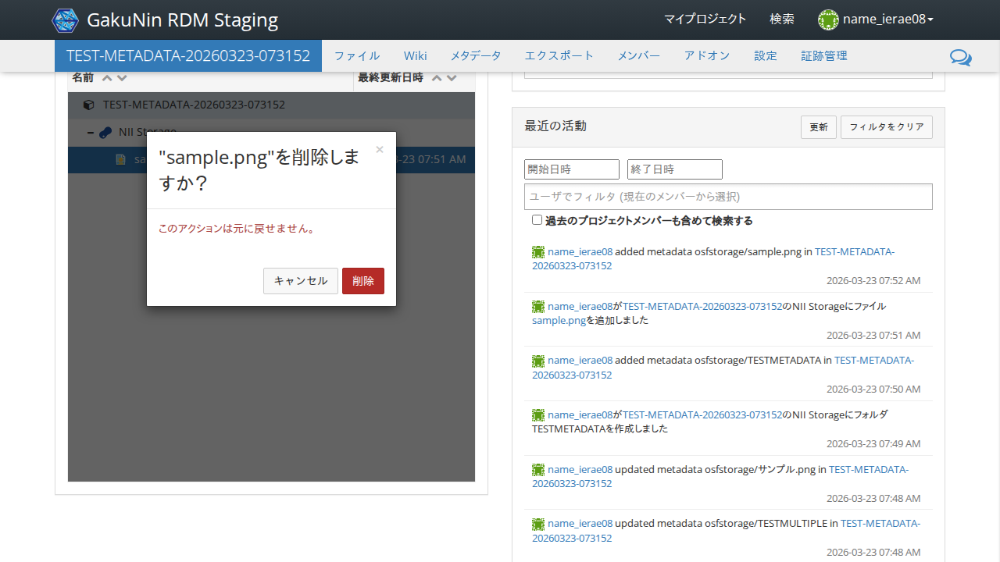

In [ ]:
async def _step(page):
    if not filename:
        return
    await page.locator('//i[contains(@class, "fa-trash")]/../*[text() = "削除"]').click()
    locator = page.locator('//*[@id = "tb-tbody"]//*[@class = "modal-content"]//*[contains(@class, "btn-danger")]')
    await locator.scroll_into_view_if_needed()
    await expect(locator).to_be_enabled(timeout=transition_timeout)
    time.sleep(1)

await run_pw(_step)

## 「削除」をクリックする

sample.pngが削除されること

Start epoch: 1774252484.3311155 seconds


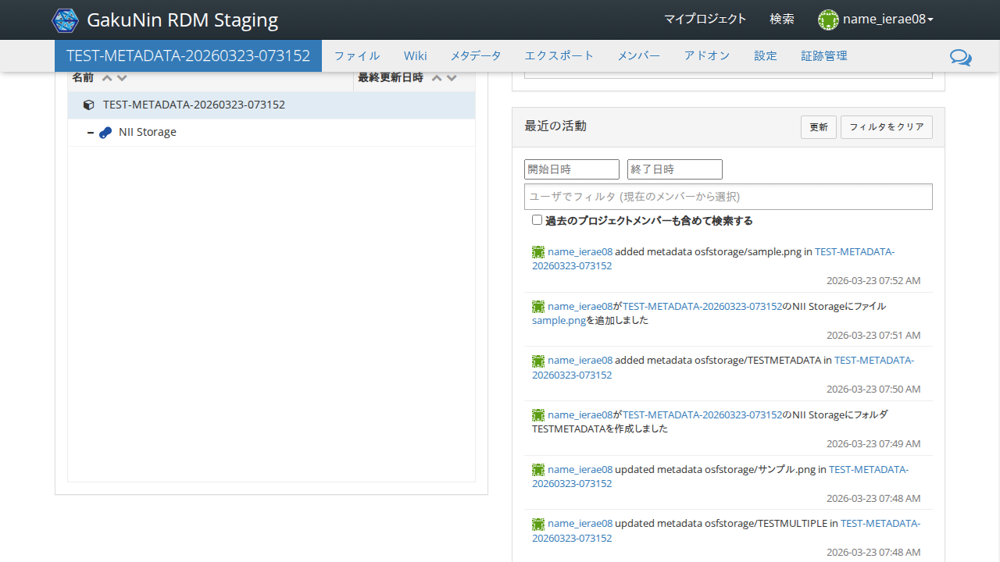

In [ ]:
async def _step(page):
    if not filename:
        return
    await page.locator('//*[@id = "tb-tbody"]//*[@class = "modal-content"]//*[contains(@class, "btn-danger")]').click()
    await expect(grdm.get_select_file_title_locator(page, filename)).to_have_count(0, timeout=transition_timeout)
    time.sleep(1)
    await page.locator('//*[contains(@class, "title-text")]//*[text() = "NII Storage"]').scroll_into_view_if_needed()

await run_pw(_step)

## (指定がある場合) プロジェクトを削除する

Start epoch: 1774252496.0689805 seconds
Massie


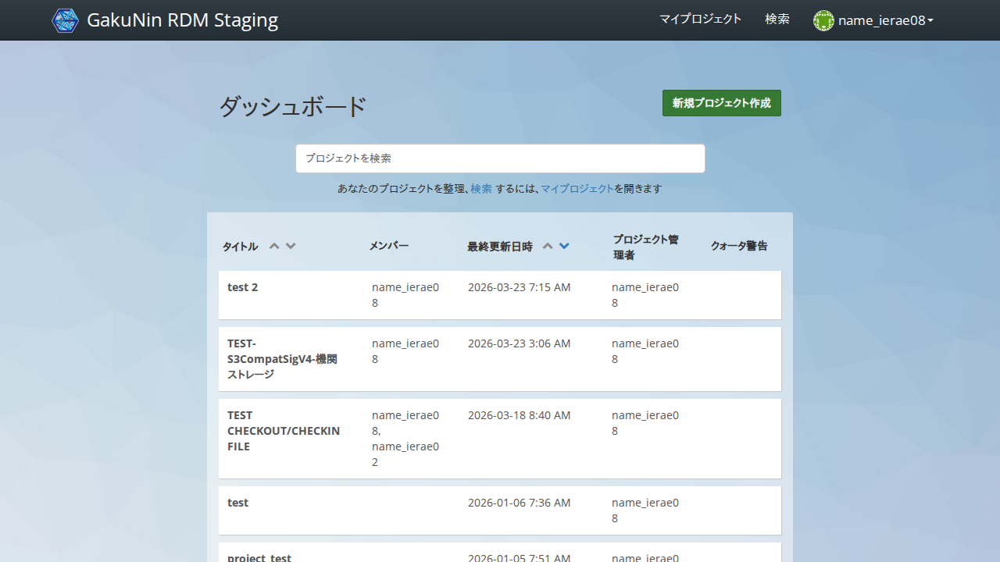

In [ ]:
async def _step(page):
    if not delete_project:
        return
    await scripts.grdm.delete_project(page)
    
    await expect(page.locator('//*[text() = "プロジェクト管理者"]')).to_be_visible(timeout=transition_timeout)

await run_pw(_step)

In [162]:
await finish_pw_context()

Video: result/result-20260323-073151/取りまとめ-Metadataアドオン/notebooks/テスト手順-Metadataアドオン-eRad情報を用いた自動補完/video-1.webm
Video: result/result-20260323-073151/取りまとめ-Metadataアドオン/notebooks/テスト手順-Metadataアドオン-eRad情報を用いた自動補完/video-2.webm
HAR: result/result-20260323-073151/取りまとめ-Metadataアドオン/notebooks/テスト手順-Metadataアドオン-eRad情報を用いた自動補完/har.zip
Console: result/result-20260323-073151/取りまとめ-Metadataアドオン/notebooks/テスト手順-Metadataアドオン-eRad情報を用いた自動補完/console.log


スクリーンキャプチャ動画の取得に失敗しました。
Traceback (most recent call last):
  File "/home/jovyan/scripts/playwright.py", line 199, in _finish_pw_context
    shutil.copyfile(video_path, dest_video_path)
  File "/opt/conda/lib/python3.12/shutil.py", line 260, in copyfile
    with open(src, 'rb') as fsrc:
         ^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: '/tmp/tmpqm5ltgix/videos/68761618b53d8e9d7f9db1f2c8b0d1ac.webm'
スクリーンキャプチャ動画の取得に失敗しました。
Traceback (most recent call last):
  File "/home/jovyan/scripts/playwright.py", line 199, in _finish_pw_context
    shutil.copyfile(video_path, dest_video_path)
  File "/opt/conda/lib/python3.12/shutil.py", line 260, in copyfile
    with open(src, 'rb') as fsrc:
         ^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: '/tmp/tmpqm5ltgix/videos/4c4cf4063e448c9a22fd49c2be301119.webm'


In [163]:
!rm -fr {work_dir}